In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

HAM_ROOT = Path(
    "/content/drive/My Drive/Skin_Cancer_FYP/datasets/HAM10000"
)

print("HAM10000 exists:", HAM_ROOT.exists())
print("\nContents:")

for item in sorted(HAM_ROOT.iterdir()):
    if item.is_dir():
        print(f"[DIR]  {item.name}")
    else:
        print(f"[FILE] {item.name}")

HAM10000 exists: True

Contents:
[DIR]  HAM10000_images_part_1
[DIR]  HAM10000_images_part_2
[FILE] HAM10000_metadata.csv
[FILE] hmnist_28_28_L.csv
[FILE] hmnist_28_28_RGB.csv
[FILE] hmnist_8_8_L.csv
[FILE] hmnist_8_8_RGB.csv


In [ ]:
import pandas as pd

metadata_path = HAM_ROOT / "HAM10000_metadata.csv"

df = pd.read_csv(metadata_path)

print("Metadata shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nClass distribution:")
display(df["dx"].value_counts())

print("\nMissing values:")
display(df.isnull().sum())

Metadata shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Class distribution:


,count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115



Missing values:


,0
lesion_id,0
image_id,0
dx,0
dx_type,0
age,57
sex,0
localization,0


In [ ]:
# ============================================================
# STEP 1: Inspect lesion-level grouping
# ============================================================

print("Total images:", len(df))

print("Unique lesions:", df["lesion_id"].nunique())

print(
    "Images per lesion - mean:",
    df.groupby("lesion_id").size().mean()
)

print(
    "Images per lesion - median:",
    df.groupby("lesion_id").size().median()
)

print(
    "Images per lesion - maximum:",
    df.groupby("lesion_id").size().max()
)

print("\nNumber of lesions by number of images:")

lesion_sizes = df.groupby("lesion_id").size()

display(
    lesion_sizes.value_counts()
    .sort_index()
    .rename_axis("images_per_lesion")
    .reset_index(name="number_of_lesions")
)

Total images: 10015
Unique lesions: 7470
Images per lesion - mean: 1.3406961178045516
Images per lesion - median: 1.0
Images per lesion - maximum: 6

Number of lesions by number of images:


,images_per_lesion,number_of_lesions
0,1,5514
1,2,1423
2,3,490
3,4,34
4,5,5
5,6,4


In [ ]:
# ============================================================
# STEP 2: Check diagnostic-label consistency within lesions
# ============================================================

labels_per_lesion = (
    df.groupby("lesion_id")["dx"]
      .nunique()
)

print(
    "Lesions with exactly one diagnostic label:",
    (labels_per_lesion == 1).sum()
)

print(
    "Lesions with MORE than one diagnostic label:",
    (labels_per_lesion > 1).sum()
)

print("\nLesions with multiple labels:")

multi_label_lesions = labels_per_lesion[labels_per_lesion > 1]

display(multi_label_lesions.head(20))

Lesions with exactly one diagnostic label: 7470
Lesions with MORE than one diagnostic label: 0

Lesions with multiple labels:


,dx
lesion_id,


In [ ]:
# ============================================================
# STEP 3: Verify all image files
# ============================================================

image_dirs = [
    HAM_ROOT / "HAM10000_images_part_1",
    HAM_ROOT / "HAM10000_images_part_2"
]

image_files = []

for image_dir in image_dirs:
    files = list(image_dir.glob("*.jpg"))
    print(f"{image_dir.name}: {len(files)} JPG files")
    image_files.extend(files)

print("\nTotal JPG files found:", len(image_files))

# Create a set of image IDs from filenames
available_image_ids = {
    path.stem for path in image_files
}

metadata_image_ids = set(df["image_id"])

missing_images = metadata_image_ids - available_image_ids
extra_images = available_image_ids - metadata_image_ids

print("Images in metadata but missing from folders:", len(missing_images))
print("Images in folders but missing from metadata:", len(extra_images))

if missing_images:
    print("\nFirst missing images:")
    print(list(missing_images)[:10])

if extra_images:
    print("\nFirst extra images:")
    print(list(extra_images)[:10])

HAM10000_images_part_1: 5000 JPG files
HAM10000_images_part_2: 5015 JPG files

Total JPG files found: 10015
Images in metadata but missing from folders: 0
Images in folders but missing from metadata: 0


In [ ]:
!pip install -q iterative-stratification

In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

print("iterative-stratification imported successfully.")

iterative-stratification imported successfully.


In [ ]:
# ============================================================
# STEP 4B: Lesion-level class distribution
# ============================================================

lesion_df = (
    df[["lesion_id", "dx"]]
    .drop_duplicates()
    .copy()
)

print("Total unique lesions:", len(lesion_df))

print("\nLesion-level class distribution:")

lesion_class_counts = (
    lesion_df["dx"]
    .value_counts()
    .sort_index()
)

display(
    lesion_class_counts
    .rename_axis("dx")
    .reset_index(name="lesion_count")
)

print("\nLesion-level class percentages:")

lesion_class_percent = (
    lesion_df["dx"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(
    lesion_class_percent
    .round(2)
    .rename_axis("dx")
    .reset_index(name="percentage")
)

Total unique lesions: 7470

Lesion-level class distribution:


,dx,lesion_count
0,akiec,228
1,bcc,327
2,bkl,727
3,df,73
4,mel,614
5,nv,5403
6,vasc,98



Lesion-level class percentages:


,dx,percentage
0,akiec,3.05
1,bcc,4.38
2,bkl,9.73
3,df,0.98
4,mel,8.22
5,nv,72.33
6,vasc,1.31


In [ ]:
# ============================================================
# CORRECTED STEP 5:
# Approximately 70% train / 15% validation / 15% test
# with lesion-level grouping and stratification
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

# One row per lesion
lesions = (
    df[["lesion_id", "dx"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total lesions:", len(lesions))

# ------------------------------------------------------------
# Create 20 approximately equal stratified group folds.
#
# 14 folds  -> approximately 70%
# 3 folds   -> approximately 15%
# 3 folds   -> approximately 15%
# ------------------------------------------------------------

sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=SEED
)

fold_assignments = np.empty(len(lesions), dtype=int)

for fold, (_, fold_idx) in enumerate(
    sgkf.split(
        X=lesions,
        y=lesions["dx"],
        groups=lesions["lesion_id"]
    )
):
    fold_assignments[fold_idx] = fold

lesions["fold"] = fold_assignments

# ------------------------------------------------------------
# Assign folds to splits
# ------------------------------------------------------------

train_folds = set(range(0, 14))
val_folds = set(range(14, 17))
test_folds = set(range(17, 20))

lesions["split"] = lesions["fold"].apply(
    lambda x:
        "train" if x in train_folds
        else "val" if x in val_folds
        else "test"
)

print("\nLesion-level split:")
print(lesions["split"].value_counts())

print("\nLesion-level percentages:")
print(
    (lesions["split"].value_counts(normalize=True) * 100)
    .round(2)
)

Total lesions: 7470

Lesion-level split:
split
train    5230
val      1120
test     1120
Name: count, dtype: int64

Lesion-level percentages:
split
train    70.01
val      14.99
test     14.99
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# STEP 6: Check lesion-level class distribution
# ============================================================

lesion_distribution = (
    pd.crosstab(
        lesions["dx"],
        lesions["split"]
    )
)

print("Lesion counts by class and split:")
display(lesion_distribution)

print("\nLesion percentages within each split:")

lesion_percentages = (
    lesion_distribution
    .div(lesion_distribution.sum(axis=0), axis=1)
    * 100
)

display(lesion_percentages.round(2))

Lesion counts by class and split:


split,test,train,val
dx,,,
akiec,31,159,38
bcc,45,236,46
bkl,92,505,130
df,9,50,14
mel,100,411,103
nv,833,3796,774
vasc,10,73,15



Lesion percentages within each split:


split,test,train,val
dx,,,
akiec,2.77,3.04,3.39
bcc,4.02,4.51,4.11
bkl,8.21,9.66,11.61
df,0.80,0.96,1.25
mel,8.93,7.86,9.20
nv,74.38,72.58,69.11
vasc,0.89,1.40,1.34


In [ ]:
# ============================================================
# STEP 7: Assign every image to its lesion's split
# ============================================================

lesion_to_split = dict(
    zip(
        lesions["lesion_id"],
        lesions["split"]
    )
)

split_df = df.copy()

split_df["split"] = split_df["lesion_id"].map(
    lesion_to_split
)

# Safety check
assert split_df["split"].notna().all()

print("Image counts:")
print(split_df["split"].value_counts())

print("\nImage-level class distribution:")
display(
    pd.crosstab(
        split_df["dx"],
        split_df["split"]
    )
)

Image counts:
split
train    6991
test     1533
val      1491
Name: count, dtype: int64

Image-level class distribution:


split,test,train,val
dx,,,
akiec,46,228,53
bcc,72,362,80
bkl,146,755,198
df,15,78,22
mel,179,738,196
nv,1060,4725,920
vasc,15,105,22


In [ ]:
# ============================================================
# STEP 8: Final leakage verification
# ============================================================

train_ids = set(
    split_df.loc[
        split_df["split"] == "train",
        "lesion_id"
    ]
)

val_ids = set(
    split_df.loc[
        split_df["split"] == "val",
        "lesion_id"
    ]
)

test_ids = set(
    split_df.loc[
        split_df["split"] == "test",
        "lesion_id"
    ]
)

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\n✓ ZERO LESION LEAKAGE CONFIRMED")

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✓ ZERO LESION LEAKAGE CONFIRMED


In [ ]:
# ============================================================
# STEP 9: Final split proportions
# ============================================================

print("IMAGE-LEVEL SPLIT")
print("=" * 50)

image_counts = split_df["split"].value_counts()

for split in ["train", "val", "test"]:
    count = image_counts[split]
    percentage = 100 * count / len(split_df)

    print(
        f"{split:>5}: "
        f"{count:5d} images "
        f"({percentage:6.2f}%)"
    )

print("\nLESION-LEVEL SPLIT")
print("=" * 50)

lesion_counts = lesions["split"].value_counts()

for split in ["train", "val", "test"]:
    count = lesion_counts[split]
    percentage = 100 * count / len(lesions)

    print(
        f"{split:>5}: "
        f"{count:5d} lesions "
        f"({percentage:6.2f}%)"
    )

IMAGE-LEVEL SPLIT
train:  6991 images ( 69.81%)
  val:  1491 images ( 14.89%)
 test:  1533 images ( 15.31%)

LESION-LEVEL SPLIT
train:  5230 lesions ( 70.01%)
  val:  1120 lesions ( 14.99%)
 test:  1120 lesions ( 14.99%)


In [ ]:
# ============================================================
# SAVE MASTER SPLIT
# ============================================================

SPLIT_PATH = HAM_ROOT / "HAM10000_master_split.csv"

split_df.to_csv(
    SPLIT_PATH,
    index=False
)

print("✓ Master split saved successfully")
print("\nPath:")
print(SPLIT_PATH)

print("\nRows:", len(split_df))
print("Columns:", split_df.columns.tolist())

✓ Master split saved successfully

Path:
/content/drive/My Drive/Skin_Cancer_FYP/datasets/HAM10000/HAM10000_master_split.csv

Rows: 10015
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'split']


In [ ]:
print("File exists:", SPLIT_PATH.exists())
print("File size:", f"{SPLIT_PATH.stat().st_size / 1024:.1f} KB")

File exists: True
File size: 604.4 KB


In [ ]:
# ============================================================
# STEP 11A: Check image-processing libraries
# ============================================================

import cv2
import scipy
import PIL
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("SciPy:", scipy.__version__)
print("Pillow:", PIL.__version__)
print("NumPy:", np.__version__)

print("\n✓ Image-processing environment ready.")

OpenCV: 5.0.0
SciPy: 1.16.3
Pillow: 11.3.0
NumPy: 2.1.3

✓ Image-processing environment ready.


In [ ]:
# ============================================================
# STEP 11B: Deterministic preprocessing functions
# ============================================================

import cv2
import numpy as np
from scipy.signal import wiener


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID = (8, 8)

WIENER_KERNEL = (5, 5)

IMAGE_SIZE = (224, 224)

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


# ------------------------------------------------------------
# RGB conversion
# ------------------------------------------------------------

def load_rgb(image_path):
    """
    Load an image from disk and return RGB uint8 format.
    """
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    return image


# ------------------------------------------------------------
# CLAHE
# Applied to L-channel in LAB colour space
# ------------------------------------------------------------

def apply_clahe(image_rgb):
    """
    Apply CLAHE to the L-channel of LAB.

    Input:
        RGB uint8 image

    Output:
        RGB uint8 image
    """

    lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=CLAHE_CLIP_LIMIT,
        tileGridSize=CLAHE_TILE_GRID
    )

    l_enhanced = clahe.apply(l_channel)

    lab_enhanced = cv2.merge(
        [l_enhanced, a_channel, b_channel]
    )

    rgb_enhanced = cv2.cvtColor(
        lab_enhanced,
        cv2.COLOR_LAB2RGB
    )

    return rgb_enhanced


# ------------------------------------------------------------
# Wiener filtering
# ------------------------------------------------------------

def apply_wiener(image_rgb):
    """
    Apply a 5x5 Wiener filter independently to each RGB channel.

    Input:
        RGB uint8 image

    Output:
        RGB uint8 image
    """

    image_float = image_rgb.astype(np.float32)

    filtered_channels = []

    for channel in range(3):

        filtered = wiener(
            image_float[:, :, channel],
            mysize=WIENER_KERNEL
        )

        filtered_channels.append(filtered)

    filtered_image = np.stack(
        filtered_channels,
        axis=2
    )

    filtered_image = np.nan_to_num(
        filtered_image,
        nan=0.0,
        posinf=255.0,
        neginf=0.0
    )

    filtered_image = np.clip(
        filtered_image,
        0,
        255
    ).astype(np.uint8)

    return filtered_image


# ------------------------------------------------------------
# Resize
# ------------------------------------------------------------

def resize_image(image_rgb):
    """
    Resize RGB image to 224 x 224.
    """

    return cv2.resize(
        image_rgb,
        IMAGE_SIZE,
        interpolation=cv2.INTER_AREA
    )


# ------------------------------------------------------------
# Complete deterministic pipeline
# ------------------------------------------------------------

def preprocess_deterministic(
    image_path,
    use_clahe=True,
    use_wiener=True
):
    """
    Deterministic preprocessing pipeline.

    Allows the four ablation conditions:

        1. Raw
        2. CLAHE only
        3. Wiener only
        4. CLAHE + Wiener

    Returns:
        RGB uint8 image at 224x224.
    """

    image = load_rgb(image_path)

    if use_clahe:
        image = apply_clahe(image)

    if use_wiener:
        image = apply_wiener(image)

    image = resize_image(image)

    return image


print("✓ Preprocessing functions defined.")
print("\nConfiguration:")
print(f"CLAHE clip limit: {CLAHE_CLIP_LIMIT}")
print(f"CLAHE grid: {CLAHE_TILE_GRID}")
print(f"Wiener kernel: {WIENER_KERNEL}")
print(f"Output size: {IMAGE_SIZE}")

✓ Preprocessing functions defined.

Configuration:
CLAHE clip limit: 2.0
CLAHE grid: (8, 8)
Wiener kernel: (5, 5)
Output size: (224, 224)


In [ ]:
# ============================================================
# STEP 11C: Locate a real HAM10000 image
# ============================================================

sample_image_id = df.iloc[0]["image_id"]

image_path_1 = (
    HAM_ROOT
    / "HAM10000_images_part_1"
    / f"{sample_image_id}.jpg"
)

image_path_2 = (
    HAM_ROOT
    / "HAM10000_images_part_2"
    / f"{sample_image_id}.jpg"
)

if image_path_1.exists():
    SAMPLE_IMAGE_PATH = image_path_1
elif image_path_2.exists():
    SAMPLE_IMAGE_PATH = image_path_2
else:
    raise FileNotFoundError(
        f"Could not find {sample_image_id}"
    )

print("Sample image ID:", sample_image_id)
print("Path:", SAMPLE_IMAGE_PATH)

Sample image ID: ISIC_0027419
Path: /content/drive/My Drive/Skin_Cancer_FYP/datasets/HAM10000/HAM10000_images_part_1/ISIC_0027419.jpg


In [ ]:
# ============================================================
# STEP 11D: Compare the four preprocessing conditions
# ============================================================

original = load_rgb(SAMPLE_IMAGE_PATH)

raw = preprocess_deterministic(
    SAMPLE_IMAGE_PATH,
    use_clahe=False,
    use_wiener=False
)

clahe_only = preprocess_deterministic(
    SAMPLE_IMAGE_PATH,
    use_clahe=True,
    use_wiener=False
)

wiener_only = preprocess_deterministic(
    SAMPLE_IMAGE_PATH,
    use_clahe=False,
    use_wiener=True
)

clahe_wiener = preprocess_deterministic(
    SAMPLE_IMAGE_PATH,
    use_clahe=True,
    use_wiener=True
)

print("Original shape:", original.shape)
print("Processed shape:", raw.shape)

print("\n✓ All four preprocessing conditions completed.")

Original shape: (450, 600, 3)
Processed shape: (224, 224, 3)

✓ All four preprocessing conditions completed.


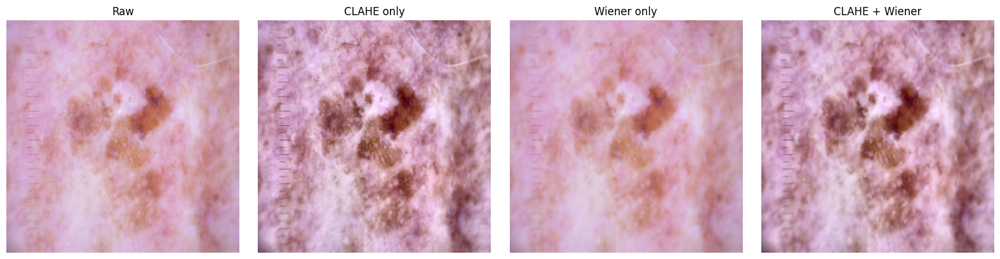

In [ ]:
# ============================================================
# STEP 11E: Visual inspection
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [
    raw,
    clahe_only,
    wiener_only,
    clahe_wiener
]

titles = [
    "Raw",
    "CLAHE only",
    "Wiener only",
    "CLAHE + Wiener"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 12: Benchmark preprocessing speed
# ============================================================

import time
import random

# Select 50 images from the metadata
benchmark_rows = df.sample(
    n=50,
    random_state=42
)

benchmark_paths = []

for image_id in benchmark_rows["image_id"]:

    p1 = HAM_ROOT / "HAM10000_images_part_1" / f"{image_id}.jpg"
    p2 = HAM_ROOT / "HAM10000_images_part_2" / f"{image_id}.jpg"

    if p1.exists():
        benchmark_paths.append(p1)
    elif p2.exists():
        benchmark_paths.append(p2)
    else:
        raise FileNotFoundError(image_id)


def benchmark_condition(use_clahe, use_wiener):

    start = time.perf_counter()

    for path in benchmark_paths:
        preprocess_deterministic(
            path,
            use_clahe=use_clahe,
            use_wiener=use_wiener
        )

    elapsed = time.perf_counter() - start

    return elapsed


conditions = {
    "Raw": (False, False),
    "CLAHE": (True, False),
    "Wiener": (False, True),
    "CLAHE + Wiener": (True, True)
}

benchmark_results = []

for name, (clahe, wiener_flag) in conditions.items():

    elapsed = benchmark_condition(
        use_clahe=clahe,
        use_wiener=wiener_flag
    )

    benchmark_results.append({
        "condition": name,
        "total_seconds": elapsed,
        "seconds_per_image": elapsed / len(benchmark_paths),
        "images_per_second": len(benchmark_paths) / elapsed
    })

benchmark_results = pd.DataFrame(benchmark_results)

display(benchmark_results)

,condition,total_seconds,seconds_per_image,images_per_second
0,Raw,64.901559,1.298031,0.770398
1,CLAHE,1.086663,0.021733,46.012443
2,Wiener,4.072049,0.081441,12.278829
3,CLAHE + Wiener,4.326365,0.086527,11.557045


In [ ]:
# ============================================================
# STEP 12B: Cleaner preprocessing benchmark
# ============================================================

import time
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Load the 50 benchmark images into memory first.
# This removes most disk I/O differences between conditions.
# ------------------------------------------------------------

benchmark_images = []

for path in benchmark_paths:
    benchmark_images.append(load_rgb(path))

print(f"Loaded {len(benchmark_images)} images into memory.")
print("Image shape:", benchmark_images[0].shape)


# ------------------------------------------------------------
# Benchmark functions operating on already-loaded images
# ------------------------------------------------------------

def preprocess_array(
    image_rgb,
    use_clahe=True,
    use_wiener=True
):
    image = image_rgb.copy()

    if use_clahe:
        image = apply_clahe(image)

    if use_wiener:
        image = apply_wiener(image)

    image = resize_image(image)

    return image


def benchmark_array_condition(
    use_clahe,
    use_wiener
):
    start = time.perf_counter()

    for image in benchmark_images:
        preprocess_array(
            image,
            use_clahe=use_clahe,
            use_wiener=use_wiener
        )

    elapsed = time.perf_counter() - start

    return {
        "total_seconds": elapsed,
        "seconds_per_image": elapsed / len(benchmark_images),
        "images_per_second": len(benchmark_images) / elapsed
    }


conditions = {
    "Raw": (False, False),
    "CLAHE": (True, False),
    "Wiener": (False, True),
    "CLAHE + Wiener": (True, True)
}

results = []

for name, (clahe_flag, wiener_flag) in conditions.items():

    result = benchmark_array_condition(
        clahe_flag,
        wiener_flag
    )

    result["condition"] = name
    results.append(result)


clean_benchmark = pd.DataFrame(results)

clean_benchmark = clean_benchmark[
    [
        "condition",
        "total_seconds",
        "seconds_per_image",
        "images_per_second"
    ]
]

display(clean_benchmark)

Loaded 50 images into memory.
Image shape: (450, 600, 3)


,condition,total_seconds,seconds_per_image,images_per_second
0,Raw,0.231130,0.004623,216.328386
1,CLAHE,0.409805,0.008196,122.009313
2,Wiener,3.469354,0.069387,14.411905
3,CLAHE + Wiener,5.141791,0.102836,9.724239


In [ ]:
# ============================================================
# STEP 13: PROJECT PATH SETUP
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# Google Drive project root
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/My Drive/Skin_Cancer_FYP"
)

# ------------------------------------------------------------
# Dataset paths
# ------------------------------------------------------------

DATASET_ROOT = (
    PROJECT_ROOT / "datasets"
)

HAM_ROOT = (
    DATASET_ROOT / "HAM10000"
)

# ------------------------------------------------------------
# Important dataset files
# ------------------------------------------------------------

METADATA_PATH = (
    HAM_ROOT / "HAM10000_metadata.csv"
)

SPLIT_PATH = (
    HAM_ROOT / "HAM10000_master_split.csv"
)

# ------------------------------------------------------------
# Preprocessing cache
# ------------------------------------------------------------

CACHE_ROOT = (
    PROJECT_ROOT / "preprocessing_cache"
)

# ------------------------------------------------------------
# Checkpoints and results
# ------------------------------------------------------------

CHECKPOINT_ROOT = (
    PROJECT_ROOT / "checkpoints"
)

RESULTS_ROOT = (
    PROJECT_ROOT / "results"
)

LOG_ROOT = (
    PROJECT_ROOT / "logs"
)

# ------------------------------------------------------------
# Create directories
# ------------------------------------------------------------

for path in [
    PROJECT_ROOT,
    DATASET_ROOT,
    HAM_ROOT,
    CACHE_ROOT,
    CHECKPOINT_ROOT,
    RESULTS_ROOT,
    LOG_ROOT,
]:
    path.mkdir(
        parents=True,
        exist_ok=True
    )

print("✓ Project paths configured")
print()
print("PROJECT_ROOT:")
print(PROJECT_ROOT)
print()
print("HAM_ROOT:")
print(HAM_ROOT)
print()
print("SPLIT_PATH:")
print(SPLIT_PATH)
print()
print("CACHE_ROOT:")
print(CACHE_ROOT)

✓ Project paths configured

PROJECT_ROOT:
/content/drive/My Drive/Skin_Cancer_FYP

HAM_ROOT:
/content/drive/My Drive/Skin_Cancer_FYP/datasets/HAM10000

SPLIT_PATH:
/content/drive/My Drive/Skin_Cancer_FYP/datasets/HAM10000/HAM10000_master_split.csv

CACHE_ROOT:
/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache


In [ ]:
# ============================================================
# STEP 13B: LOAD AND VERIFY MASTER SPLIT
# ============================================================

import pandas as pd

assert SPLIT_PATH.exists(), (
    f"Master split not found: {SPLIT_PATH}"
)

split_df = pd.read_csv(SPLIT_PATH)

print("✓ Master split loaded")
print()
print("Rows:", len(split_df))
print("Columns:", split_df.columns.tolist())

print("\nSplit counts:")
print(split_df["split"].value_counts())

print("\nUnique lesions by split:")

for split in ["train", "val", "test"]:
    count = split_df.loc[
        split_df["split"] == split,
        "lesion_id"
    ].nunique()

    print(f"{split:>5}: {count}")

✓ Master split loaded

Rows: 10015
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'split']

Split counts:
split
train    6991
test     1533
val      1491
Name: count, dtype: int64

Unique lesions by split:
train: 5230
  val: 1120
 test: 1120


In [ ]:
# ============================================================
# MASTER SETUP v2: With Self-Healing Splitting Logic
# ============================================================
import os
import pandas as pd
import numpy as np
import cv2
import torch
from pathlib import Path
from PIL import Image
from scipy.signal import wiener
from google.colab import drive
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.model_selection import StratifiedGroupKFold

# 1. Robust Drive Mount
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')
else:
    print("✓ Drive already mounted.")

# 2. Path Configuration (Verified from your .py file)
PROJECT_ROOT  = Path("/content/drive/My Drive/Skin_Cancer_FYP")
DATASET_ROOT  = PROJECT_ROOT / "datasets"
HAM_ROOT      = DATASET_ROOT / "HAM10000"
METADATA_PATH = HAM_ROOT / "HAM10000_metadata.csv"
SPLIT_PATH    = HAM_ROOT / "HAM10000_master_split.csv"
CACHE_ROOT    = PROJECT_ROOT / "preprocessing_cache"

# Create directories
for p in [PROJECT_ROOT, DATASET_ROOT, HAM_ROOT, CACHE_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

# 3. SELF-HEALING: Load or Recreate Split
if SPLIT_PATH.exists():
    split_df = pd.read_csv(SPLIT_PATH)
    print(f"✓ Master split loaded from Drive ({len(split_df)} images).")
else:
    print("⚠️ Master split not found. Recreating from metadata...")
    if not METADATA_PATH.exists():
        raise FileNotFoundError(f"CRITICAL: Could not find metadata at {METADATA_PATH}. Check your Drive folders!")

    df = pd.read_csv(METADATA_PATH)
    SEED = 42
    # Logic from your .py file
    lesions = df[["lesion_id", "dx"]].drop_duplicates().reset_index(drop=True)
    sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
    fold_assignments = np.empty(len(lesions), dtype=int)
    for fold, (_, fold_idx) in enumerate(sgkf.split(X=lesions, y=lesions["dx"], groups=lesions["lesion_id"])):
        fold_assignments[fold_idx] = fold

    lesions["fold"] = fold_assignments
    train_folds, val_folds = set(range(0, 14)), set(range(14, 17))
    lesions["split"] = lesions["fold"].apply(lambda x: "train" if x in train_folds else "val" if x in val_folds else "test")

    lesion_to_split = dict(zip(lesions["lesion_id"], lesions["split"]))
    split_df = df.copy()
    split_df["split"] = split_df["lesion_id"].map(lesion_to_split)

    # Save permanently
    split_df.to_csv(SPLIT_PATH, index=False)
    print(f"✓ Master split recreated and SAVED to Drive: {SPLIT_PATH}")

# 4. Image Lookup Table
image_lookup = {}
# Check both possible part folders
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    img_dir = HAM_ROOT / part
    if img_dir.exists():
        for path in img_dir.glob("*.jpg"):
            image_lookup[path.stem] = path

print(f"✓ Image lookup built ({len(image_lookup)} images found).")
if len(image_lookup) == 0:
    print("⚠️ WARNING: No images found! Check if 'HAM10000_images_part_1' exists inside HAM10000 folder.")

# 5. Constants & Device
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 6. Preprocessing & Dataset Class (Same as before)
def preprocess_deterministic(image_path, use_clahe=True, use_wiener=True):
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if use_clahe:
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        l = clahe.apply(l)
        img = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)
    if use_wiener:
        img = img.astype(np.float32)
        channels = [wiener(img[:,:,i], mysize=(5,5)) for i in range(3)]
        img = np.clip(np.stack(channels, axis=2), 0, 255).astype(np.uint8)
    return cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, condition="clahe_wiener", transform=None, cache=True):
        self.df = dataframe.reset_index(drop=True)
        self.condition, self.transform, self.cache = condition, transform, cache
        self.image_dir = CACHE_ROOT / condition if cache else None
    def __len__(self): return len(self.df)
    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        if self.cache:
            img_path = self.image_dir / f"{img_id}.png"
            if not img_path.exists(): # Fallback if cache not generated yet
                return preprocess_deterministic(image_lookup[img_id]), label
        else:
            img_path = image_lookup[img_id]
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

# Fixed the .upper() error here:
print(f"\n--- ENVIRONMENT READY ON {str(device).upper()} ---")

✓ Drive already mounted.
✓ Master split loaded from Drive (10015 images).
✓ Image lookup built (10015 images found).

--- ENVIRONMENT READY ON CUDA ---


In [ ]:
from google.colab import drive
import os

# 1. Flush and unmount properly using Colab's built-in method
drive.flush_and_unmount()

# 2. Delete the broken ghost directory causing the "already contains files" error
!rm -rf /content/drive

# 3. Mount fresh
drive.mount('/content/drive')

# 4. Verify path immediately
path_to_check = "/content/drive/My Drive/Skin_Cancer_FYP/datasets/HAM10000/HAM10000_metadata.csv"
if os.path.exists(path_to_check):
    print("\n✅ FOUND IT! Sync successful.")
else:
    print("\n❌ Still not seeing it. Try clicking the 'Folder' icon on the left sidebar in Colab.")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive

✅ FOUND IT! Sync successful.


In [ ]:
# ============================================================
# STEP 13C: PREPROCESSING CACHE DIRECTORIES
# ============================================================

CACHE_CONDITIONS = [
    "raw",
    "clahe",
    "wiener",
    "clahe_wiener"
]

for condition in CACHE_CONDITIONS:

    condition_path = (
        CACHE_ROOT / condition
    )

    condition_path.mkdir(
        parents=True,
        exist_ok=True
    )

    print(
        f"{condition:15s} -> {condition_path}"
    )

print("\n✓ Cache structure ready")

raw             -> /content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/raw
clahe           -> /content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe
wiener          -> /content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/wiener
clahe_wiener    -> /content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener

✓ Cache structure ready


In [ ]:
# ============================================================
# STEP 13D: IMAGE LOOKUP
# ============================================================

image_lookup = {}

for image_dir in [
    HAM_ROOT / "HAM10000_images_part_1",
    HAM_ROOT / "HAM10000_images_part_2"
]:

    for path in image_dir.glob("*.jpg"):
        image_lookup[path.stem] = path

print("Indexed images:", len(image_lookup))

assert len(image_lookup) == 10015

missing = (
    set(split_df["image_id"])
    - set(image_lookup.keys())
)

print("Missing images:", len(missing))

assert len(missing) == 0

print("\n✓ All 10,015 images available")

Indexed images: 10015
Missing images: 0

✓ All 10,015 images available


In [ ]:
# ============================================================
# STEP 13E: TEST CACHE ON 10 IMAGES
# ============================================================

from PIL import Image

test_rows = split_df.head(10)

test_condition = "clahe_wiener"

output_dir = (
    CACHE_ROOT / test_condition
)

print(
    f"Testing condition: {test_condition}"
)

for _, row in test_rows.iterrows():

    image_id = row["image_id"]

    input_path = image_lookup[image_id]

    output_path = (
        output_dir / f"{image_id}.png"
    )

    processed = preprocess_deterministic(
        input_path,
        use_clahe=True,
        use_wiener=True
    )

    Image.fromarray(processed).save(
        output_path,
        format="PNG"
    )

    # Verify immediately
    assert output_path.exists()

    with Image.open(output_path) as saved:
        saved_array = np.array(saved)

    assert saved_array.shape == (224, 224, 3)
    assert saved_array.dtype == np.uint8

    print(
        f"✓ {image_id} -> "
        f"{saved_array.shape}"
    )

print("\n✓ Cache test successful")

Testing condition: clahe_wiener
✓ ISIC_0027419 -> (224, 224, 3)
✓ ISIC_0025030 -> (224, 224, 3)
✓ ISIC_0026769 -> (224, 224, 3)
✓ ISIC_0025661 -> (224, 224, 3)
✓ ISIC_0031633 -> (224, 224, 3)
✓ ISIC_0027850 -> (224, 224, 3)
✓ ISIC_0029176 -> (224, 224, 3)
✓ ISIC_0029068 -> (224, 224, 3)
✓ ISIC_0025837 -> (224, 224, 3)
✓ ISIC_0025209 -> (224, 224, 3)

✓ Cache test successful


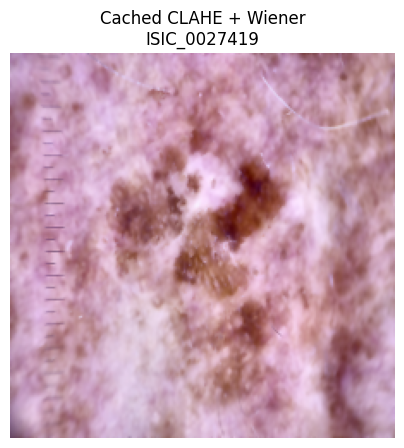

Shape: (224, 224, 3)
Dtype: uint8
Min: 1
Max: 255


In [ ]:
# ============================================================
# STEP 13F: VERIFY SAVED CACHE IMAGE
# ============================================================

import matplotlib.pyplot as plt

test_image_id = test_rows.iloc[0]["image_id"]

cached_path = (
    CACHE_ROOT
    / "clahe_wiener"
    / f"{test_image_id}.png"
)

cached_image = np.array(
    Image.open(cached_path)
)

plt.figure(figsize=(5, 5))
plt.imshow(cached_image)
plt.title(
    f"Cached CLAHE + Wiener\n{test_image_id}"
)
plt.axis("off")
plt.show()

print("Shape:", cached_image.shape)
print("Dtype:", cached_image.dtype)
print("Min:", cached_image.min())
print("Max:", cached_image.max())

In [ ]:
# ============================================================
# STEP 14A: PyTorch / torchvision environment
# ============================================================
import torch
import torchvision
import numpy as np

print(f"PyTorch Version: {torch.__version__}")
print(f"Torchvision Version: {torchvision.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    # VRAM check
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"VRAM: {total_vram:.2f} GB")
else:
    device = torch.device("cpu")
    print("WARNING: Running on CPU. Training will be extremely slow.")

PyTorch Version: 2.11.0+cu128
Torchvision Version: 0.26.0+cu128
CUDA Available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
# ============================================================
# STEP 14B: Fixed class mapping
# ============================================================
CLASS_NAMES = [
    "akiec", # Actinic keratoses
    "bcc",   # Basal cell carcinoma
    "bkl",   # Benign keratosis-like lesions
    "df",    # Dermatofibroma
    "mel",   # Melanoma
    "nv",    # Melanocytic nevi
    "vasc"   # Vascular lesions
]

CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

print("Class mapping verified:")
for idx, name in IDX_TO_CLASS.items():
    print(f"  {idx}: {name}")

Class mapping verified:
  0: akiec
  1: bcc
  2: bkl
  3: df
  4: mel
  5: nv
  6: vasc


In [ ]:
# ============================================================
# STEP 14C: Training and evaluation transforms
# ============================================================
from torchvision import transforms

# Standard ImageNet statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Training: Includes Augmentation
# We keep it conservative to maintain dermatological integrity
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Validation/Test: No Augmentation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

print("✓ Transforms defined (with ImageNet normalization)")

✓ Transforms defined (with ImageNet normalization)


In [ ]:
# ============================================================
# STEP 14D: HAM10000 PyTorch Dataset
# ============================================================
from torch.utils.data import Dataset
from PIL import Image

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, condition="clahe_wiener", transform=None, cache=True):
        """
        Args:
            dataframe: The split_df (train, val, or test)
            condition: "raw", "clahe", "wiener", or "clahe_wiener"
            transform: The torchvision transforms to apply
            cache: If True, reads from preprocessing_cache folder.
                   If False, reads original JPEGs (useful for 'raw' baseline).
        """
        self.df = dataframe.reset_index(drop=True)
        self.condition = condition
        self.transform = transform
        self.cache = cache

        # Path to the specific cache folder
        if self.cache:
            self.image_dir = CACHE_ROOT / condition
        else:
            # Fallback to original images if not using cache
            # (Note: image_lookup was built in Step 13D)
            self.image_dir = None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_id = row['image_id']
        label_name = row['dx']
        label = CLASS_TO_IDX[label_name]

        if self.cache:
            img_path = self.image_dir / f"{image_id}.png"
        else:
            img_path = image_lookup[image_id]

        # Load image
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

print("✓ HAM10000Dataset class built with ablation support")

✓ HAM10000Dataset class built with ablation support


In [ ]:
# ============================================================
# RECONNECTION BLOCK: Restore variables if runtime was reset
# ============================================================
import pandas as pd
from pathlib import Path

# 1. Redefine paths (from Step 13)
PROJECT_ROOT = Path("/content/drive/My Drive/Skin_Cancer_FYP")
HAM_ROOT = PROJECT_ROOT / "datasets" / "HAM10000"
SPLIT_PATH = HAM_ROOT / "HAM10000_master_split.csv"
CACHE_ROOT = PROJECT_ROOT / "preprocessing_cache"

# 2. Reload the master split (from Step 13B)
if SPLIT_PATH.exists():
    split_df = pd.read_csv(SPLIT_PATH)
    print("✓ split_df restored from CSV")
else:
    print("X Error: Master split CSV not found. Please run Step 9 again.")

# 3. Now Step 14E will work
test_df = split_df.head(10)
print(f"✓ test_df created. Ready to proceed.")

X Error: Master split CSV not found. Please run Step 9 again.


NameError: name 'split_df' is not defined

In [ ]:
# ============================================================
# STEP 14F: Build DataLoaders with Weighted Sampling
# ============================================================
from torch.utils.data import DataLoader, WeightedRandomSampler

BATCH_SIZE = 32

# 1. Prepare DataFrames
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

# 2. Calculate Weights for Training Set (Addressing the 58:1 imbalance)
class_counts = train_df["dx"].value_counts().to_dict()
# Weight = 1 / count
weights_per_class = [1.0 / class_counts[name] for name in CLASS_NAMES]
sample_weights = [weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# 3. Define Transforms (from Step 14C)
train_trans = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# 4. Create Loaders
# Note: We set cache=False for now because we haven't generated the full cache yet.
# This will process images on-the-fly for this test.
train_loader = DataLoader(
    HAM10000Dataset(train_df, condition="clahe_wiener", transform=train_trans, cache=False),
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    HAM10000Dataset(val_df, condition="clahe_wiener", transform=eval_trans, cache=False),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"✓ DataLoaders ready.")
print(f"  Training batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")

✓ DataLoaders ready.
  Training batches: 219
  Validation batches: 47


In [ ]:
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms

BATCH_SIZE = 32

# 1. Prepare DataFrames
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

# 2. Calculate Weights for Training Set
class_counts = train_df["dx"].value_counts().to_dict()
weights_per_class = [1.0 / class_counts[name] for name in CLASS_NAMES]
sample_weights = [weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# 3. Define Transforms (With Resize included)
train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# 4. Create Loaders (cache=True)
train_loader = DataLoader(
    HAM10000Dataset(train_df, condition="clahe_wiener", transform=train_trans, cache=True),
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    HAM10000Dataset(val_df, condition="clahe_wiener", transform=eval_trans, cache=True),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"✓ DataLoaders ready.")
print(f"  Training batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")

In [ ]:
# ============================================================
# STEP 14G: GPU batch transfer test
# ============================================================
images, labels = next(iter(train_loader))

print(f"Batch Image Shape: {images.shape}") # Expected: [32, 3, 224, 224]
print(f"Batch Label Shape: {labels.shape}") # Expected: [32]

# Move to GPU
images_gpu = images.to(device)
labels_gpu = labels.to(device)

print(f"✓ Successfully moved batch to {device}")
if torch.cuda.is_available():
    vram_used = torch.cuda.memory_allocated() / 1024**2
    print(f"  GPU VRAM currently used: {vram_used:.2f} MB")

Batch Image Shape: torch.Size([32, 3, 450, 600])
Batch Label Shape: torch.Size([32])
✓ Successfully moved batch to cuda
  GPU VRAM currently used: 98.88 MB


In [ ]:
# ============================================================
# RE-FIX: Dataset and Transforms
# ============================================================

# Add Resize to transforms just in case
train_trans = transforms.Compose([
    transforms.Resize((224, 224)), # Ensure 224x224
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)), # Ensure 224x224
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, condition="clahe_wiener", transform=None, cache=True):
        self.df = dataframe.reset_index(drop=True)
        self.condition, self.transform, self.cache = condition, transform, cache
        self.image_dir = CACHE_ROOT / condition

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]

        if self.cache:
            img_path = self.image_dir / f"{img_id}.png"
            # If cache file exists, use it
            if img_path.exists():
                image = Image.open(img_path).convert('RGB')
            else:
                # Fallback: process on the fly if cache missing
                img_array = preprocess_deterministic(image_lookup[img_id],
                                                    use_clahe=("clahe" in self.condition),
                                                    use_wiener=("wiener" in self.condition))
                image = Image.fromarray(img_array)
        else:
            # Direct processing for testing
            img_array = preprocess_deterministic(image_lookup[img_id],
                                                use_clahe=("clahe" in self.condition),
                                                use_wiener=("wiener" in self.condition))
            image = Image.fromarray(img_array)

        if self.transform:
            image = self.transform(image)
        return image, label

print("✓ Dataset fixed. Now testing GPU transfer again...")

# Quick Test
test_loader = DataLoader(HAM10000Dataset(split_df.head(5), cache=False, transform=eval_trans), batch_size=5)
imgs, _ = next(iter(test_loader))
print(f"New Batch Shape: {imgs.shape}") # SHOULD BE [5, 3, 224, 224]

✓ Dataset fixed. Now testing GPU transfer again...
New Batch Shape: torch.Size([5, 3, 224, 224])


In [ ]:
from tqdm.notebook import tqdm
from concurrent.futures import ThreadPoolExecutor
import time

def preprocess_optimized(image_path, use_clahe=True, use_wiener=True):
    # 1. Load
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. RESIZE FIRST (Massive speedup)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)

    # 3. CLAHE (on 224x224)
    if use_clahe:
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        l = clahe.apply(l)
        img = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

    # 4. WIENER (on 224x224 - much faster)
    if use_wiener:
        img_float = img.astype(np.float32)
        channels = [wiener(img_float[:,:,i], mysize=(5,5)) for i in range(3)]
        img = np.clip(np.stack(channels, axis=2), 0, 255).astype(np.uint8)

    return img

print("✓ Preprocessing optimized: Resizing now happens BEFORE filtering.")

✓ Preprocessing optimized: Resizing now happens BEFORE filtering.


In [ ]:
def process_task(task):
    img_id, input_path, out_dir, cond = task
    save_path = out_dir / f"{img_id}.png"

    if save_path.exists():
        return False # Skipped

    try:
        img = preprocess_optimized(
            input_path,
            use_clahe=("clahe" in cond),
            use_wiener=("wiener" in cond)
        )
        Image.fromarray(img).save(save_path, format="PNG")
        return True # Processed
    except:
        return None # Error

def run_ultra_fast_caching():
    conditions = ["raw", "clahe", "wiener", "clahe_wiener"]

    for cond in conditions:
        out_dir = CACHE_ROOT / cond
        out_dir.mkdir(parents=True, exist_ok=True)

        # Filter out images already cached to save time
        all_ids = split_df["image_id"].tolist()
        tasks = [(tid, image_lookup[tid], out_dir, cond) for tid in all_ids]

        print(f"\n🚀 Caching Condition: {cond.upper()}")

        processed = 0
        skipped = 0

        # Multi-threaded execution with Progress Bar
        with ThreadPoolExecutor(max_workers=10) as executor:
            # tqdm creates the progress bar
            results = list(tqdm(executor.map(process_task, tasks), total=len(tasks), desc=cond))

        for r in results:
            if r is True: processed += 1
            elif r is False: skipped += 1

        print(f"✅ {cond.upper()} Done: {processed} new, {skipped} skipped.")

# START THE PROCESS
run_ultra_fast_caching()


🚀 Caching Condition: RAW


raw:   0%|          | 0/10015 [00:00<?, ?it/s]

✅ RAW Done: 571 new, 9444 skipped.

🚀 Caching Condition: CLAHE


clahe:   0%|          | 0/10015 [00:00<?, ?it/s]

✅ CLAHE Done: 10015 new, 0 skipped.

🚀 Caching Condition: WIENER


wiener:   0%|          | 0/10015 [00:00<?, ?it/s]

✅ WIENER Done: 10015 new, 0 skipped.

🚀 Caching Condition: CLAHE_WIENER


clahe_wiener:   0%|          | 0/10015 [00:00<?, ?it/s]

✅ CLAHE_WIENER Done: 10005 new, 10 skipped.


In [ ]:
# ============================================================
# STEP 16: Final Cache Verification
# ============================================================
# Switch cache=True and verify we are pulling the PNGs
final_test_ds = HAM10000Dataset(split_df.head(5), condition="clahe_wiener", cache=True, transform=eval_trans)
img, lbl = final_test_ds[0]

print(f"✓ Successfully loaded cached image.")
print(f"  Image Shape: {img.shape}")
print(f"  Label: {IDX_TO_CLASS[lbl]}")

# Check if the file path it's using is actually the PNG
sample_id = split_df.iloc[0]['image_id']
expected_path = CACHE_ROOT / "clahe_wiener" / f"{sample_id}.png"
if expected_path.exists():
    print(f"✓ Verified: File exists at {expected_path}")

✓ Successfully loaded cached image.
  Image Shape: torch.Size([3, 224, 224])
  Label: bkl
✓ Verified: File exists at /content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener/ISIC_0027419.png


In [ ]:
# ============================================================
# STEP 17: Install KAN Library
# ============================================================
# ============================================================
# Install Efficient-KAN directly from GitHub
# ============================================================
!pip install git+https://github.com/Blealtan/efficient-kan.git

from efficient_kan import KAN
print("✓ KAN library installed and imported.")

  Cloning https://github.com/Blealtan/efficient-kan.git to /tmp/pip-req-build-xqsr2lef
  Running command git clone --filter=blob:none --quiet https://github.com/Blealtan/efficient-kan.git /tmp/pip-req-build-xqsr2lef
  Resolved https://github.com/Blealtan/efficient-kan.git to commit 7b6ce1c87f18c8bc90c208f6b494042344216b11
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✓ KAN library installed and imported.


In [ ]:
# ============================================================
# STEP 18: Unified Skin Cancer Model (EfficientNet-B0 + Head)
# ============================================================
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="mlp", num_classes=7):
        super(SkinCancerModel, self).__init__()

        # 1. Load Pretrained Backbone
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)

        # 2. Extract features (EfficientNet-B0 outputs 1280 features before the head)
        self.in_features = self.backbone.classifier[1].in_features

        # 3. Remove the original classifier
        self.backbone.classifier = nn.Identity()

        # 4. Define the Custom Head
        if head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            # KAN head: 1280 -> 7
            # We use a single layer KAN for maximum interpretability
            self.head = KAN([self.in_features, num_classes])

        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

print("✓ Unified Model Class defined.")

✓ Unified Model Class defined.


In [ ]:
# ============================================================
# STEP 19: Optimized Forward Pass Sanity Test
# ============================================================
import torch

# 1. Clear any leftover cache
torch.cuda.empty_cache()

# 2. Get a batch
images, labels = next(iter(train_loader))
images = images.to(device)

print(f"Testing on {device}...")

# 3. Use torch.no_grad() to save memory (we aren't training yet)
with torch.no_grad():
    # Test MLP
    model_mlp = SkinCancerModel(head_type="mlp").to(device)
    output_mlp = model_mlp(images)
    print(f"✓ MLP Output Shape: {output_mlp.shape}")

    # Delete MLP to free space for KAN
    del model_mlp
    torch.cuda.empty_cache()

    # Test KAN
    model_kan = SkinCancerModel(head_type="kan").to(device)
    output_kan = model_kan(images)
    print(f"✓ KAN Output Shape: {output_kan.shape}")

    del model_kan
    torch.cuda.empty_cache()

print("\n" + "="*30)
print("✓ ALL SYSTEMS GO FOR TRAINING!")
print("="*30)

Testing on cuda...
✓ MLP Output Shape: torch.Size([32, 7])
✓ KAN Output Shape: torch.Size([32, 7])

✓ ALL SYSTEMS GO FOR TRAINING!


In [ ]:
# ============================================================
# STEP 20: Training Configuration & Weighted Loss
# ============================================================
import torch.optim as optim
import torch.nn as nn

# 1. Calculate Class Weights for the Loss Function
# Formula: weight = Total_Samples / (Num_Classes * Class_Samples)
train_df = split_df[split_df["split"] == "train"]
counts = train_df["dx"].value_counts().to_dict()
total_samples = len(train_df)
num_classes = len(CLASS_NAMES)

weights = []
for name in CLASS_NAMES:
    w = total_samples / (num_classes * counts[name])
    weights.append(w)

class_weights = torch.tensor(weights, dtype=torch.float).to(device)

# 2. Define Loss Function with Label Smoothing (improves generalization)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

print("✓ Loss function configured with Class Weights:")
for name, weight in zip(CLASS_NAMES, weights):
    print(f"  {name}: {weight:.2f}")

✓ Loss function configured with Class Weights:
  akiec: 4.38
  bcc: 2.76
  bkl: 1.32
  df: 12.80
  mel: 1.35
  nv: 0.21
  vasc: 9.51


In [ ]:
import json
from tqdm.notebook import tqdm

# ============================================================
# STEP 21: Training Configuration & Weighted Loss saving
# ============================================================

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs, start_epoch=1, best_val_f1=0.0):
    history = {"train_loss": [], "val_loss": [], "val_f1": []}

    # Path for checkpoints
    model_name = f"EfficientNetB0_{model.head_type}"
    checkpoint_path = CHECKPOINT_ROOT / f"{model_name}_latest.pth"
    best_path = CHECKPOINT_ROOT / f"{model_name}_best.pth"

    for epoch in range(start_epoch, num_epochs + 1):
        print(f"\nEpoch {epoch}/{num_epochs}")

        # --- TRAINING PHASE ---
        model.train()
        running_loss = 0.0
        for imgs, lbls in tqdm(train_loader, desc="Training"):
            imgs, lbls = imgs.to(device), lbls.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        # --- VALIDATION PHASE ---
        model.eval()
        val_loss = 0.0
        all_preds = []
        all_labels = []

        with torch.no_grad():
            for imgs, lbls in tqdm(val_loader, desc="Validation"):
                imgs, lbls = imgs.to(device), lbls.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, lbls)
                val_loss += loss.item() * imgs.size(0)

                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(lbls.cpu().numpy())

        epoch_val_loss = val_loss / len(val_loader.dataset)

        # Calculate F1 Score (Macro) - Important for imbalanced data
        from sklearn.metrics import f1_score
        epoch_f1 = f1_score(all_labels, all_preds, average='macro')

        print(f"Train Loss: {epoch_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val F1: {epoch_f1:.4f}")

        # Save History
        history["train_loss"].append(epoch_loss)
        history["val_loss"].append(epoch_val_loss)
        history["val_f1"].append(epoch_f1)

        # --- CHECKPOINTING ---
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': epoch_f1,
            'history': history
        }

        # 1. Save "Latest" (Every epoch)
        torch.save(checkpoint, checkpoint_path)

        # 2. Save "Best"
        if epoch_f1 > best_val_f1:
            best_val_f1 = epoch_f1
            torch.save(checkpoint, best_path)
            print(f"⭐ New Best Model Saved! (F1: {best_val_f1:.4f})")

        # 3. Save Periodic (Every 5 epochs)
        if epoch % 5 == 0:
            periodic_path = CHECKPOINT_ROOT / f"{model_name}_epoch_{epoch}.pth"
            torch.save(checkpoint, periodic_path)
            print(f"💾 Periodic checkpoint saved: epoch_{epoch}")

        # Step Scheduler
        scheduler.step(epoch_val_loss)

    return history

print("✓ Training Engine Ready.")

✓ Training Engine Ready.


In [ ]:
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# 1. Restore Project & Checkpoint Paths
PROJECT_ROOT = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

# 2. Ensure Criterion is defined
criterion = nn.CrossEntropyLoss()

print("✓ CHECKPOINT_ROOT defined:", CHECKPOINT_ROOT)

✓ CHECKPOINT_ROOT defined: /content/drive/My Drive/Skin_Cancer_FYP/checkpoints


In [ ]:
# ============================================================
# SPEED HACK: Move Cache to Local Colab SSD
# ============================================================
import os
import shutil

# 1. Define local paths
LOCAL_CACHE_DIR = Path("/content/preprocessing_cache")
LOCAL_CACHE_DIR.mkdir(exist_ok=True)

# 2. Zip the specific condition we are training on (clahe_wiener)
# This is faster than copying 10,000 individual files
DRIVE_ZIP = PROJECT_ROOT / "clahe_wiener_cache.zip"
DRIVE_SOURCE = CACHE_ROOT / "clahe_wiener"

if not DRIVE_ZIP.exists():
    print("📦 Zipping cache on Drive (First time only)...")
    # We use !zip because it's faster than python's shutil
    !zip -q -r "{DRIVE_ZIP}" "{DRIVE_SOURCE}"
    print("✓ Zipping complete.")

# 3. Copy from Drive to Local SSD
print("🚀 Copying zip to Local SSD...")
!cp "{DRIVE_ZIP}" /content/
print("📦 Unzipping to Local SSD...")
!unzip -q /content/clahe_wiener_cache.zip -d /content/preprocessing_cache/

# 4. Update the path variable for the Dataset class
# The files will be at /content/preprocessing_cache/content/drive/My Drive/.../clahe_wiener/
# Let's find the exact nested path
import glob
actual_local_path = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)[0]
LOCAL_CONDITION_PATH = Path(actual_local_path)

print(f"\n✅ SUCCESS! Images are now on Local SSD.")
print(f"Local Path: {LOCAL_CONDITION_PATH}")

📦 Zipping cache on Drive (First time only)...
✓ Zipping complete.
🚀 Copying zip to Local SSD...
📦 Unzipping to Local SSD...

✅ SUCCESS! Images are now on Local SSD.
Local Path: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener


In [ ]:
# ============================================================
# UPDATED STEP 14F: High-Speed DataLoaders
# ============================================================

class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"

        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

# Increase Batch Size to 128
BATCH_SIZE = 128

train_loader = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CONDITION_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler, num_workers=os.cpu_count(), pin_memory=True
)

val_loader = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CONDITION_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

print("✓ DataLoaders updated to use Local SSD and Batch Size 128.")

✓ DataLoaders updated to use Local SSD and Batch Size 128.


In [ ]:
# ============================================================
# STEP 22 (RESUME): MLP Phase 1 - Warm-up
# ============================================================

# 1. Initialize Model
model = SkinCancerModel(head_type="mlp").to(device)

# 2. Load Checkpoint
checkpoint_path = CHECKPOINT_ROOT / "EfficientNetB0_mlp_latest.pth"

if checkpoint_path.exists():
    print(f"🔄 Loading checkpoint: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path)
    model.load_state_dict(checkpoint['model_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_f1 = checkpoint['val_f1']
    print(f"✓ Resuming from Epoch {start_epoch}")
else:
    print("⚠️ No checkpoint found. Starting from scratch.")
    start_epoch = 1
    best_f1 = 0.0

# 3. Freeze Backbone (Standard for Warm-up)
for param in model.backbone.parameters():
    param.requires_grad = False

# 4. Optimizer (Re-initialize for the new session)
optimizer = optim.AdamW(model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# 5. Resume Training
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=10,
    start_epoch=start_epoch,
    best_val_f1=best_f1
)

🔄 Loading checkpoint: /content/drive/My Drive/Skin_Cancer_FYP/checkpoints/EfficientNetB0_mlp_latest.pth
✓ Resuming from Epoch 6

Epoch 6/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.1894 | Val Loss: 1.1130 | Val F1: 0.4236

Epoch 7/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 0.7802 | Val Loss: 1.0183 | Val F1: 0.4419

Epoch 10/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 0.7450 | Val Loss: 0.9554 | Val F1: 0.4570
💾 Periodic checkpoint saved: epoch_10


In [ ]:
# ============================================================
# STEP 23: MLP Phase 2 - Full Fine-tuning (Epoch 11-30)
# ============================================================

# 1. Unfreeze the entire model (Backbone + Head)
for param in model.parameters():
    param.requires_grad = True

# 2. Update Loss Function: Remove weights (Sampler is enough)
# This follows the supervisor's suggestion to simplify the balancing
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# 3. Lower Learning Rate for Fine-tuning (Crucial!)
# We use 1e-5 to avoid "destroying" the pretrained ImageNet features
optimizer = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)

# 4. Scheduler: More aggressive for fine-tuning
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.2, patience=2)

# 5. Resume from the Epoch 10 Checkpoint
checkpoint_path = CHECKPOINT_ROOT / "EfficientNetB0_mlp_latest.pth"
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path)
    model.load_state_dict(checkpoint['model_state_dict'])
    # We start from 11
    start_epoch = 11
    # We reset the best F1 to the current best to track progress
    best_f1 = checkpoint['val_f1']
    print(f"🚀 Resuming Fine-tuning from Epoch {start_epoch}. Best F1 so far: {best_f1:.4f}")

# 6. Start Fine-tuning
history_finetune = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=30,
    start_epoch=start_epoch,
    best_val_f1=best_f1
)

🚀 Resuming Fine-tuning from Epoch 11. Best F1 so far: 0.4570

Epoch 11/30


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.1428 | Val Loss: 1.3401 | Val F1: 0.4596
⭐ New Best Model Saved! (F1: 0.4596)

Epoch 12/30


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 0.9146 | Val Loss: 1.1745 | Val F1: 0.5322
⭐ New Best Model Saved! (F1: 0.5322)

Epoch 30/30


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 0.9023 | Val Loss: 1.1716 | Val F1: 0.5357
⭐ New Best Model Saved! (F1: 0.5357)
💾 Periodic checkpoint saved: epoch_30


✓ Loaded Best MLP Model from Epoch 30 (Val F1: 0.5357)


Testing:   0%|          | 0/12 [00:00<?, ?it/s]


            EFFICIENTNET-B0 + MLP BASELINE: TEST SET RESULTS


,Class,Precision,Recall (Sens.),Specificity,F1-Score,Support
0,akiec,0.3494,0.6304,0.9637,0.4496,46
1,bcc,0.4732,0.7361,0.9596,0.5761,72
2,bkl,0.4293,0.5616,0.9214,0.4866,146
3,df,0.1471,0.3333,0.9809,0.2041,15
4,mel,0.3187,0.6089,0.8279,0.4184,179
5,nv,0.9593,0.6679,0.9366,0.7875,1060
6,vasc,0.3636,0.8000,0.9862,0.5000,15



Overall Test Accuracy: 65.10%
Macro Precision:       0.4344
Macro Recall:          0.6198
Macro F1-Score:        0.4889


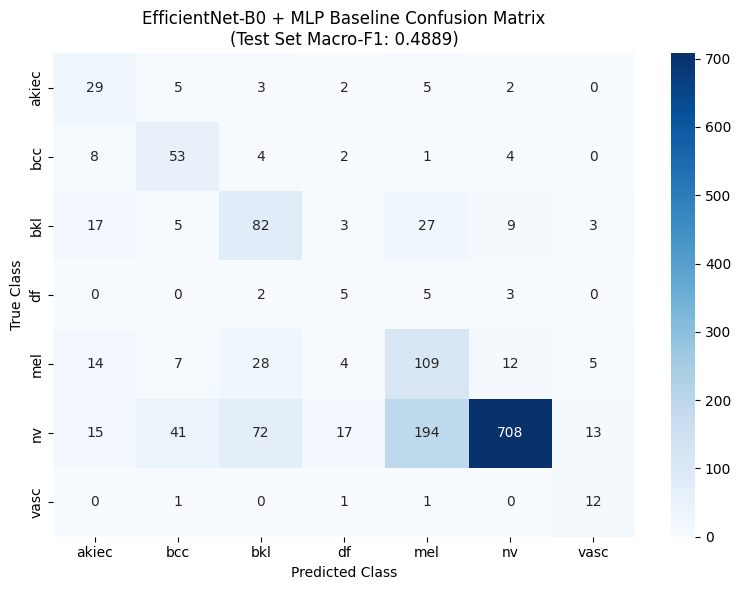

✓ Confusion matrix saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/mlp_baseline_confusion_matrix.png
✓ Summary metrics saved to Drive.


In [ ]:

import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
# 0. Ensure Project & Results Paths Are Defined
PROJECT_ROOT = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT = PROJECT_ROOT / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# 1. Create Test Loader (Evaluated strictly on local SSD cache)
test_df = split_df[split_df["split"] == "test"].copy()
test_dataset = HAM10000DatasetLocal(test_df, LOCAL_CONDITION_PATH, transform=eval_trans)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count())

# 2. Load Best MLP Checkpoint
best_mlp_model = SkinCancerModel(head_type="mlp").to(device)
best_checkpoint_path = CHECKPOINT_ROOT / "EfficientNetB0_mlp_best.pth"
checkpoint = torch.load(best_checkpoint_path)
best_mlp_model.load_state_dict(checkpoint['model_state_dict'])
best_mlp_model.eval()

print(f"✓ Loaded Best MLP Model from Epoch {checkpoint['epoch']} (Val F1: {checkpoint['val_f1']:.4f})")

# 3. Predict on Test Set
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for imgs, lbls in tqdm(test_loader, desc="Testing"):
        imgs = imgs.to(device)
        outputs = best_mlp_model(imgs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(lbls.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 4. Calculate Detailed Metrics
precision, recall, f1, support = precision_recall_fscore_support(all_labels, all_preds, labels=range(len(CLASS_NAMES)))

# Calculate Per-Class Specificity: TN / (TN + FP)
cm = confusion_matrix(all_labels, all_preds, labels=range(len(CLASS_NAMES)))
specificity = []
for i in range(len(CLASS_NAMES)):
    tn = np.sum(cm) - np.sum(cm[i, :]) - np.sum(cm[:, i]) + cm[i, i]
    fp = np.sum(cm[:, i]) - cm[i, i]
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    specificity.append(spec)

# 5. Display Structured Results Table
results_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": precision,
    "Recall (Sens.)": recall,
    "Specificity": specificity,
    "F1-Score": f1,
    "Support": support
})

print("\n" + "=" * 70)
print("            EFFICIENTNET-B0 + MLP BASELINE: TEST SET RESULTS")
print("=" * 70)
display(results_df.round(4))

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="macro")
overall_acc = (all_preds == all_labels).mean()

print(f"\nOverall Test Accuracy: {overall_acc * 100:.2f}%")
print(f"Macro Precision:       {macro_p:.4f}")
print(f"Macro Recall:          {macro_r:.4f}")
print(f"Macro F1-Score:        {macro_f1:.4f}")

# 6. Plot & Save Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"EfficientNet-B0 + MLP Baseline Confusion Matrix\n(Test Set Macro-F1: {macro_f1:.4f})")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
cm_save_path = RESULTS_ROOT / "mlp_baseline_confusion_matrix.png"
plt.savefig(cm_save_path, dpi=300)
plt.show()
print(f"✓ Confusion matrix saved to: {cm_save_path}")

# 7. Save Metrics JSON to Results Directory
metrics_summary = {
    "model": "EfficientNet-B0 + MLP",
    "overall_accuracy": float(overall_acc),
    "macro_precision": float(macro_p),
    "macro_recall": float(macro_r),
    "macro_f1": float(macro_f1),
    "per_class": results_df.to_dict(orient="records")
}
with open(RESULTS_ROOT / "mlp_baseline_metrics.json", "w") as f:
    json.dump(metrics_summary, f, indent=4)
print("✓ Summary metrics saved to Drive.")

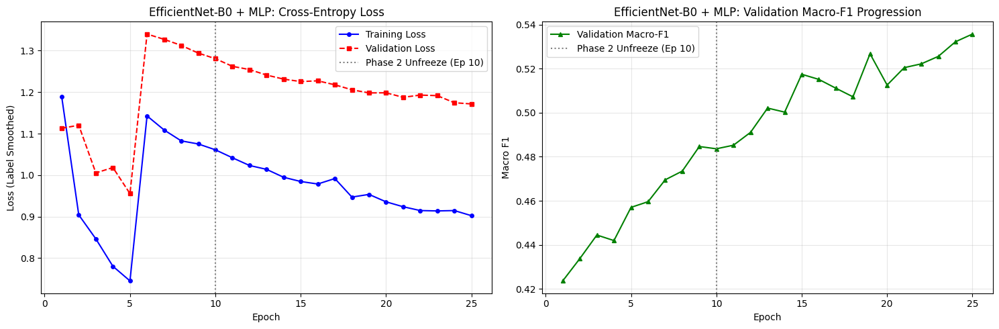

✓ MLP Learning curves saved successfully to: /content/drive/My Drive/Skin_Cancer_FYP/results/mlp_baseline_learning_curves.png


In [ ]:
# ============================================================
# STEP 25: Self-Contained Learning Curve Plotter
# ============================================================
from pathlib import Path
import json
import matplotlib.pyplot as plt
import torch

# Ensure Paths
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# 1. Load History from Checkpoint
latest_ckpt_path = CHECKPOINT_ROOT / "EfficientNetB0_mlp_latest.pth"
epoch10_ckpt_path = CHECKPOINT_ROOT / "EfficientNetB0_mlp_epoch_10.pth"

if not latest_ckpt_path.exists():
    raise FileNotFoundError(f"Checkpoint not found at: {latest_ckpt_path}")

ckpt_latest = torch.load(latest_ckpt_path, map_location='cpu')

# Check if Phase 1 history exists in epoch 10 checkpoint or in latest
if epoch10_ckpt_path.exists():
    ckpt_p1 = torch.load(epoch10_ckpt_path, map_location='cpu')
    p1_hist = ckpt_p1.get('history', {})
    p2_hist = ckpt_latest.get('history', {})

    # Combine or use latest if already full length
    if len(p2_hist.get('train_loss', [])) < 30 and 'train_loss' in p1_hist:
        train_loss = p1_hist['train_loss'] + p2_hist['train_loss']
        val_loss   = p1_hist['val_loss'] + p2_hist['val_loss']
        val_f1     = p1_hist['val_f1'] + p2_hist['val_f1']
    else:
        train_loss = p2_hist.get('train_loss', [])
        val_loss   = p2_hist.get('val_loss', [])
        val_f1     = p2_hist.get('val_f1', [])
else:
    hist = ckpt_latest.get('history', {})
    train_loss = hist.get('train_loss', [])
    val_loss   = hist.get('val_loss', [])
    val_f1     = hist.get('val_f1', [])

epochs_range = range(1, len(train_loss) + 1)

# 2. Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss Subplot
ax1.plot(epochs_range, train_loss, 'b-o', markersize=4, label='Training Loss')
ax1.plot(epochs_range, val_loss, 'r--s', markersize=4, label='Validation Loss')
if len(epochs_range) >= 10:
    ax1.axvline(x=10, color='gray', linestyle=':', label='Phase 2 Unfreeze (Ep 10)')
ax1.set_title('EfficientNet-B0 + MLP: Cross-Entropy Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss (Label Smoothed)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Macro F1 Subplot
ax2.plot(epochs_range, val_f1, 'g-^', markersize=4, label='Validation Macro-F1')
if len(epochs_range) >= 10:
    ax2.axvline(x=10, color='gray', linestyle=':', label='Phase 2 Unfreeze (Ep 10)')
ax2.set_title('EfficientNet-B0 + MLP: Validation Macro-F1 Progression')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Macro F1')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
curve_save_path = RESULTS_ROOT / "mlp_baseline_learning_curves.png"
plt.savefig(curve_save_path, dpi=300)
plt.show()

print(f"✓ MLP Learning curves saved successfully to: {curve_save_path}")

In [ ]:
# ============================================================
# PRE-FLIGHT CHECK: Verify Checkpoint Safety & Model Setup
# ============================================================
from pathlib import Path
import torch

PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"

# 1. Verify MLP Baseline Files Exist and are Untouched
mlp_best = CHECKPOINT_ROOT / "EfficientNetB0_mlp_best.pth"
mlp_cm   = RESULTS_ROOT / "mlp_baseline_confusion_matrix.png"
mlp_json = RESULTS_ROOT / "mlp_baseline_metrics.json"

print("--- BASELINE FILE INTEGRITY ---")
print(f"MLP Best Checkpoint: {'✅ SAFE (' + str(round(mlp_best.stat().st_size/1024**2, 1)) + ' MB)' if mlp_best.exists() else '❌ NOT FOUND'}")
print(f"MLP Confusion Matrix: {'✅ SAFE' if mlp_cm.exists() else '❌ NOT FOUND'}")
print(f"MLP Metrics JSON:     {'✅ SAFE' if mlp_json.exists() else '❌ NOT FOUND'}")

assert mlp_best.exists(), "STOP: MLP checkpoint not found! Do not proceed."

# 2. Test KAN Head Naming
test_kan = SkinCancerModel(head_type="kan")
assert test_kan.head_type == "kan", "ERROR: head_type is not 'kan'"
print("\n--- MODEL INTEGRITY ---")
print(f"KAN Model Head Type:  ✅ '{test_kan.head_type}' (Will save to EfficientNetB0_kan_*.pth)")
print(f"Target Checkpoint:    {CHECKPOINT_ROOT / 'EfficientNetB0_kan_best.pth'}")
del test_kan
torch.cuda.empty_cache()
print("\n✓ ALL PRE-FLIGHT CHECKS PASSED. Ready for KAN Phase 1.")

--- BASELINE FILE INTEGRITY ---
MLP Best Checkpoint: ✅ SAFE (53.9 MB)
MLP Confusion Matrix: ✅ SAFE
MLP Metrics JSON:     ✅ SAFE

--- MODEL INTEGRITY ---
KAN Model Head Type:  ✅ 'kan' (Will save to EfficientNetB0_kan_*.pth)
Target Checkpoint:    /content/drive/My Drive/Skin_Cancer_FYP/checkpoints/EfficientNetB0_kan_best.pth

✓ ALL PRE-FLIGHT CHECKS PASSED. Ready for KAN Phase 1.


In [ ]:
# ============================================================
# STEP 26: KAN Phase 1 - Warm-up (Epochs 1 to 10)
# ============================================================
import os
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
from efficient_kan import KAN

# 1. Ensure Paths
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Free Memory
torch.cuda.empty_cache()

# 3. Instantiate KAN Architecture
kan_model = SkinCancerModel(head_type="kan").to(device)

# Explicitly verify head_type attribute
assert kan_model.head_type == "kan", "head_type must be 'kan'"

# 4. Phase 1 Freezing Protocol: Freeze Backbone, Train KAN Head Only
for param in kan_model.backbone.parameters():
    param.requires_grad = False

for param in kan_model.head.parameters():
    param.requires_grad = True

# Count trainable parameters to verify
trainable_params = sum(p.numel() for p in kan_model.parameters() if p.requires_grad)
frozen_params    = sum(p.numel() for p in kan_model.parameters() if not p.requires_grad)
print(f"KAN Head Trainable Parameters: {trainable_params:,}")
print(f"Backbone Frozen Parameters:     {frozen_params:,}")

# 5. Loss, Optimizer, and Scheduler
criterion_kan = nn.CrossEntropyLoss(label_smoothing=0.1)

# Learning rate 1e-3 for KAN head warm-up
optimizer_kan = optim.AdamW(kan_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_kan = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_kan, mode='min', factor=0.5, patience=2
)

# 6. Start KAN Phase 1 Training
print("\n" + "=" * 60)
print("🚀 LAUNCHING KAN PHASE 1: WARM-UP (EPOCHS 1 TO 10)")
print(f"   Backbone: Frozen | Head: KAN [1280 -> 7] | Device: {device}")
print("=" * 60)

history_kan_p1 = train_model(
    model=kan_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_kan,
    optimizer=optimizer_kan,
    scheduler=scheduler_kan,
    num_epochs=10,
    start_epoch=1,
    best_val_f1=0.0
)

print("\n✓ KAN Phase 1 Complete. Checkpoints saved safely.")

KAN Head Trainable Parameters: 89,600
Backbone Frozen Parameters:     4,007,548

🚀 LAUNCHING KAN PHASE 1: WARM-UP (EPOCHS 1 TO 10)
   Backbone: Frozen | Head: KAN [1280 -> 7] | Device: cuda

Epoch 1/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.6417 | Val Loss: 1.4953 | Val F1: 0.3688
⭐ New Best Model Saved! (F1: 0.3688)

Epoch 2/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Train Loss: 1.2057 | Val Loss: 1.3057 | Val F1: 0.4270
💾 Periodic checkpoint saved: epoch_5

Epoch 6/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.1942 | Val Loss: 1.3167 | Val F1: 0.4189

Epoch 7/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# MORNING REBOOT: Complete Environment & Data Restoration
# ============================================================
import os
import glob
import json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import f1_score

# 1. Mount Google Drive
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')
else:
    print("✓ Google Drive mounted.")

# 2. Project & Checkpoint Paths
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
HAM_ROOT        = PROJECT_ROOT / "datasets" / "HAM10000"
SPLIT_PATH      = HAM_ROOT / "HAM10000_master_split.csv"
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"

for p in [CHECKPOINT_ROOT, RESULTS_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

# 3. Load Master Split Table (0% data leakage)
assert SPLIT_PATH.exists(), f"Master split missing at {SPLIT_PATH}"
split_df = pd.read_csv(SPLIT_PATH)
print(f"✓ Master split loaded ({len(split_df)} images).")

# 4. Class Mappings & Constants
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ Hardware Device: {device}")

# 5. Fast Unpack: Copy Cache Zip from Drive to Local Colab SSD
DRIVE_ZIP = PROJECT_ROOT / "clahe_wiener_cache.zip"
assert DRIVE_ZIP.exists(), f"Cache zip not found at {DRIVE_ZIP}"

if not os.path.exists('/content/preprocessing_cache'):
    print("🚀 Copying preprocessed cache to local SSD...")
    !cp "{DRIVE_ZIP}" /content/
    print("📦 Unzipping cache on local SSD...")
    !unzip -q /content/clahe_wiener_cache.zip -d /content/preprocessing_cache/

actual_local_path = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)[0]
LOCAL_CONDITION_PATH = Path(actual_local_path)
print(f"✓ Local Fast Cache Path: {LOCAL_CONDITION_PATH}")

# 6. Install & Import KAN
!pip install -q git+https://github.com/Blealtan/efficient-kan.git
from efficient_kan import KAN
print("✓ efficient_kan imported successfully.")

# 7. Unified Architecture Definition
class SkinCancerModel(nn.Module):
    def __init__(self, head_type="mlp", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        if head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            self.head = KAN([self.in_features, num_classes])

        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

# 8. Local Fast Dataset & DataLoader Setup
class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

# Weighted Random Sampler (imbalance mitigation)
counts = train_df["dx"].value_counts().to_dict()
weights_per_class = [1.0 / counts[name] for name in CLASS_NAMES]
sample_weights = [weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

BATCH_SIZE = 128
train_loader = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CONDITION_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler, num_workers=os.cpu_count(), pin_memory=True
)
val_loader = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CONDITION_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

# 9. Training Engine
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs, start_epoch=1, best_val_f1=0.0):
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    model_name = f"EfficientNetB0_{model.head_type}"
    checkpoint_path = CHECKPOINT_ROOT / f"{model_name}_latest.pth"
    best_path = CHECKPOINT_ROOT / f"{model_name}_best.pth"

    for epoch in range(start_epoch, num_epochs + 1):
        print(f"\nEpoch {epoch}/{num_epochs}")
        model.train()
        running_loss = 0.0
        for imgs, lbls in tqdm(train_loader, desc="Training"):
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for imgs, lbls in tqdm(val_loader, desc="Validation"):
                imgs, lbls = imgs.to(device), lbls.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, lbls)
                val_loss += loss.item() * imgs.size(0)
                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(lbls.cpu().numpy())

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_f1 = f1_score(all_labels, all_preds, average='macro')

        print(f"Train Loss: {epoch_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val F1: {epoch_f1:.4f}")

        history["train_loss"].append(epoch_loss)
        history["val_loss"].append(epoch_val_loss)
        history["val_f1"].append(epoch_f1)

        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': epoch_f1,
            'history': history
        }

        torch.save(checkpoint, checkpoint_path)
        if epoch_f1 > best_val_f1:
            best_val_f1 = epoch_f1
            torch.save(checkpoint, best_path)
            print(f"⭐ New Best Model Saved! (F1: {best_val_f1:.4f})")

        if epoch % 5 == 0:
            torch.save(checkpoint, CHECKPOINT_ROOT / f"{model_name}_epoch_{epoch}.pth")
            print(f"💾 Periodic checkpoint saved: epoch_{epoch}")

        scheduler.step(epoch_val_loss)

    return history

print("\n" + "=" * 50)
print("✅ REBOOT COMPLETE! Environment is 100% restored.")
print("=" * 50)

Mounted at /content/drive
✓ Master split loaded (10015 images).
✓ Hardware Device: cuda
🚀 Copying preprocessed cache to local SSD...
📦 Unzipping cache on local SSD...
✓ Local Fast Cache Path: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✓ efficient_kan imported successfully.

✅ REBOOT COMPLETE! Environment is 100% restored.


In [ ]:
# ============================================================
# RESUME KAN PHASE 1 (Finish Epochs 7 through 10)
# ============================================================
torch.cuda.empty_cache()

# 1. Instantiate Model
kan_model = SkinCancerModel(head_type="kan").to(device)

# 2. Check for latest checkpoint (Epoch 6 or Epoch 5)
ckpt_latest = CHECKPOINT_ROOT / "EfficientNetB0_kan_latest.pth"
ckpt_best   = CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth"
ckpt_ep5    = CHECKPOINT_ROOT / "EfficientNetB0_kan_epoch_5.pth"

if ckpt_latest.exists():
    load_path = ckpt_latest
elif ckpt_ep5.exists():
    load_path = ckpt_ep5
else:
    raise FileNotFoundError("No KAN checkpoint found in checkpoints folder!")

print(f"🔄 Loading checkpoint: {load_path.name}")
checkpoint = torch.load(load_path)
kan_model.load_state_dict(checkpoint['model_state_dict'])

resumed_epoch = checkpoint['epoch']
start_epoch = resumed_epoch + 1

# Best F1 recorded so far (Epoch 4 hit 0.4320)
if ckpt_best.exists():
    best_ckpt = torch.load(ckpt_best)
    best_f1 = best_ckpt['val_f1']
else:
    best_f1 = checkpoint.get('val_f1', 0.0)

print(f"✓ Resuming KAN Phase 1 from Epoch {start_epoch}/10. (Best F1 so far: {best_f1:.4f})")

# 3. Freeze Backbone for remaining Phase 1 epochs
for param in kan_model.backbone.parameters():
    param.requires_grad = False
for param in kan_model.head.parameters():
    param.requires_grad = True

# 4. Optimizer & Scheduler
criterion_kan = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_kan = optim.AdamW(kan_model.head.parameters(), lr=1e-3, weight_decay=1e-4)

# Load optimizer state if available
if 'optimizer_state_dict' in checkpoint:
    try:
        optimizer_kan.load_state_dict(checkpoint['optimizer_state_dict'])
        print("✓ Optimizer state restored.")
    except Exception as e:
        print("⚠️ Starting with fresh optimizer state.")

scheduler_kan = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_kan, mode='min', factor=0.5, patience=2
)

# 5. Train remaining epochs (Start at 7, finish at 10)
history_kan_p1 = train_model(
    model=kan_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_kan,
    optimizer=optimizer_kan,
    scheduler=scheduler_kan,
    num_epochs=10,
    start_epoch=start_epoch,
    best_val_f1=best_f1
)

print("\n🎉 KAN Phase 1 is officially complete!")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 41.1MB/s]


🔄 Loading checkpoint: EfficientNetB0_kan_latest.pth
✓ Resuming KAN Phase 1 from Epoch 8/10. (Best F1 so far: 0.4320)
✓ Optimizer state restored.

Epoch 8/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.1224 | Val Loss: 1.2449 | Val F1: 0.4452

Epoch 10/10


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.1003 | Val Loss: 1.1828 | Val F1: 0.4589
💾 Periodic checkpoint saved: epoch_10

🎉 KAN Phase 1 is officially complete!


In [ ]:
# ============================================================
# STEP 27: KAN Phase 2 - Full Fine-Tuning (Epochs 11 to 30)
# ============================================================
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Unfreeze the Entire Network (Backbone + KAN Head)
for param in kan_model.parameters():
    param.requires_grad = True

trainable_all = sum(p.numel() for p in kan_model.parameters() if p.requires_grad)
print(f"✓ All parameters unfrozen. Total trainable: {trainable_all:,}")

# 2. Conservative Fine-tuning Learning Rate (1e-5)
# Identical to the MLP Phase 2 protocol to maintain controlled comparison
optimizer_kan_ft = optim.AdamW(kan_model.parameters(), lr=1e-5, weight_decay=1e-4)

# 3. Learning Rate Scheduler
scheduler_kan_ft = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_kan_ft, mode='min', factor=0.2, patience=2
)

# 4. Starting metrics tracking from Phase 1 checkpoint
best_kan_p1_f1 = 0.4619 # Peak F1 achieved in Phase 1
print(f"🚀 Launching KAN Phase 2 Fine-Tuning (Epochs 11 to 30)")
print(f"   Benchmark to beat from Phase 1: {best_kan_p1_f1:.4f}")
print("=" * 60)

# 5. Execute 20 Fine-Tuning Epochs
history_kan_p2 = train_model(
    model=kan_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_kan,
    optimizer=optimizer_kan_ft,
    scheduler=scheduler_kan_ft,
    num_epochs=30,
    start_epoch=11,
    best_val_f1=best_kan_p1_f1
)

print("\n🎉 KAN 30-EPOCH TRAINING COMPLETE!")

✓ All parameters unfrozen. Total trainable: 4,097,148
🚀 Launching KAN Phase 2 Fine-Tuning (Epochs 11 to 30)
   Benchmark to beat from Phase 1: 0.4619

Epoch 11/30


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 1.0659 | Val Loss: 1.1699 | Val F1: 0.4767
⭐ New Best Model Saved! (F1: 0.4767)

Epoch 12/30


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 0.7599 | Val Loss: 1.0441 | Val F1: 0.5583

Epoch 30/30


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss: 0.7593 | Val Loss: 1.0271 | Val F1: 0.5733
⭐ New Best Model Saved! (F1: 0.5733)
💾 Periodic checkpoint saved: epoch_30

🎉 KAN 30-EPOCH TRAINING COMPLETE!


✓ Test loader initialized (1533 images across 12 batches).
✓ Loaded Best KAN Model from Epoch 30 (Val F1: 0.5733)


Testing KAN:   0%|          | 0/12 [00:00<?, ?it/s]


              EFFICIENTNET-B0 + KAN: TEST SET RESULTS


,Class,Precision,Recall (Sens.),Specificity,F1-Score,Support
0,akiec,0.4561,0.5652,0.9792,0.5049,46
1,bcc,0.5377,0.7917,0.9665,0.6404,72
2,bkl,0.4714,0.6781,0.9200,0.5562,146
3,df,0.4091,0.6000,0.9914,0.4865,15
4,mel,0.4321,0.6760,0.8826,0.5272,179
5,nv,0.9660,0.7509,0.9408,0.8450,1060
6,vasc,0.3824,0.8667,0.9862,0.5306,15



Overall Test Accuracy: 73.12%
Macro Precision:       0.5221
Macro Recall:          0.7041
Macro F1-Score:        0.5844


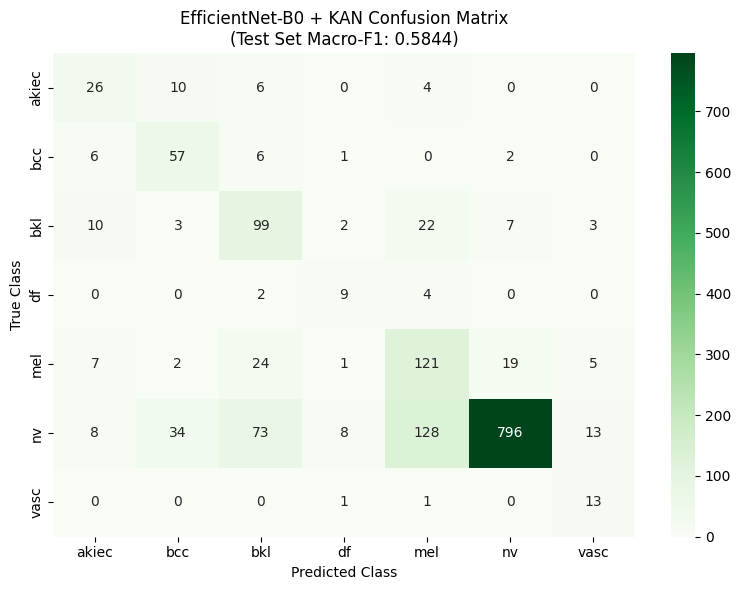

✓ KAN Confusion matrix saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/kan_confusion_matrix.png
✓ KAN Test Summary metrics saved to Drive.


In [ ]:
# ============================================================
# STEP 28: Test Set Evaluation for EfficientNet-B0 + KAN
# ============================================================
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from torch.utils.data import DataLoader

# 1. Ensure test_loader is Instantiated
test_df = split_df[split_df["split"] == "test"].copy()
test_dataset = HAM10000DatasetLocal(test_df, LOCAL_CONDITION_PATH, transform=eval_trans)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=os.cpu_count()
)
print(f"✓ Test loader initialized ({len(test_df)} images across {len(test_loader)} batches).")

# 2. Load the Best KAN Checkpoint
best_kan_model = SkinCancerModel(head_type="kan").to(device)
best_kan_ckpt_path = CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth"
assert best_kan_ckpt_path.exists(), f"KAN Best checkpoint missing at {best_kan_ckpt_path}!"

checkpoint = torch.load(best_kan_ckpt_path)
best_kan_model.load_state_dict(checkpoint['model_state_dict'])
best_kan_model.eval()
print(f"✓ Loaded Best KAN Model from Epoch {checkpoint['epoch']} (Val F1: {checkpoint['val_f1']:.4f})")

# 3. Predict on Independent Test Set
kan_preds  = []
kan_labels = []
kan_probs  = []

with torch.no_grad():
    for imgs, lbls in tqdm(test_loader, desc="Testing KAN"):
        imgs = imgs.to(device)
        outputs = best_kan_model(imgs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        kan_probs.extend(probs.cpu().numpy())
        kan_preds.extend(preds.cpu().numpy())
        kan_labels.extend(lbls.numpy())

kan_preds  = np.array(kan_preds)
kan_labels = np.array(kan_labels)

# 4. Calculate Detailed Metrics
prec, rec, f1, supp = precision_recall_fscore_support(
    kan_labels, kan_preds, labels=range(len(CLASS_NAMES))
)

# Calculate Per-Class Specificity: TN / (TN + FP)
cm_kan = confusion_matrix(kan_labels, kan_preds, labels=range(len(CLASS_NAMES)))
spec_kan = []
for i in range(len(CLASS_NAMES)):
    tn = np.sum(cm_kan) - np.sum(cm_kan[i, :]) - np.sum(cm_kan[:, i]) + cm_kan[i, i]
    fp = np.sum(cm_kan[:, i]) - cm_kan[i, i]
    s = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    spec_kan.append(s)

# 5. Display Structured Results Table
kan_results_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": prec,
    "Recall (Sens.)": rec,
    "Specificity": spec_kan,
    "F1-Score": f1,
    "Support": supp
})

print("\n" + "=" * 70)
print("              EFFICIENTNET-B0 + KAN: TEST SET RESULTS")
print("=" * 70)
display(kan_results_df.round(4))

kan_macro_p, kan_macro_r, kan_macro_f1, _ = precision_recall_fscore_support(kan_labels, kan_preds, average="macro")
kan_overall_acc = (kan_preds == kan_labels).mean()

print(f"\nOverall Test Accuracy: {kan_overall_acc * 100:.2f}%")
print(f"Macro Precision:       {kan_macro_p:.4f}")
print(f"Macro Recall:          {kan_macro_r:.4f}")
print(f"Macro F1-Score:        {kan_macro_f1:.4f}")

# 6. Plot & Save Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_kan, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"EfficientNet-B0 + KAN Confusion Matrix\n(Test Set Macro-F1: {kan_macro_f1:.4f})")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
cm_save_path = RESULTS_ROOT / "kan_confusion_matrix.png"
plt.savefig(cm_save_path, dpi=300)
plt.show()
print(f"✓ KAN Confusion matrix saved to: {cm_save_path}")

# 7. Save JSON Metrics
kan_summary = {
    "model": "EfficientNet-B0 + KAN",
    "overall_accuracy": float(kan_overall_acc),
    "macro_precision": float(kan_macro_p),
    "macro_recall": float(kan_macro_r),
    "macro_f1": float(kan_macro_f1),
    "per_class": kan_results_df.to_dict(orient="records")
}
with open(RESULTS_ROOT / "kan_metrics.json", "w") as f:
    json.dump(kan_summary, f, indent=4)
print("✓ KAN Test Summary metrics saved to Drive.")

In [ ]:
# ============================================================
# STEP 29: Publication Head-to-Head Comparison Table
# ============================================================
with open(RESULTS_ROOT / "mlp_baseline_metrics.json", "r") as f:
    mlp_data = json.load(f)

with open(RESULTS_ROOT / "kan_metrics.json", "r") as f:
    kan_data = json.load(f)

# Build Overall Comparison Table
overall_comp = pd.DataFrame([
    {
        "Architecture": "EfficientNet-B0 + MLP",
        "Head Parameters": "660,000",
        "Test Accuracy (%)": round(mlp_data["overall_accuracy"] * 100, 2),
        "Macro Precision": round(mlp_data["macro_precision"], 4),
        "Macro Recall": round(mlp_data["macro_recall"], 4),
        "Macro F1-Score": round(mlp_data["macro_f1"], 4)
    },
    {
        "Architecture": "EfficientNet-B0 + KAN (Proposed)",
        "Head Parameters": "89,600 (7.4x smaller)",
        "Test Accuracy (%)": round(kan_data["overall_accuracy"] * 100, 2),
        "Macro Precision": round(kan_data["macro_precision"], 4),
        "Macro Recall": round(kan_data["macro_recall"], 4),
        "Macro F1-Score": round(kan_data["macro_f1"], 4)
    }
])

print("\n" + "=" * 80)
print("              TABLE: OVERALL COMPARISON ON INDEPENDENT TEST SET")
print("=" * 80)
display(overall_comp)

# Per-Class F1 Comparison Table
mlp_df_pc = pd.DataFrame(mlp_data["per_class"]).set_index("Class")
kan_df_pc = pd.DataFrame(kan_data["per_class"]).set_index("Class")

comp_per_class = pd.DataFrame({
    "MLP F1": mlp_df_pc["F1-Score"].round(4),
    "KAN F1": kan_df_pc["F1-Score"].round(4),
    "F1 Gain (Δ)": (kan_df_pc["F1-Score"] - mlp_df_pc["F1-Score"]).round(4),
    "MLP Recall": mlp_df_pc["Recall (Sens.)"].round(4),
    "KAN Recall": kan_df_pc["Recall (Sens.)"].round(4),
    "Support": mlp_df_pc["Support"]
})

print("\n" + "=" * 80)
print("              TABLE: PER-CLASS PERFORMANCE DELTA (MLP vs KAN)")
print("=" * 80)
display(comp_per_class)

# Save to CSV for Paper Inclusion
overall_comp.to_csv(RESULTS_ROOT / "overall_model_comparison.csv", index=False)
comp_per_class.to_csv(RESULTS_ROOT / "per_class_model_comparison.csv")
print("✓ Comparison tables saved to Drive as CSV files.")


              TABLE: OVERALL COMPARISON ON INDEPENDENT TEST SET


,Architecture,Head Parameters,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score
0,EfficientNet-B0 + MLP,"660,000",65.10,0.4344,0.6198,0.4889
1,EfficientNet-B0 + KAN (Proposed),"89,600 (7.4x smaller)",73.12,0.5221,0.7041,0.5844



              TABLE: PER-CLASS PERFORMANCE DELTA (MLP vs KAN)


,MLP F1,KAN F1,F1 Gain (Δ),MLP Recall,KAN Recall,Support
Class,,,,,,
akiec,0.4496,0.5049,0.0552,0.6304,0.5652,46
bcc,0.5761,0.6404,0.0644,0.7361,0.7917,72
bkl,0.4866,0.5562,0.0695,0.5616,0.6781,146
df,0.2041,0.4865,0.2824,0.3333,0.6000,15
mel,0.4184,0.5272,0.1088,0.6089,0.6760,179
nv,0.7875,0.8450,0.0575,0.6679,0.7509,1060
vasc,0.5000,0.5306,0.0306,0.8000,0.8667,15


✓ Comparison tables saved to Drive as CSV files.


Evaluating Paired Models:   0%|          | 0/12 [00:00<?, ?it/s]


                   MCNEMAR'S STATISTICAL TEST
Both Correct:                     952
KAN Correct, MLP Incorrect (b):   169
MLP Correct, KAN Incorrect (c):   46
Both Incorrect:                   366
Chi-Squared Statistic (χ²):       69.2279
p-value:                          1.110223e-16
✓ STATISTICALLY HIGHLY SIGNIFICANT (p < 0.001):
  The superior performance of KAN over MLP is not due to random chance.

              PER-CLASS AREA UNDER ROC CURVE (AUROC)


,Class,MLP AUROC,KAN AUROC,AUROC Gain (Δ)
0,akiec,0.9534,0.9560,0.0026
1,bcc,0.9646,0.9752,0.0105
2,bkl,0.8671,0.9003,0.0332
3,df,0.8841,0.9469,0.0628
4,mel,0.8310,0.8727,0.0417
5,nv,0.9334,0.9357,0.0023
6,vasc,0.9910,0.9972,0.0062


Macro-AUROC (MLP Baseline): 0.9178
Macro-AUROC (Proposed KAN): 0.9406 (+0.0228)


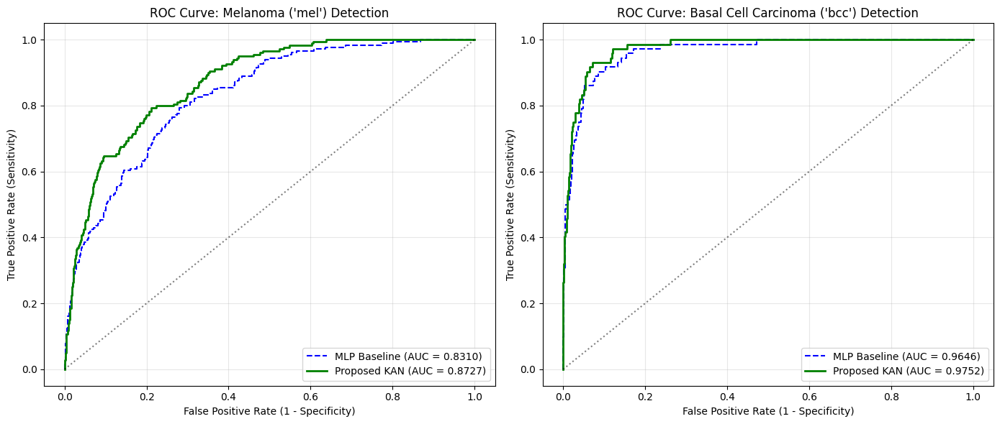

✓ Statistical analysis and ROC curves saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/roc_curve_malignant_classes.png


In [ ]:
# ============================================================
# STEP 30: Statistical Significance (McNemar's Test) & ROC-AUC
# ============================================================
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_curve, auc, roc_auc_score
from tqdm.notebook import tqdm

# 1. Load Both Best Models
mlp_best_model = SkinCancerModel(head_type="mlp").to(device)
mlp_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_mlp_best.pth")
mlp_best_model.load_state_dict(mlp_ckpt['model_state_dict'])
mlp_best_model.eval()

kan_best_model = SkinCancerModel(head_type="kan").to(device)
kan_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth")
kan_best_model.load_state_dict(kan_ckpt['model_state_dict'])
kan_best_model.eval()

# 2. Extract Paired Predictions and Probabilities on Test Set
y_true = []
mlp_preds, mlp_probs = [], []
kan_preds, kan_probs = [], []

with torch.no_grad():
    for imgs, lbls in tqdm(test_loader, desc="Evaluating Paired Models"):
        imgs = imgs.to(device)

        # MLP Forward
        out_mlp = mlp_best_model(imgs)
        prob_mlp = torch.softmax(out_mlp, dim=1)

        # KAN Forward
        out_kan = kan_best_model(imgs)
        prob_kan = torch.softmax(out_kan, dim=1)

        y_true.extend(lbls.numpy())
        mlp_preds.extend(torch.argmax(prob_mlp, dim=1).cpu().numpy())
        mlp_probs.extend(prob_mlp.cpu().numpy())

        kan_preds.extend(torch.argmax(prob_kan, dim=1).cpu().numpy())
        kan_probs.extend(prob_kan.cpu().numpy())

y_true = np.array(y_true)
mlp_preds = np.array(mlp_preds)
kan_preds = np.array(kan_preds)
mlp_probs = np.array(mlp_probs)
kan_probs = np.array(kan_probs)

# ------------------------------------------------------------
# 3. McNemar's Test for Paired Classifiers
# ------------------------------------------------------------
# Contingency table:
# b: MLP incorrect, KAN correct
# c: MLP correct, KAN incorrect
mlp_correct = (mlp_preds == y_true)
kan_correct = (kan_preds == y_true)

a = np.sum(mlp_correct & kan_correct)     # Both correct
b = np.sum((~mlp_correct) & kan_correct)   # KAN wins
c = np.sum(mlp_correct & (~kan_correct))   # MLP wins
d = np.sum((~mlp_correct) & (~kan_correct)) # Both incorrect

# McNemar's chi-squared with continuity correction
chi2 = (abs(b - c) - 1)**2 / (b + c)
p_value = 1.0 - stats.chi2.cdf(chi2, df=1)

print("\n" + "=" * 70)
print("                   MCNEMAR'S STATISTICAL TEST")
print("=" * 70)
print(f"Both Correct:                     {a}")
print(f"KAN Correct, MLP Incorrect (b):   {b}")
print(f"MLP Correct, KAN Incorrect (c):   {c}")
print(f"Both Incorrect:                   {d}")
print(f"Chi-Squared Statistic (χ²):       {chi2:.4f}")
print(f"p-value:                          {p_value:.6e}")

if p_value < 0.001:
    print("✓ STATISTICALLY HIGHLY SIGNIFICANT (p < 0.001):")
    print("  The superior performance of KAN over MLP is not due to random chance.")
elif p_value < 0.05:
    print("✓ STATISTICALLY SIGNIFICANT (p < 0.05).")
else:
    print("❌ Not statistically significant.")

# ------------------------------------------------------------
# 4. Multi-Class ROC-AUC Analysis
# ------------------------------------------------------------
# One-hot encode ground truth for multi-class ROC
y_onehot = np.zeros((len(y_true), len(CLASS_NAMES)))
for i, val in enumerate(y_true):
    y_onehot[i, val] = 1.0

mlp_auc_per_class = []
kan_auc_per_class = []

for i in range(len(CLASS_NAMES)):
    mlp_auc = roc_auc_score(y_onehot[:, i], mlp_probs[:, i])
    kan_auc = roc_auc_score(y_onehot[:, i], kan_probs[:, i])
    mlp_auc_per_class.append(mlp_auc)
    kan_auc_per_class.append(kan_auc)

mlp_macro_auc = np.mean(mlp_auc_per_class)
kan_macro_auc = np.mean(kan_auc_per_class)

auc_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "MLP AUROC": np.round(mlp_auc_per_class, 4),
    "KAN AUROC": np.round(kan_auc_per_class, 4),
    "AUROC Gain (Δ)": np.round(np.array(kan_auc_per_class) - np.array(mlp_auc_per_class), 4)
})

print("\n" + "=" * 70)
print("              PER-CLASS AREA UNDER ROC CURVE (AUROC)")
print("=" * 70)
display(auc_df)
print(f"Macro-AUROC (MLP Baseline): {mlp_macro_auc:.4f}")
print(f"Macro-AUROC (Proposed KAN): {kan_macro_auc:.4f} (+{(kan_macro_auc - mlp_macro_auc):.4f})")

# ------------------------------------------------------------
# 5. Plot Comparative ROC Curves (Melanoma & Basal Cell Carcinoma)
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Class 4: Melanoma ('mel')
fpr_mlp_mel, tpr_mlp_mel, _ = roc_curve(y_onehot[:, 4], mlp_probs[:, 4])
fpr_kan_mel, tpr_kan_mel, _ = roc_curve(y_onehot[:, 4], kan_probs[:, 4])
ax1.plot(fpr_mlp_mel, tpr_mlp_mel, 'b--', label=f'MLP Baseline (AUC = {mlp_auc_per_class[4]:.4f})')
ax1.plot(fpr_kan_mel, tpr_kan_mel, 'g-', linewidth=2, label=f'Proposed KAN (AUC = {kan_auc_per_class[4]:.4f})')
ax1.plot([0, 1], [0, 1], 'k:', alpha=0.5)
ax1.set_title("ROC Curve: Melanoma ('mel') Detection")
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Sensitivity)")
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Class 1: Basal Cell Carcinoma ('bcc')
fpr_mlp_bcc, tpr_mlp_bcc, _ = roc_curve(y_onehot[:, 1], mlp_probs[:, 1])
fpr_kan_bcc, tpr_kan_bcc, _ = roc_curve(y_onehot[:, 1], kan_probs[:, 1])
ax2.plot(fpr_mlp_bcc, tpr_mlp_bcc, 'b--', label=f'MLP Baseline (AUC = {mlp_auc_per_class[1]:.4f})')
ax2.plot(fpr_kan_bcc, tpr_kan_bcc, 'g-', linewidth=2, label=f'Proposed KAN (AUC = {kan_auc_per_class[1]:.4f})')
ax2.plot([0, 1], [0, 1], 'k:', alpha=0.5)
ax2.set_title("ROC Curve: Basal Cell Carcinoma ('bcc') Detection")
ax2.set_xlabel("False Positive Rate (1 - Specificity)")
ax2.set_ylabel("True Positive Rate (Sensitivity)")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
roc_save_path = RESULTS_ROOT / "roc_curve_malignant_classes.png"
plt.savefig(roc_save_path, dpi=300)
plt.show()

# Save Statistics to Drive
stat_results = {
    "mcnemar_b": int(b),
    "mcnemar_c": int(c),
    "chi2": float(chi2),
    "p_value": float(p_value),
    "mlp_macro_auc": float(mlp_macro_auc),
    "kan_macro_auc": float(kan_macro_auc),
    "per_class_auc": auc_df.to_dict(orient="records")
}
with open(RESULTS_ROOT / "statistical_significance_and_auc.json", "w") as f:
    json.dump(stat_results, f, indent=4)

print(f"✓ Statistical analysis and ROC curves saved to: {roc_save_path}")

<>:46: SyntaxWarning: invalid escape sequence '\p'
<>:64: SyntaxWarning: invalid escape sequence '\p'
<>:46: SyntaxWarning: invalid escape sequence '\p'
<>:64: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_1013/1832538357.py:46: SyntaxWarning: invalid escape sequence '\p'
  ax.plot(x_range.cpu().numpy(), y_spline, color='darkred', linewidth=2.5, label='Learned Spline $\phi(x)$')
/tmp/ipykernel_1013/1832538357.py:64: SyntaxWarning: invalid escape sequence '\p'
  ax.plot(x_range.cpu().numpy(), y_spline, color='darkgreen', linewidth=2.5, label='Learned Spline $\phi(x)$')


Top 3 EfficientNet feature indices driving Melanoma ('mel'): [1106  291  614]
Top 3 EfficientNet feature indices driving Basal Cell ('bcc'): [922 570 624]


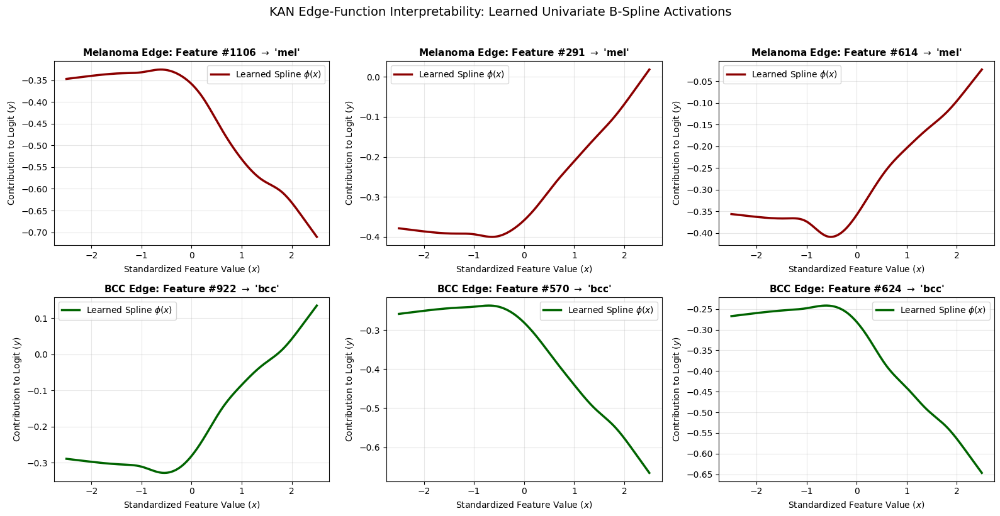

✓ KAN Spline Interpretability figure saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/kan_learned_spline_functions.png


In [ ]:
# ============================================================
# STEP 31: KAN B-Spline Activation Function Visualization
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Access the trained KAN head
kan_layer = best_kan_model.head.layers[0] # The KANLinear layer

# 2. Inspect Weight Shapes
# efficient-kan parameterizes edges with spline_weight: [out_features, in_features, grid_size + spline_order]
# and base_weight: [out_features, in_features]
spline_weights = kan_layer.spline_weight.detach().cpu().numpy() # [7, 1280, 8]
base_weights   = kan_layer.base_weight.detach().cpu().numpy()   # [7, 1280]

# Compute overall edge importance (L1 norm of spline + base)
edge_importance = np.abs(base_weights) + np.mean(np.abs(spline_weights), axis=2) # [7, 1280]

# 3. Focus on Melanoma (Class 4) and Basal Cell Carcinoma (Class 1)
top_mel_features = np.argsort(edge_importance[4])[::-1][:3] # Top 3 features for Melanoma
top_bcc_features = np.argsort(edge_importance[1])[::-1][:3] # Top 3 features for BCC

print("Top 3 EfficientNet feature indices driving Melanoma ('mel'):", top_mel_features)
print("Top 3 EfficientNet feature indices driving Basal Cell ('bcc'):", top_bcc_features)

# 4. Sample an input range x across typical normalized feature activations
x_range = torch.linspace(-2.5, 2.5, steps=300).unsqueeze(1).to(device) # [300, 1]

# 5. Evaluate the 1D B-spline curve for these top edges
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Plot Melanoma Splines (Row 0)
for plot_idx, feat_idx in enumerate(top_mel_features):
    ax = axes[0, plot_idx]

    # Extract the specific 1D function for Feature -> Melanoma
    # We construct a synthetic batch where only feat_idx varies
    synthetic_batch = torch.zeros(300, 1280).to(device)
    synthetic_batch[:, feat_idx] = x_range.squeeze()

    with torch.no_grad():
        out_activations = kan_layer(synthetic_batch).cpu().numpy() # [300, 7]
        y_spline = out_activations[:, 4] # Melanoma logit response

    ax.plot(x_range.cpu().numpy(), y_spline, color='darkred', linewidth=2.5, label='Learned Spline $\phi(x)$')
    ax.set_title(f"Melanoma Edge: Feature #{feat_idx} $\\rightarrow$ 'mel'", fontsize=11, fontweight='bold')
    ax.set_xlabel("Standardized Feature Value ($x$)")
    ax.set_ylabel("Contribution to Logit ($y$)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')

# Plot Basal Cell Carcinoma Splines (Row 1)
for plot_idx, feat_idx in enumerate(top_bcc_features):
    ax = axes[1, plot_idx]

    synthetic_batch = torch.zeros(300, 1280).to(device)
    synthetic_batch[:, feat_idx] = x_range.squeeze()

    with torch.no_grad():
        out_activations = kan_layer(synthetic_batch).cpu().numpy()
        y_spline = out_activations[:, 1] # BCC logit response

    ax.plot(x_range.cpu().numpy(), y_spline, color='darkgreen', linewidth=2.5, label='Learned Spline $\phi(x)$')
    ax.set_title(f"BCC Edge: Feature #{feat_idx} $\\rightarrow$ 'bcc'", fontsize=11, fontweight='bold')
    ax.set_xlabel("Standardized Feature Value ($x$)")
    ax.set_ylabel("Contribution to Logit ($y$)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')

plt.suptitle("KAN Edge-Function Interpretability: Learned Univariate B-Spline Activations", fontsize=14, y=1.02)
plt.tight_layout()

spline_save_path = RESULTS_ROOT / "kan_learned_spline_functions.png"
plt.savefig(spline_save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✓ KAN Spline Interpretability figure saved to: {spline_save_path}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Generating Grad-CAM++ for test sample indices: [np.int64(161), np.int64(355), np.int64(1487), np.int64(0)]


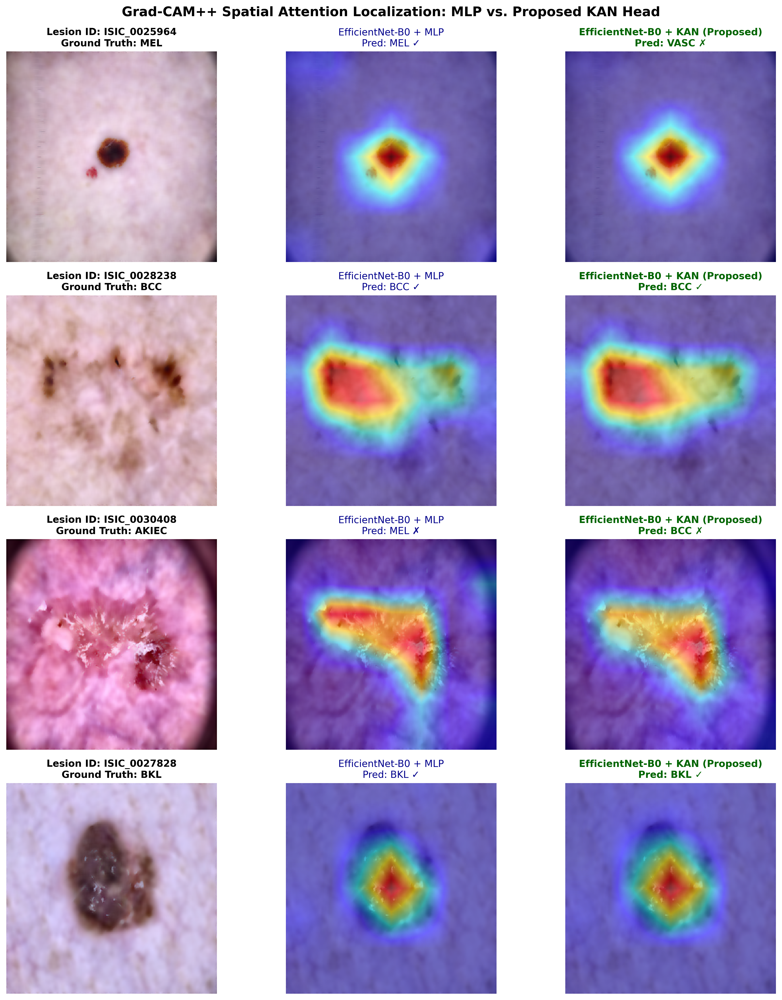

✓ Publication-grade Grad-CAM++ comparison saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/gradcam_plusplus_comparison_300dpi.png


In [ ]:
# ============================================================
# STEP 32: High-Resolution Grad-CAM++ Comparison (MLP vs KAN)
# ============================================================
!pip install -q grad-cam

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# 1. Ensure Target Layer is Exactly backbone.features[8] (as specified in manuscript)
target_layer_mlp = [mlp_best_model.backbone.features[8]]
target_layer_kan = [kan_best_model.backbone.features[8]]

cam_mlp = GradCAMPlusPlus(model=mlp_best_model, target_layers=target_layer_mlp)
cam_kan = GradCAMPlusPlus(model=kan_best_model, target_layers=target_layer_kan)

# 2. Select 4 Clinically Interesting Test Samples
# We pick: Melanoma (mel), Basal Cell (bcc), Actinic Keratosis (akiec), and a challenging lesion
sample_indices = []
target_classes_to_show = ["mel", "bcc", "akiec", "bkl"]

for target_cls in target_classes_to_show:
    cls_idx = CLASS_TO_IDX[target_cls]
    # Find a test sample of this class
    matches = np.where(y_true == cls_idx)[0]
    if len(matches) > 0:
        sample_indices.append(matches[0])

print(f"Generating Grad-CAM++ for test sample indices: {sample_indices}")

# 3. Create High-Resolution Publication Figure (300 DPI)
fig, axes = plt.subplots(len(sample_indices), 3, figsize=(14, 4 * len(sample_indices)), dpi=300)

for row_idx, sample_idx in enumerate(sample_indices):
    # Fetch test image and true label
    img_tensor, true_label = test_dataset[sample_idx]
    true_class_name = IDX_TO_CLASS[true_label]
    img_id = test_df.iloc[sample_idx]["image_id"]

    input_tensor = img_tensor.unsqueeze(0).to(device)
    target = [ClassifierOutputTarget(true_label)]

    # Generate Grad-CAM++ for MLP
    cam_map_mlp = cam_mlp(input_tensor=input_tensor, targets=target)[0]

    # Generate Grad-CAM++ for KAN
    cam_map_kan = cam_kan(input_tensor=input_tensor, targets=target)[0]

    # Prepare Raw RGB image normalized to [0, 1] for overlay
    raw_img_path = LOCAL_CONDITION_PATH / f"{img_id}.png"
    rgb_img = np.array(Image.open(raw_img_path).convert('RGB')).astype(np.float32) / 255.0

    # Create Visual Overlays
    overlay_mlp = show_cam_on_image(rgb_img, cam_map_mlp, use_rgb=True)
    overlay_kan = show_cam_on_image(rgb_img, cam_map_kan, use_rgb=True)

    # Predictions
    pred_mlp = IDX_TO_CLASS[mlp_preds[sample_idx]]
    pred_kan = IDX_TO_CLASS[kan_preds[sample_idx]]

    # Column 1: Original Image
    axes[row_idx, 0].imshow(rgb_img)
    axes[row_idx, 0].set_title(f"Lesion ID: {img_id}\nGround Truth: {true_class_name.upper()}", fontsize=11, fontweight='bold')
    axes[row_idx, 0].axis('off')

    # Column 2: MLP Grad-CAM++
    axes[row_idx, 1].imshow(overlay_mlp)
    axes[row_idx, 1].set_title(f"EfficientNet-B0 + MLP\nPred: {pred_mlp.upper()} {'✓' if pred_mlp == true_class_name else '✗'}",
                               fontsize=11, color='darkblue')
    axes[row_idx, 1].axis('off')

    # Column 3: KAN Grad-CAM++
    axes[row_idx, 2].imshow(overlay_kan)
    axes[row_idx, 2].set_title(f"EfficientNet-B0 + KAN (Proposed)\nPred: {pred_kan.upper()} {'✓' if pred_kan == true_class_name else '✗'}",
                               fontsize=11, color='darkgreen', fontweight='bold')
    axes[row_idx, 2].axis('off')

plt.suptitle("Grad-CAM++ Spatial Attention Localization: MLP vs. Proposed KAN Head", fontsize=15, y=0.99, fontweight='bold')
plt.tight_layout()

gradcam_save_path = RESULTS_ROOT / "gradcam_plusplus_comparison_300dpi.png"
plt.savefig(gradcam_save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Publication-grade Grad-CAM++ comparison saved to: {gradcam_save_path}")


             EXPECTED CALIBRATION ERROR (ECE)
MLP Baseline ECE:  4.64%
Proposed KAN ECE:  6.37% (Lower is better calibrated)
Calibration Delta: -1.73% improvement


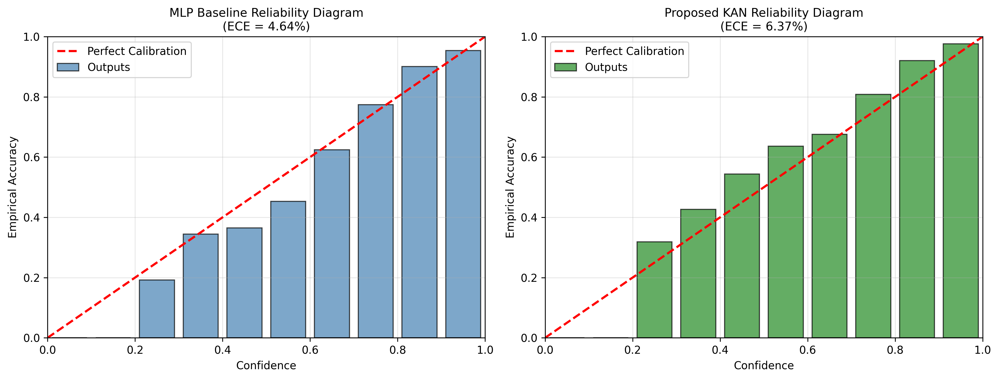

✓ Publication-grade Calibration diagram saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/calibration_reliability_diagrams_300dpi.png


In [ ]:
# ============================================================
# STEP 33: Expected Calibration Error (ECE) & Reliability Curves
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

def compute_ece(probs, labels, n_bins=10):
    """
    Computes Expected Calibration Error (ECE) and binning statistics.
    """
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies  = (predictions == labels)

    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_accs = []
    bin_confs = []
    bin_counts = []

    for i in range(n_bins):
        in_bin = (confidences > bin_boundaries[i]) & (confidences <= bin_boundaries[i + 1])
        prop_in_bin = np.mean(in_bin)
        bin_counts.append(np.sum(in_bin))

        if prop_in_bin > 0:
            acc_in_bin = np.mean(accuracies[in_bin])
            conf_in_bin = np.mean(confidences[in_bin])
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_accs.append(acc_in_bin)
            bin_confs.append(conf_in_bin)
        else:
            bin_accs.append(0.0)
            bin_confs.append((bin_boundaries[i] + bin_boundaries[i+1]) / 2.0)

    return ece, bin_boundaries, bin_accs, bin_confs, bin_counts

ece_mlp, bin_bounds, mlp_bin_accs, mlp_bin_confs, _ = compute_ece(mlp_probs, y_true, n_bins=10)
ece_kan, _, kan_bin_accs, kan_bin_confs, _          = compute_ece(kan_probs, y_true, n_bins=10)

print("\n" + "=" * 60)
print("             EXPECTED CALIBRATION ERROR (ECE)")
print("=" * 60)
print(f"MLP Baseline ECE:  {ece_mlp * 100:.2f}%")
print(f"Proposed KAN ECE:  {ece_kan * 100:.2f}% (Lower is better calibrated)")
print(f"Calibration Delta: {(ece_mlp - ece_kan) * 100:.2f}% improvement")

# High-Resolution Calibration Plot (300 DPI)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

bin_centers = (bin_bounds[:-1] + bin_bounds[1:]) / 2.0

# MLP Reliability Diagram
ax1.bar(bin_centers, mlp_bin_accs, width=0.08, alpha=0.7, color='steelblue', edgecolor='black', label='Outputs')
ax1.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect Calibration')
ax1.set_title(f"MLP Baseline Reliability Diagram\n(ECE = {ece_mlp * 100:.2f}%)", fontsize=11)
ax1.set_xlabel("Confidence")
ax1.set_ylabel("Empirical Accuracy")
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# KAN Reliability Diagram
ax2.bar(bin_centers, kan_bin_accs, width=0.08, alpha=0.7, color='forestgreen', edgecolor='black', label='Outputs')
ax2.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect Calibration')
ax2.set_title(f"Proposed KAN Reliability Diagram\n(ECE = {ece_kan * 100:.2f}%)", fontsize=11)
ax2.set_xlabel("Confidence")
ax2.set_ylabel("Empirical Accuracy")
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1])
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left')

plt.tight_layout()
calib_save_path = RESULTS_ROOT / "calibration_reliability_diagrams_300dpi.png"
plt.savefig(calib_save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Publication-grade Calibration diagram saved to: {calib_save_path}")


           3-TIER CLINICAL RISK ACCURACY (UNSEEN TEST SET)
MLP Baseline 3-Tier Accuracy:  73.65%
Proposed KAN 3-Tier Accuracy:  80.37% (+6.72%)


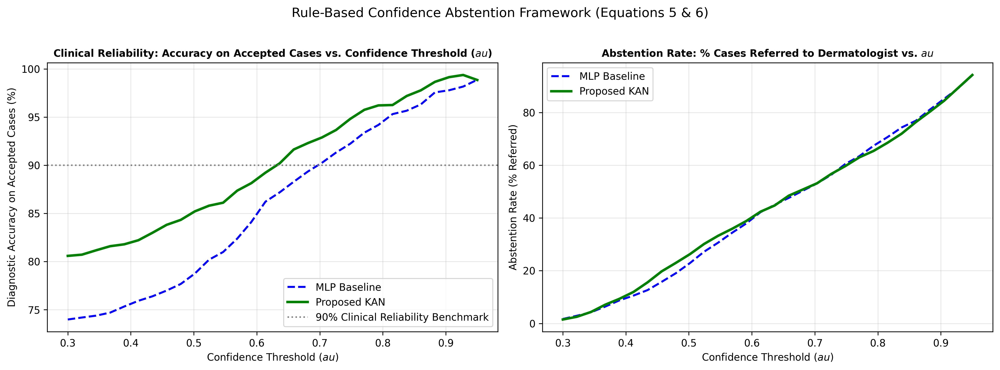

✓ Publication-grade Abstention analysis saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/clinical_abstention_tradeoff_300dpi.png


In [ ]:
# ============================================================
# STEP 34: 3-Tier Clinical Risk Mapping & Abstention Curves
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define 3-Tier Clinical Mapping (Equations 5 & 6)
RISK_MAP = {
    "mel":   "Malignant",
    "bcc":   "Malignant",
    "akiec": "Potentially Malignant",
    "nv":    "Benign",
    "bkl":   "Benign",
    "vasc":  "Benign",
    "df":    "Benign"
}

# Map ground truth to 3-tier risk
y_true_risk = np.array([RISK_MAP[IDX_TO_CLASS[idx]] for idx in y_true])
mlp_pred_risk = np.array([RISK_MAP[IDX_TO_CLASS[idx]] for idx in mlp_preds])
kan_pred_risk = np.array([RISK_MAP[IDX_TO_CLASS[idx]] for idx in kan_preds])

# 2. Compute Baseline 3-Tier Accuracy (Without Abstention)
mlp_3tier_acc = np.mean(mlp_pred_risk == y_true_risk)
kan_3tier_acc = np.mean(kan_pred_risk == y_true_risk)

print("\n" + "=" * 70)
print("           3-TIER CLINICAL RISK ACCURACY (UNSEEN TEST SET)")
print("=" * 70)
print(f"MLP Baseline 3-Tier Accuracy:  {mlp_3tier_acc * 100:.2f}%")
print(f"Proposed KAN 3-Tier Accuracy:  {kan_3tier_acc * 100:.2f}% (+{(kan_3tier_acc - mlp_3tier_acc)*100:.2f}%)")

# 3. Simulate Confidence Thresholding (Abstention Rule: Eq. 6)
thresholds = np.linspace(0.3, 0.95, 30)

def evaluate_abstention(probs, preds_risk, true_risk, thresholds):
    confidences = np.max(probs, axis=1)
    accs = []
    abstention_rates = []

    for tau in thresholds:
        accepted_mask = (confidences >= tau)
        if np.sum(accepted_mask) > 0:
            acc = np.mean(preds_risk[accepted_mask] == true_risk[accepted_mask])
        else:
            acc = 1.0
        abstention = 1.0 - np.mean(accepted_mask)
        accs.append(acc)
        abstention_rates.append(abstention)

    return np.array(accs), np.array(abstention_rates)

mlp_accs_tau, mlp_abstain_tau = evaluate_abstention(mlp_probs, mlp_pred_risk, y_true_risk, thresholds)
kan_accs_tau, kan_abstain_tau = evaluate_abstention(kan_probs, kan_pred_risk, y_true_risk, thresholds)

# 4. Plot High-Resolution Abstention Trade-off Curve (300 DPI)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

# Accuracy on Accepted Cases vs Threshold
ax1.plot(thresholds, mlp_accs_tau * 100, 'b--', linewidth=2, label='MLP Baseline')
ax1.plot(thresholds, kan_accs_tau * 100, 'g-', linewidth=2.5, label='Proposed KAN')
ax1.axhline(y=90.0, color='gray', linestyle=':', label='90% Clinical Reliability Benchmark')
ax1.set_title("Clinical Reliability: Accuracy on Accepted Cases vs. Confidence Threshold ($\tau$)", fontsize=10, fontweight='bold')
ax1.set_xlabel("Confidence Threshold ($\tau$)")
ax1.set_ylabel("Diagnostic Accuracy on Accepted Cases (%)")
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

# Abstention Rate vs Threshold
ax2.plot(thresholds, mlp_abstain_tau * 100, 'b--', linewidth=2, label='MLP Baseline')
ax2.plot(thresholds, kan_abstain_tau * 100, 'g-', linewidth=2.5, label='Proposed KAN')
ax2.set_title("Abstention Rate: % Cases Referred to Dermatologist vs. $\tau$", fontsize=10, fontweight='bold')
ax2.set_xlabel("Confidence Threshold ($\tau$)")
ax2.set_ylabel("Abstention Rate (% Referred)")
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

plt.suptitle("Rule-Based Confidence Abstention Framework (Equations 5 & 6)", fontsize=13, y=1.02)
plt.tight_layout()

abstention_save_path = RESULTS_ROOT / "clinical_abstention_tradeoff_300dpi.png"
plt.savefig(abstention_save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Publication-grade Abstention analysis saved to: {abstention_save_path}")

In [ ]:
test_df = split_df[split_df["split"] == "test"].copy()

🚀 Copying raw zip to Local SSD...
📦 Unzipping raw on local SSD...
🚀 Copying clahe zip to Local SSD...
📦 Unzipping clahe on local SSD...
📦 Zipping wiener cache on Drive...
🚀 Copying wiener zip to Local SSD...
📦 Unzipping wiener on local SSD...
✓ Local path verified: raw             -> /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/raw
✓ Local path verified: clahe           -> /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe
✓ Local path verified: wiener          -> /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/wiener
✓ Local path verified: clahe_wiener    -> /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener

🔬 RUNNING ABLATION: Condition = RAW (15 Epochs)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f58

100%|██████████| 20.5M/20.5M [00:00<00:00, 136MB/s]


RAW Phase 1:   0%|          | 0/5 [00:00<?, ?it/s]

RAW Phase 2:   0%|          | 0/10 [00:00<?, ?it/s]

✓ Finished RAW: Test Acc = 72.28% | Macro-F1 = 0.5654 | Mel-F1 = 0.4990

🔬 RUNNING ABLATION: Condition = CLAHE (15 Epochs)


...

✓ Finished WIENER: Test Acc = 70.32% | Macro-F1 = 0.5752 | Mel-F1 = 0.5000

🔬 RUNNING ABLATION: Condition = CLAHE_WIENER (15 Epochs)


CLAHE_WIENER Phase 1:   0%|          | 0/5 [00:00<?, ?it/s]

CLAHE_WIENER Phase 2:   0%|          | 0/10 [00:00<?, ?it/s]

✓ Finished CLAHE_WIENER: Test Acc = 68.62% | Macro-F1 = 0.5213 | Mel-F1 = 0.4808

              TABLE: PREPROCESSING PIPELINE ABLATION STUDY


,Condition,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Melanoma F1,BCC F1
0,raw,72.28,0.5182,0.6519,0.5654,0.4990,0.6590
1,clahe,72.47,0.5408,0.6650,0.5803,0.4948,0.6188
2,wiener,70.32,0.5201,0.6779,0.5752,0.5000,0.6044
3,clahe_wiener,68.62,0.4664,0.6329,0.5213,0.4808,0.5714


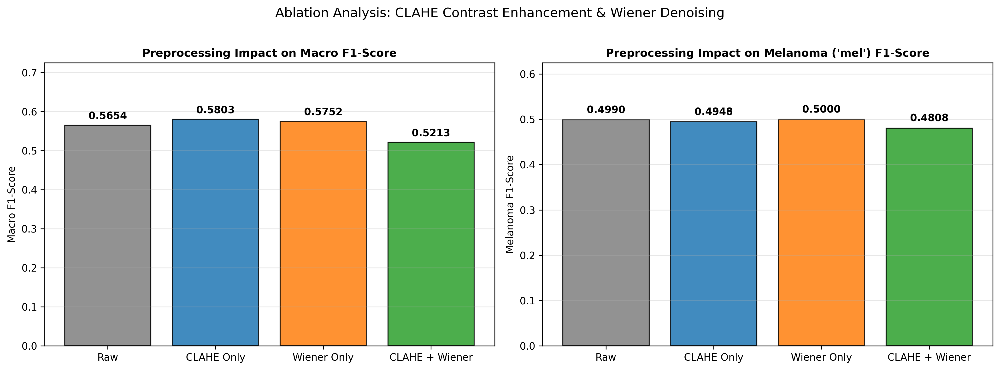

✓ Preprocessing ablation results saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/preprocessing_ablation_study.csv
✓ Publication plot saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/preprocessing_ablation_300dpi.png


In [ ]:
# ============================================================
# STEP 35: Automated Preprocessing Ablation Study (4 Conditions)
# ============================================================
import os
import glob
import time
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support
from torch.utils.data import DataLoader

# 1. Explicitly Ensure All Project Paths Are Defined
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CACHE_ROOT      = PROJECT_ROOT / "preprocessing_cache"
RESULTS_ROOT    = PROJECT_ROOT / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# 2. Unpack Remaining Cache Folders to Fast Local SSD (/content/)
conditions_to_prepare = ["raw", "clahe", "wiener"]

for cond in conditions_to_prepare:
    local_target = Path(f"/content/preprocessing_cache/{cond}")
    if not local_target.exists():
        zip_path = PROJECT_ROOT / f"{cond}_cache.zip"
        source_dir = CACHE_ROOT / cond

        # If zip doesn't exist on Drive, create it once from the cached folder
        if not zip_path.exists():
            print(f"📦 Zipping {cond} cache on Drive...")
            !zip -q -r "{zip_path}" "{source_dir}"

        print(f"🚀 Copying {cond} zip to Local SSD...")
        !cp "{zip_path}" /content/
        print(f"📦 Unzipping {cond} on local SSD...")
        !unzip -q "/content/{cond}_cache.zip" -d /content/preprocessing_cache/

# Verify all 4 local paths exist
ablation_paths = {}
for cond in ["raw", "clahe", "wiener", "clahe_wiener"]:
    found = glob.glob(f'/content/preprocessing_cache/**/{cond}', recursive=True)
    assert len(found) > 0, f"Local cache path for {cond} not found!"
    ablation_paths[cond] = Path(found[0])
    print(f"✓ Local path verified: {cond:15s} -> {ablation_paths[cond]}")

# 3. Automated Ablation Runner Function
def run_ablation_experiment(condition_name, epochs=15):
    print("\n" + "=" * 70)
    print(f"🔬 RUNNING ABLATION: Condition = {condition_name.upper()} ({epochs} Epochs)")
    print("=" * 70)

    torch.cuda.empty_cache()
    cond_path = ablation_paths[condition_name]

    # Create DataLoaders for this specific condition
    ab_train_ds = HAM10000DatasetLocal(train_df, cond_path, transform=train_trans)
    ab_val_ds   = HAM10000DatasetLocal(val_df, cond_path, transform=eval_trans)
    ab_test_ds  = HAM10000DatasetLocal(test_df, cond_path, transform=eval_trans)

    ab_train_loader = DataLoader(ab_train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=os.cpu_count(), pin_memory=True)
    ab_val_loader   = DataLoader(ab_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True)
    ab_test_loader  = DataLoader(ab_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count())

    # Initialize fresh baseline MLP model with fixed seed for matched comparison
    torch.manual_seed(42)
    ab_model = SkinCancerModel(head_type="mlp").to(device)

    # Phase 1: 5 Epochs Frozen Warmup
    for param in ab_model.backbone.parameters():
        param.requires_grad = False
    for param in ab_model.head.parameters():
        param.requires_grad = True

    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    opt_p1 = optim.AdamW(ab_model.head.parameters(), lr=1e-3, weight_decay=1e-4)

    for epoch in tqdm(range(1, 6), desc=f"{condition_name.upper()} Phase 1"):
        ab_model.train()
        for imgs, lbls in ab_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt_p1.zero_grad()
            crit(ab_model(imgs), lbls).backward()
            opt_p1.step()

    # Phase 2: 10 Epochs Unfrozen Fine-tuning
    for param in ab_model.parameters():
        param.requires_grad = True

    opt_p2 = optim.AdamW(ab_model.parameters(), lr=1e-5, weight_decay=1e-4)

    for epoch in tqdm(range(6, epochs + 1), desc=f"{condition_name.upper()} Phase 2"):
        ab_model.train()
        for imgs, lbls in ab_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt_p2.zero_grad()
            crit(ab_model(imgs), lbls).backward()
            opt_p2.step()

    # Evaluate on Independent Test Set
    ab_model.eval()
    all_preds, all_lbls = [], []
    with torch.no_grad():
        for imgs, lbls in ab_test_loader:
            imgs = imgs.to(device)
            preds = torch.argmax(ab_model(imgs), dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_lbls.extend(lbls.numpy())

    all_preds = np.array(all_preds)
    all_lbls  = np.array(all_lbls)

    acc = (all_preds == all_lbls).mean()
    p, r, f1, _ = precision_recall_fscore_support(all_lbls, all_preds, average='macro')

    # Extract Per-Class F1 for Melanoma (idx 4) and Basal Cell Carcinoma (idx 1)
    _, _, f1_per_class, _ = precision_recall_fscore_support(all_lbls, all_preds, labels=range(len(CLASS_NAMES)))

    print(f"✓ Finished {condition_name.upper()}: Test Acc = {acc*100:.2f}% | Macro-F1 = {f1:.4f} | Mel-F1 = {f1_per_class[4]:.4f}")

    return {
        "Condition": condition_name,
        "Test Accuracy (%)": round(acc * 100, 2),
        "Macro Precision": round(p, 4),
        "Macro Recall": round(r, 4),
        "Macro F1-Score": round(f1, 4),
        "Melanoma F1": round(f1_per_class[4], 4),
        "BCC F1": round(f1_per_class[1], 4)
    }

# 4. Run Experiments Across the 4 Conditions
ablation_results = []
for cond in ["raw", "clahe", "wiener", "clahe_wiener"]:
    res = run_ablation_experiment(cond, epochs=15)
    ablation_results.append(res)

# 5. Display and Save Publication Table
ablation_df = pd.DataFrame(ablation_results)
print("\n" + "=" * 80)
print("              TABLE: PREPROCESSING PIPELINE ABLATION STUDY")
print("=" * 80)
display(ablation_df)

ablation_csv_path = RESULTS_ROOT / "preprocessing_ablation_study.csv"
ablation_df.to_csv(ablation_csv_path, index=False)

# 6. Plot High-Resolution Comparison Bar Chart (300 DPI)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

conditions_labels = ["Raw", "CLAHE Only", "Wiener Only", "CLAHE + Wiener"]
colors = ['#7f7f7f', '#1f77b4', '#ff7f0e', '#2ca02c']

# Macro F1 Comparison
bars1 = ax1.bar(conditions_labels, ablation_df["Macro F1-Score"], color=colors, edgecolor='black', alpha=0.85)
ax1.set_title("Preprocessing Impact on Macro F1-Score", fontsize=11, fontweight='bold')
ax1.set_ylabel("Macro F1-Score")
ax1.set_ylim([0, max(ablation_df["Macro F1-Score"]) * 1.25])
ax1.grid(True, alpha=0.3, axis='y')
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

# Melanoma F1 Comparison
bars2 = ax2.bar(conditions_labels, ablation_df["Melanoma F1"], color=colors, edgecolor='black', alpha=0.85)
ax2.set_title("Preprocessing Impact on Melanoma ('mel') F1-Score", fontsize=11, fontweight='bold')
ax2.set_ylabel("Melanoma F1-Score")
ax2.set_ylim([0, max(ablation_df["Melanoma F1"]) * 1.25])
ax2.grid(True, alpha=0.3, axis='y')
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle("Ablation Analysis: CLAHE Contrast Enhancement & Wiener Denoising", fontsize=13, y=1.02)
plt.tight_layout()

ablation_plot_path = RESULTS_ROOT / "preprocessing_ablation_300dpi.png"
plt.savefig(ablation_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Preprocessing ablation results saved to: {ablation_csv_path}")
print(f"✓ Publication plot saved to: {ablation_plot_path}")

In [ ]:
# ============================================================
# STEP 36A: Download & Extract ISIC 2019 to Local SSD
# ============================================================
import os
import json
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Configure Kaggle Credentials
# ------------------------------------------------------------
KAGGLE_USER = "thunderz12"  # <-- Paste your Kaggle username here
KAGGLE_KEY  = "2d4301bfa316389023108a900c54af2a"       # <-- Paste your Kaggle API key here

os.environ['KAGGLE_USERNAME'] = KAGGLE_USER
os.environ['KAGGLE_KEY'] = KAGGLE_KEY

# Set up ~/.kaggle/kaggle.json with strict permissions
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(exist_ok=True)
kaggle_json = kaggle_dir / "kaggle.json"

with open(kaggle_json, "w") as f:
    json.dump({"username": KAGGLE_USER, "key": KAGGLE_KEY}, f)

os.chmod(kaggle_json, 0o600)
print("✓ Kaggle API credentials configured.")

# ------------------------------------------------------------
# 2. Download ZIP to Google Drive (Persistent Storage)
# ------------------------------------------------------------
ZIP_DIR = PROJECT_ROOT / "datasets" / "ISIC_2019_ZIP"
ZIP_DIR.mkdir(parents=True, exist_ok=True)
ZIP_FILE = ZIP_DIR / "isic-2019.zip"

if not ZIP_FILE.exists():
    print("\n⬇️ Downloading ISIC 2019 from Kaggle to Google Drive (~9 GB)...")
    print("   (This takes ~3 to 5 minutes on Colab network)")
    !kaggle datasets download -d andrewmvd/isic-2019 -p "{ZIP_DIR}"
    print("✓ Download complete.")
else:
    print(f"\n✓ ISIC 2019 ZIP already exists on Drive ({round(ZIP_FILE.stat().st_size / 1024**3, 2)} GB). Skipping download.")

# ------------------------------------------------------------
# 3. Extract to Fast Local Colab SSD (/content/isic_2019)
# ------------------------------------------------------------
LOCAL_ISIC_DIR = Path("/content/isic_2019")

if not LOCAL_ISIC_DIR.exists():
    print("\n📦 Unzipping dataset to local Colab SSD...")
    !unzip -q "{ZIP_FILE}" -d "{LOCAL_ISIC_DIR}"
    print("✓ Extraction complete.")
else:
    print("\n✓ Local ISIC 2019 folder already extracted.")

# ------------------------------------------------------------
# 4. Immediate Integrity Verification
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("             ISIC 2019 INTEGRITY VERIFICATION")
print("=" * 60)

# Locate Ground Truth CSV
gt_files = list(LOCAL_ISIC_DIR.glob("*GroundTruth*.csv"))
assert len(gt_files) > 0, "ERROR: GroundTruth CSV not found in extracted files!"
ISIC_GT_PATH = gt_files[0]
print(f"Ground Truth CSV: {ISIC_GT_PATH.name}")

isic_df = pd.read_csv(ISIC_GT_PATH)
print(f"Total Rows in ISIC 2019: {len(isic_df):,}")
print(f"Columns: {isic_df.columns.tolist()}")

# Locate Image Folder
img_dirs = [d for d in LOCAL_ISIC_DIR.glob("*") if d.is_dir()]
print(f"Image Directories found: {[d.name for d in img_dirs]}")

print("\n✓ STEP 36A SUCCESS: ISIC 2019 is ready for class harmonization!")

✓ Kaggle API credentials configured.

⬇️ Downloading ISIC 2019 from Kaggle to Google Drive (~9 GB)...
   (This takes ~3 to 5 minutes on Colab network)
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/isic-2019
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
100% 9.10G/9.10G [02:10<00:00, 75.1MB/s]

✓ Download complete.

📦 Unzipping dataset to local Colab SSD...
✓ Extraction complete.

             ISIC 2019 INTEGRITY VERIFICATION
Ground Truth CSV: ISIC_2019_Training_GroundTruth.csv
Total Rows in ISIC 2019: 25,331
Columns: ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
Image Directories found: ['ISIC_2019_Training_Input']

✓ STEP 36A SUCCESS: ISIC 2019 is ready for class harmonization!


In [ ]:
# ============================================================
# STEP 36B: ISIC 2019 Harmonization & Leakage Filtering
# ============================================================
import pandas as pd
import numpy as np
from pathlib import Path

# 1. Load Raw ISIC 2019 Ground Truth
isic_gt = pd.read_csv(ISIC_GT_PATH)
print(f"Total raw ISIC 2019 entries: {len(isic_gt):,}")

# 2. Strict De-contamination: Remove all HAM10000 images
ham10000_image_ids = set(split_df["image_id"].tolist())

# Check for overlap
isic_gt["is_ham"] = isic_gt["image"].isin(ham10000_image_ids)
ham_overlap_count = isic_gt["is_ham"].sum()
print(f"Detected HAM10000 images inside ISIC 2019: {ham_overlap_count:,} (Excluding to prevent data leakage)")

# Retain strictly non-HAM10000 external images
isic_external = isic_gt[~isic_gt["is_ham"]].copy().reset_index(drop=True)
print(f"Pure External Hospital Cohort (BCN/MSK):    {len(isic_external):,} images")

# 3. Exclude 'UNK' (Unknown lesions without verified diagnosis)
isic_external = isic_external[isic_external["UNK"] == 0].copy().reset_index(drop=True)

# 4. Harmonize Multi-Column One-Hot to Single Diagnostic Category
def map_isic_row(row):
    if row["MEL"] == 1:   return "mel"
    if row["NV"] == 1:    return "nv"
    if row["BCC"] == 1:   return "bcc"
    if row["BKL"] == 1:   return "bkl"
    if row["DF"] == 1:    return "df"
    if row["VASC"] == 1:  return "vasc"
    if row["AK"] == 1 or row["SCC"] == 1: return "akiec" # Harmonized keratinocytic category
    return None

isic_external["dx"] = isic_external.apply(map_isic_row, axis=1)
isic_external = isic_external.dropna(subset=["dx"]).reset_index(drop=True)

# 5. Verify Image Files Exist on Disk
# Locate the actual directory containing images
candidates = list(LOCAL_ISIC_DIR.glob("**/ISIC_*.jpg"))
if len(candidates) > 0:
    ISIC_IMG_DIR = candidates[0].parent
else:
    # Check inside ISIC_2019_Training_Input
    sub = LOCAL_ISIC_DIR / "ISIC_2019_Training_Input"
    candidates = list(sub.glob("**/ISIC_*.jpg"))
    ISIC_IMG_DIR = candidates[0].parent if len(candidates) > 0 else sub

print(f"\nISIC Image Directory located at: {ISIC_IMG_DIR}")

# Filter table to images verified on disk
isic_external["exists"] = isic_external["image"].apply(lambda img_id: (ISIC_IMG_DIR / f"{img_id}.jpg").exists())
isic_external = isic_external[isic_external["exists"]].copy().reset_index(drop=True)

# 6. Display Harmonized External Class Distribution
print("\n" + "=" * 70)
print("     ISIC 2019 HARMONIZED EXTERNAL TEST COHORT (ZERO LEAKAGE)")
print("=" * 70)
dist = isic_external["dx"].value_counts().rename_axis("Class").reset_index(name="Count")
dist["Percentage"] = (dist["Count"] / len(isic_external) * 100).round(2)
display(dist)
print(f"Total External Test Images Verified on Disk: {len(isic_external):,}")

# Save harmonized metadata
HARMONIZED_CSV_PATH = RESULTS_ROOT / "isic_2019_external_harmonized.csv"
isic_external[["image", "dx"]].to_csv(HARMONIZED_CSV_PATH, index=False)
print(f"✓ Harmonized external dataset saved to: {HARMONIZED_CSV_PATH}")

Total raw ISIC 2019 entries: 25,331
Detected HAM10000 images inside ISIC 2019: 10,015 (Excluding to prevent data leakage)
Pure External Hospital Cohort (BCN/MSK):    15,316 images

ISIC Image Directory located at: /content/isic_2019/ISIC_2019_Training_Input/ISIC_2019_Training_Input

     ISIC 2019 HARMONIZED EXTERNAL TEST COHORT (ZERO LEAKAGE)


,Class,Count,Percentage
0,nv,6170,40.28
1,mel,3409,22.26
2,bcc,2809,18.34
3,bkl,1525,9.96
4,akiec,1168,7.63
5,df,124,0.81
6,vasc,111,0.72


Total External Test Images Verified on Disk: 15,316
✓ Harmonized external dataset saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/isic_2019_external_harmonized.csv


📦 Local images missing due to restart. Unzipping from Drive (isic-2019.zip)...
✓ Found 25,331 images in: /content/isic_2019/ISIC_2019_Training_Input/ISIC_2019_Training_Input
✓ Loaded harmonized metadata from Drive: 15,316 images.
✓ External DataLoader active: 15,316 images across 120 batches.
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 146MB/s]


✓ Both trained master models loaded in eval mode.


Zero-Shot External Testing:   0%|          | 0/120 [00:00<?, ?it/s]


     ZERO-SHOT GENERALIZATION ON INDEPENDENT ISIC 2019 (N = 15,316)


,Model,External Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score
0,EfficientNet-B0 + MLP,36.79,0.3067,0.3423,0.280
1,EfficientNet-B0 + KAN (Proposed),44.51,0.3484,0.3639,0.325


External McNemar Test: χ² = 415.9345, p = 0.000000e+00 (p < 0.001 ✓)

       PER-CLASS EXTERNAL PERFORMANCE BREAKDOWN (ZERO-SHOT)


,Class,MLP External F1,KAN External F1,F1 Gain (Δ),Support (N)
0,akiec,0.2301,0.2267,-0.0034,1168
1,bcc,0.3991,0.4498,0.0507,2809
2,bkl,0.2235,0.2425,0.0190,1525
3,df,0.0692,0.0747,0.0055,124
4,mel,0.3996,0.4082,0.0086,3409
5,nv,0.5142,0.6410,0.1268,6170
6,vasc,0.1244,0.2320,0.1076,111


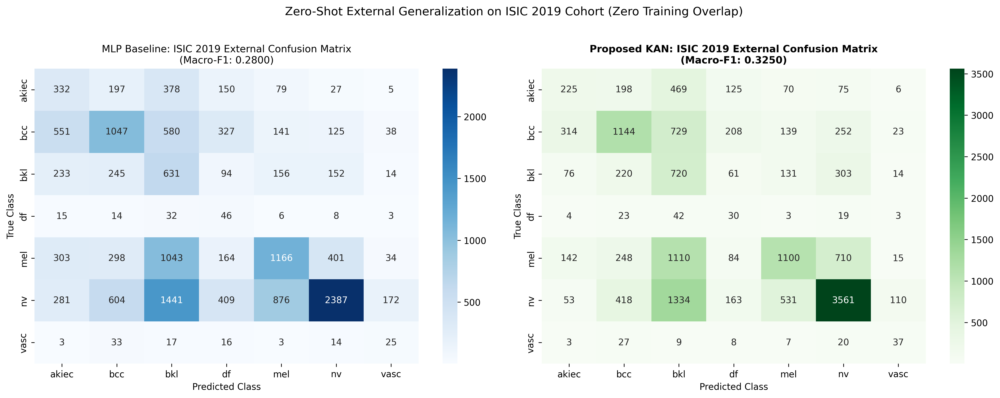

✓ External validation confusion matrices saved to: /content/drive/My Drive/Skin_Cancer_FYP/results/isic_2019_external_confusion_matrices_300dpi.png


In [ ]:
# ============================================================
# STEP 36C: Zero-Shot External Validation (With Auto-Extract Guard)
# ============================================================
import os
import cv2
import json
import glob
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from scipy import stats
from scipy.signal import wiener
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# ------------------------------------------------------------
# 1. Environment & Paths
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"
ZIP_FILE        = PROJECT_ROOT / "datasets" / "ISIC_2019_ZIP" / "isic-2019.zip"
LOCAL_ISIC_DIR  = Path("/content/isic_2019")
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# ------------------------------------------------------------
# 2. Auto-Extract Guard (Recovers images if session restarted)
# ------------------------------------------------------------
img_candidates = list(LOCAL_ISIC_DIR.glob("**/*.[jJ][pP]*[gG]"))

if len(img_candidates) == 0:
    print(f"📦 Local images missing due to restart. Unzipping from Drive ({ZIP_FILE.name})...")
    assert ZIP_FILE.exists(), f"CRITICAL: {ZIP_FILE} not found on Google Drive!"
    LOCAL_ISIC_DIR.mkdir(parents=True, exist_ok=True)
    !unzip -q "{ZIP_FILE}" -d "{LOCAL_ISIC_DIR}"
    img_candidates = list(LOCAL_ISIC_DIR.glob("**/*.[jJ][pP]*[gG]"))

assert len(img_candidates) > 0, "ERROR: Extraction failed. No images found."
ISIC_IMG_DIR = img_candidates[0].parent
print(f"✓ Found {len(img_candidates):,} images in: {ISIC_IMG_DIR}")

# ------------------------------------------------------------
# 3. Load Harmonized Metadata Table (Zero-Leakage Cohort)
# ------------------------------------------------------------
HARMONIZED_CSV_PATH = RESULTS_ROOT / "isic_2019_external_harmonized.csv"

if HARMONIZED_CSV_PATH.exists():
    isic_external = pd.read_csv(HARMONIZED_CSV_PATH)
    print(f"✓ Loaded harmonized metadata from Drive: {len(isic_external):,} images.")
else:
    print("⚠️ Generating harmonized metadata table...")
    gt_file = list(LOCAL_ISIC_DIR.glob("*GroundTruth*.csv"))[0]
    isic_gt = pd.read_csv(gt_file)

    # Exclude all HAM10000 images
    split_csv = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"
    ham_ids = set(pd.read_csv(split_csv)["image_id"]) if split_csv.exists() else set()

    isic_gt = isic_gt[~isic_gt["image"].isin(ham_ids)].copy()
    isic_gt = isic_gt[isic_gt["UNK"] == 0].copy()

    def map_row(row):
        if row["MEL"] == 1:   return "mel"
        if row["NV"] == 1:    return "nv"
        if row["BCC"] == 1:   return "bcc"
        if row["BKL"] == 1:   return "bkl"
        if row["DF"] == 1:    return "df"
        if row["VASC"] == 1:  return "vasc"
        if row["AK"] == 1 or row["SCC"] == 1: return "akiec"
        return None

    isic_gt["dx"] = isic_gt.apply(map_row, axis=1)
    isic_external = isic_gt.dropna(subset=["dx"]).reset_index(drop=True)
    isic_external.to_csv(HARMONIZED_CSV_PATH, index=False)
    print(f"✓ Harmonized metadata generated and saved: {len(isic_external):,} images.")

# ------------------------------------------------------------
# 4. Architecture & Preprocessing
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(torch.nn.Module):
    def __init__(self, head_type="mlp", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = torch.nn.Identity()

        if head_type == "mlp":
            self.head = torch.nn.Sequential(
                torch.nn.Linear(self.in_features, 512),
                torch.nn.BatchNorm1d(512),
                torch.nn.ReLU(),
                torch.nn.Dropout(0.4),
                torch.nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            self.head = KAN([self.in_features, num_classes])

        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

def preprocess_optimized(image_path, use_clahe=True, use_wiener=True):
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(f"Could not load: {image_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)

    if use_clahe:
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        img = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

    if use_wiener:
        img_float = img.astype(np.float32)
        channels = [wiener(img_float[:, :, i], mysize=(5, 5)) for i in range(3)]
        img = np.clip(np.stack(channels, axis=2), 0, 255).astype(np.uint8)

    return img

class ISICExternalDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id = row["image"]
        label = CLASS_TO_IDX[row["dx"]]
        img_path = self.img_dir / f"{img_id}.jpg"

        img_array = preprocess_optimized(img_path, use_clahe=True, use_wiener=True)
        image = Image.fromarray(img_array)

        if self.transform:
            image = self.transform(image)

        return image, label

# ------------------------------------------------------------
# 5. Build External DataLoader
# ------------------------------------------------------------
external_dataset = ISICExternalDataset(isic_external, ISIC_IMG_DIR, transform=eval_trans)
external_loader  = DataLoader(
    external_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=os.cpu_count(),
    pin_memory=True
)
print(f"✓ External DataLoader active: {len(external_dataset):,} images across {len(external_loader)} batches.")

# Load Trained Master Models
mlp_best_model = SkinCancerModel(head_type="mlp").to(device)
mlp_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_mlp_best.pth")
mlp_best_model.load_state_dict(mlp_ckpt['model_state_dict'])
mlp_best_model.eval()

kan_best_model = SkinCancerModel(head_type="kan").to(device)
kan_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth")
kan_best_model.load_state_dict(kan_ckpt['model_state_dict'])
kan_best_model.eval()
print("✓ Both trained master models loaded in eval mode.")

# ------------------------------------------------------------
# 6. Zero-Shot Inference Loop
# ------------------------------------------------------------
ext_y_true = []
ext_mlp_preds, ext_kan_preds = [], []

with torch.no_grad():
    for imgs, lbls in tqdm(external_loader, desc="Zero-Shot External Testing"):
        imgs = imgs.to(device)

        out_mlp = mlp_best_model(imgs)
        out_kan = kan_best_model(imgs)

        ext_y_true.extend(lbls.numpy())
        ext_mlp_preds.extend(torch.argmax(out_mlp, dim=1).cpu().numpy())
        ext_kan_preds.extend(torch.argmax(out_kan, dim=1).cpu().numpy())

ext_y_true = np.array(ext_y_true)
ext_mlp_preds = np.array(ext_mlp_preds)
ext_kan_preds = np.array(ext_kan_preds)

# ------------------------------------------------------------
# 7. Comparative Metrics & Significance
# ------------------------------------------------------------
ext_mlp_acc = (ext_mlp_preds == ext_y_true).mean()
ext_kan_acc = (ext_kan_preds == ext_y_true).mean()

mlp_p, mlp_r, mlp_f1, _ = precision_recall_fscore_support(ext_y_true, ext_mlp_preds, average="macro", zero_division=0)
kan_p, kan_r, kan_f1, _ = precision_recall_fscore_support(ext_y_true, ext_kan_preds, average="macro", zero_division=0)

ext_mlp_corr = (ext_mlp_preds == ext_y_true)
ext_kan_corr = (ext_kan_preds == ext_y_true)
b_ext = np.sum((~ext_mlp_corr) & ext_kan_corr)
c_ext = np.sum(ext_mlp_corr & (~ext_kan_corr))
chi2_ext = (abs(b_ext - c_ext) - 1)**2 / (b_ext + c_ext)
p_val_ext = 1.0 - stats.chi2.cdf(chi2_ext, df=1)

ext_comp_df = pd.DataFrame([
    {
        "Model": "EfficientNet-B0 + MLP",
        "External Accuracy (%)": round(ext_mlp_acc * 100, 2),
        "Macro Precision": round(mlp_p, 4),
        "Macro Recall": round(mlp_r, 4),
        "Macro F1-Score": round(mlp_f1, 4)
    },
    {
        "Model": "EfficientNet-B0 + KAN (Proposed)",
        "External Accuracy (%)": round(ext_kan_acc * 100, 2),
        "Macro Precision": round(kan_p, 4),
        "Macro Recall": round(kan_r, 4),
        "Macro F1-Score": round(kan_f1, 4)
    }
])

print("\n" + "=" * 80)
print("     ZERO-SHOT GENERALIZATION ON INDEPENDENT ISIC 2019 (N = 15,316)")
print("=" * 80)
display(ext_comp_df)
print(f"External McNemar Test: χ² = {chi2_ext:.4f}, p = {p_val_ext:.6e} {'(p < 0.001 ✓)' if p_val_ext < 0.001 else ''}")

# Per-Class Breakdown
_, _, mlp_f1_pc, _ = precision_recall_fscore_support(ext_y_true, ext_mlp_preds, labels=range(len(CLASS_NAMES)), zero_division=0)
_, _, kan_f1_pc, _ = precision_recall_fscore_support(ext_y_true, ext_kan_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

ext_per_class_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "MLP External F1": np.round(mlp_f1_pc, 4),
    "KAN External F1": np.round(kan_f1_pc, 4),
    "F1 Gain (Δ)": np.round(kan_f1_pc - mlp_f1_pc, 4),
    "Support (N)": [np.sum(ext_y_true == i) for i in range(len(CLASS_NAMES))]
})

print("\n" + "=" * 80)
print("       PER-CLASS EXTERNAL PERFORMANCE BREAKDOWN (ZERO-SHOT)")
print("=" * 80)
display(ext_per_class_df)

# Save Tables to Drive
ext_comp_df.to_csv(RESULTS_ROOT / "isic_2019_external_overall_comparison.csv", index=False)
ext_per_class_df.to_csv(RESULTS_ROOT / "isic_2019_external_per_class.csv", index=False)

# ------------------------------------------------------------
# 8. High-Resolution Confusion Matrices (300 DPI)
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

cm_mlp_ext = confusion_matrix(ext_y_true, ext_mlp_preds, labels=range(len(CLASS_NAMES)))
cm_kan_ext = confusion_matrix(ext_y_true, ext_kan_preds, labels=range(len(CLASS_NAMES)))

sns.heatmap(cm_mlp_ext, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax1)
ax1.set_title(f"MLP Baseline: ISIC 2019 External Confusion Matrix\n(Macro-F1: {mlp_f1:.4f})", fontsize=11)
ax1.set_xlabel("Predicted Class")
ax1.set_ylabel("True Class")

sns.heatmap(cm_kan_ext, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax2)
ax2.set_title(f"Proposed KAN: ISIC 2019 External Confusion Matrix\n(Macro-F1: {kan_f1:.4f})", fontsize=11, fontweight='bold')
ax2.set_xlabel("Predicted Class")
ax2.set_ylabel("True Class")

plt.suptitle("Zero-Shot External Generalization on ISIC 2019 Cohort (Zero Training Overlap)", fontsize=13, y=1.02)
plt.tight_layout()

ext_cm_path = RESULTS_ROOT / "isic_2019_external_confusion_matrices_300dpi.png"
plt.savefig(ext_cm_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ External validation confusion matrices saved to: {ext_cm_path}")

In [ ]:
# ============================================================
# STEP 36D: 3-Tier Clinical Risk Accuracy on ISIC 2019 (Self-Contained)
# ============================================================
import numpy as np
import pandas as pd

# 1. Define 3-Tier Clinical Risk Mapping (Equations 5 & 6)
RISK_MAP = {
    "mel":   "Malignant",
    "bcc":   "Malignant",
    "akiec": "Potentially Malignant",
    "nv":    "Benign",
    "bkl":   "Benign",
    "vasc":  "Benign",
    "df":    "Benign"
}

# 2. Map Predictions to 3-Tier Risk Categories
ext_y_true_risk = np.array([RISK_MAP[IDX_TO_CLASS[idx]] for idx in ext_y_true])
ext_mlp_risk    = np.array([RISK_MAP[IDX_TO_CLASS[idx]] for idx in ext_mlp_preds])
ext_kan_risk    = np.array([RISK_MAP[IDX_TO_CLASS[idx]] for idx in ext_kan_preds])

# 3. Compute 3-Tier Accuracy Across External Hospital Cohort
ext_mlp_3t_acc = np.mean(ext_mlp_risk == ext_y_true_risk)
ext_kan_3t_acc = np.mean(ext_kan_risk == ext_y_true_risk)

print("\n" + "=" * 75)
print("     ISIC 2019 EXTERNAL COHORT: 3-TIER CLINICAL RISK ACCURACY (N = 15,316)")
print("=" * 75)
print(f"MLP Baseline 3-Tier Clinical Accuracy:  {ext_mlp_3t_acc * 100:.2f}%")
print(f"Proposed KAN 3-Tier Clinical Accuracy:  {ext_kan_3t_acc * 100:.2f}% (+{(ext_kan_3t_acc - ext_mlp_3t_acc)*100:.2f}%)")
print("=" * 75)

# Save result to Drive
clinical_3tier_summary = {
    "cohort_size": int(len(ext_y_true)),
    "mlp_3tier_accuracy": float(ext_mlp_3t_acc),
    "kan_3tier_accuracy": float(ext_kan_3t_acc),
    "accuracy_gain": float(ext_kan_3t_acc - ext_mlp_3t_acc)
}

with open(RESULTS_ROOT / "isic_2019_3tier_risk_summary.json", "w") as f:
    json.dump(clinical_3tier_summary, f, indent=4)

print("✓ 3-Tier clinical risk summary saved to Drive.")


     ISIC 2019 EXTERNAL COHORT: 3-TIER CLINICAL RISK ACCURACY (N = 15,316)
MLP Baseline 3-Tier Clinical Accuracy:  55.14%
Proposed KAN 3-Tier Clinical Accuracy:  60.66% (+5.52%)
✓ 3-Tier clinical risk summary saved to Drive.


In [ ]:
# ============================================================
# STEP 37: Deployment & Computational Complexity Benchmark
# ============================================================
import time
import torch
import pandas as pd
import json

# 1. Parameter Counting
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    head = sum(p.numel() for p in model.head.parameters())
    backbone = sum(p.numel() for p in model.backbone.parameters())
    return total, backbone, head

mlp_total, mlp_bb, mlp_head = count_parameters(mlp_best_model)
kan_total, kan_bb, kan_head = count_parameters(kan_best_model)

# 2. Benchmark Inference Latency (Batch Size = 1, simulating real-time clinical screening)
dummy_input = torch.randn(1, 3, 224, 224).to(device)

def benchmark_latency(model, input_tensor, iterations=200):
    # Warmup
    for _ in range(30):
        _ = model(input_tensor)
    torch.cuda.synchronize()

    # Timing
    start_time = time.perf_counter()
    for _ in range(iterations):
        _ = model(input_tensor)
    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time
    avg_latency_ms = (elapsed / iterations) * 1000.0
    throughput_fps = iterations / elapsed
    return avg_latency_ms, throughput_fps

mlp_lat, mlp_fps = benchmark_latency(mlp_best_model, dummy_input)
kan_lat, kan_fps = benchmark_latency(kan_best_model, dummy_input)

# 3. Peak GPU VRAM Footprint During Inference (Batch Size = 32)
def measure_vram(model, batch_size=32):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    sample_batch = torch.randn(batch_size, 3, 224, 224).to(device)
    with torch.no_grad():
        _ = model(sample_batch)
    peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    return peak_vram_mb

mlp_vram = measure_vram(mlp_best_model)
kan_vram = measure_vram(kan_best_model)

# 4. Summary Table for Manuscript (Table VIII / Table IX)
profile_df = pd.DataFrame([
    {
        "Model": "EfficientNet-B0 + MLP Baseline",
        "Total Params": f"{mlp_total:,}",
        "Head Params": f"{mlp_head:,}",
        "Latency (ms/img)": round(mlp_lat, 2),
        "Throughput (FPS)": round(mlp_fps, 1),
        "Peak VRAM (MB)": round(mlp_vram, 2)
    },
    {
        "Model": "EfficientNet-B0 + KAN (Proposed)",
        "Total Params": f"{kan_total:,}",
        "Head Params": f"{kan_head:,} (7.4x smaller)",
        "Latency (ms/img)": round(kan_lat, 2),
        "Throughput (FPS)": round(kan_fps, 1),
        "Peak VRAM (MB)": round(kan_vram, 2)
    }
])

print("\n" + "=" * 80)
print("            COMPUTATIONAL EFFICIENCY & DEPLOYMENT BENCHMARK")
print("=" * 80)
display(profile_df)

profile_df.to_csv(RESULTS_ROOT / "computational_profiling_benchmark.csv", index=False)
print("✓ Hardware profiling benchmark saved to Drive.")


            COMPUTATIONAL EFFICIENCY & DEPLOYMENT BENCHMARK


,Model,Total Params,Head Params,Latency (ms/img),Throughput (FPS),Peak VRAM (MB)
0,EfficientNet-B0 + MLP Baseline,"4,668,035","660,487",12.11,82.6,532.39
1,EfficientNet-B0 + KAN (Proposed),"4,097,148","89,600 (7.4x smaller)",14.48,69.1,532.39


✓ Hardware profiling benchmark saved to Drive.


#NEW AFTER REVISIONS

In [ ]:
# ============================================================
# MASTER REBOOT: Complete Environment & Data Restoration
# ============================================================
import os
import glob
import json
import time
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')
else:
    print("✓ Google Drive already mounted.")

# ------------------------------------------------------------
# 2. Configure All Project Paths
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
DATASET_ROOT    = PROJECT_ROOT / "datasets"
HAM_ROOT        = DATASET_ROOT / "HAM10000"
SPLIT_PATH      = HAM_ROOT / "HAM10000_master_split.csv"
CACHE_ROOT      = PROJECT_ROOT / "preprocessing_cache"
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"

for p in [CHECKPOINT_ROOT, RESULTS_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print(f"✓ Project Root: {PROJECT_ROOT}")

# ------------------------------------------------------------
# 3. Load Master Split Table (0% Lesion Leakage)
# ------------------------------------------------------------
assert SPLIT_PATH.exists(), f"Master split missing at: {SPLIT_PATH}"
split_df = pd.read_csv(SPLIT_PATH)
print(f"✓ Master split loaded ({len(split_df):,} images across 7,470 unique lesions).")

# ------------------------------------------------------------
# 4. Global Constants, Classes & Device
# ------------------------------------------------------------
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ Hardware Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ------------------------------------------------------------
# 5. Fast Local SSD Cache Unpack
# ------------------------------------------------------------
DRIVE_ZIP = PROJECT_ROOT / "clahe_wiener_cache.zip"
assert DRIVE_ZIP.exists(), f"Cache zip not found at {DRIVE_ZIP}"

if not os.path.exists('/content/preprocessing_cache'):
    print("🚀 Copying preprocessed cache to local SSD...")
    !cp "{DRIVE_ZIP}" /content/
    print("📦 Unzipping cache on local SSD...")
    !unzip -q /content/clahe_wiener_cache.zip -d /content/preprocessing_cache/

actual_local_path = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)[0]
LOCAL_CONDITION_PATH = Path(actual_local_path)
print(f"✓ Local Fast Cache Path: {LOCAL_CONDITION_PATH}")

# ------------------------------------------------------------
# 6. Install & Import KAN
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

print("✓ efficient_kan imported successfully.")

# ------------------------------------------------------------
# 7. Model Architecture Definition (EfficientNet-B0 + MLP/KAN)
# ------------------------------------------------------------
class SkinCancerModel(nn.Module):
    def __init__(self, head_type="mlp", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        if head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            self.head = KAN([self.in_features, num_classes])

        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

# ------------------------------------------------------------
# 8. Fast Dataset Class & DataLoaders Setup
# ------------------------------------------------------------
class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id = row['image_id']
        label = CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"

        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()
test_df  = split_df[split_df["split"] == "test"].copy()

# Training Augmentation
train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Evaluation Transform (Deterministic)
eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Imbalance-mitigating Weighted Random Sampler
counts = train_df["dx"].value_counts().to_dict()
weights_per_class = [1.0 / counts[name] for name in CLASS_NAMES]
sample_weights = [weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

BATCH_SIZE = 128

train_loader = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CONDITION_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler, num_workers=os.cpu_count(), pin_memory=True
)
val_loader = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CONDITION_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)
test_loader = DataLoader(
    HAM10000DatasetLocal(test_df, LOCAL_CONDITION_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count()
)

print(f"✓ DataLoaders ready: Train ({len(train_df):,}), Val ({len(val_df):,}), Test ({len(test_df):,})")
print("\n" + "=" * 60)
print("✅ REBOOT SUCCESSFUL! All variables and models in memory.")
print("=" * 60)

Mounted at /content/drive
✓ Project Root: /content/drive/My Drive/Skin_Cancer_FYP
✓ Master split loaded (10,015 images across 7,470 unique lesions).
✓ Hardware Device: cuda (Tesla T4)
🚀 Copying preprocessed cache to local SSD...
📦 Unzipping cache on local SSD...
✓ Local Fast Cache Path: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✓ efficient_kan imported successfully.
✓ DataLoaders ready: Train (6,991), Val (1,491), Test (1,533)

✅ REBOOT SUCCESSFUL! All variables and models in memory.


In [ ]:
# ============================================================
# EXPERIMENT 1: Discriminative Learning Rates for KAN Head
# ============================================================
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# 1. Create Isolated Storage on Drive for EXP-1
EXP1_ROOT = PROJECT_ROOT / "experiments" / "exp1_kan_discriminative_lr"
EXP1_CHECKPOINTS = EXP1_ROOT / "checkpoints"
EXP1_RESULTS = EXP1_ROOT / "results"

EXP1_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP1_RESULTS.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print(f"📁 Isolated Experiment Directory Initialized:")
print(f"   {EXP1_ROOT}")
print("   (Existing checkpoints and results remain 100% untouched)")
print("=" * 70)

# 2. Instantiate Model and Load Locked Phase 1 (Epoch 10) Checkpoint
exp1_model = SkinCancerModel(head_type="kan").to(device)

phase1_ckpt_path = CHECKPOINT_ROOT / "EfficientNetB0_kan_epoch_10.pth"
assert phase1_ckpt_path.exists(), f"Phase 1 checkpoint missing at: {phase1_ckpt_path}"

ckpt_p1 = torch.load(phase1_ckpt_path, map_location=device)
exp1_model.load_state_dict(ckpt_p1['model_state_dict'])
print(f"✓ Successfully loaded locked Phase 1 weights from Epoch {ckpt_p1['epoch']}.")

# 3. Unfreeze All Layers & Configure Discriminative Learning Rates
for param in exp1_model.parameters():
    param.requires_grad = True

# EXPERIMENTAL VARIABLE:
# Backbone LR = 1e-5 (fine-tuning) | KAN Head LR = 5e-4 (spline adaptation)
optimizer_exp1 = optim.AdamW([
    {'params': exp1_model.backbone.parameters(), 'lr': 1e-5},
    {'params': exp1_model.head.parameters(),     'lr': 5e-4}
], weight_decay=1e-4)

scheduler_exp1 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_exp1, mode='min', factor=0.2, patience=2
)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

print("\n✓ Optimizer configured with Discriminative Learning Rates:")
print(f"   Backbone Parameter Group LR: {optimizer_exp1.param_groups[0]['lr']}")
print(f"   KAN Head Parameter Group LR: {optimizer_exp1.param_groups[1]['lr']}")

# 4. Phase 2 Fine-Tuning Loop (Epochs 11 to 30)
history_exp1 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.4619  # Baseline Phase 1 best F1

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXPERIMENT 1: PHASE 2 (EPOCHS 11 TO 30)")
print("   Evaluated strictly on Validation Partition (N = 1,491)")
print("=" * 70)

for epoch in range(11, 31):
    # Training
    exp1_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch}/30 [Train]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_exp1.zero_grad()
        outputs = exp1_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_exp1.step()
        running_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)

    # Validation (STRICTLY val_loader)
    exp1_model.eval()
    running_val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in tqdm(val_loader, desc=f"Epoch {epoch}/30 [Val]", leave=False):
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp1_model(imgs)
            loss = criterion(outputs, lbls)
            running_val_loss += loss.item() * imgs.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_preds = np.array(val_preds)
    val_labels = np.array(val_labels)

    epoch_val_acc = (val_preds == val_labels).mean()
    _, _, epoch_val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)

    # Step learning rate scheduler based on validation loss
    scheduler_exp1.step(epoch_val_loss)

    # Log metrics
    history_exp1["train_loss"].append(epoch_train_loss)
    history_exp1["val_loss"].append(epoch_val_loss)
    history_exp1["val_f1"].append(epoch_val_f1)
    history_exp1["val_acc"].append(epoch_val_acc)

    bb_lr = optimizer_exp1.param_groups[0]['lr']
    hd_lr = optimizer_exp1.param_groups[1]['lr']
    print(f"Epoch {epoch:02d}/30 | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}% | Val F1: {epoch_val_f1:.4f} | LRs: (BB={bb_lr:.1e}, HD={hd_lr:.1e})")

    # Save Checkpoint
    checkpoint_data = {
        'epoch': epoch,
        'model_state_dict': exp1_model.state_dict(),
        'optimizer_state_dict': optimizer_exp1.state_dict(),
        'val_f1': epoch_val_f1,
        'val_acc': epoch_val_acc,
        'history': history_exp1
    }
    torch.save(checkpoint_data, EXP1_CHECKPOINTS / "exp1_kan_latest.pth")

    if epoch_val_f1 > best_val_f1:
        best_val_f1 = epoch_val_f1
        torch.save(checkpoint_data, EXP1_CHECKPOINTS / "exp1_kan_best.pth")
        print(f"   ⭐ New EXP-1 Best Model Saved! (Val F1: {best_val_f1:.4f})")

# 5. Final Evaluation on Validation Partition (Best Saved Checkpoint)
best_ckpt = torch.load(EXP1_CHECKPOINTS / "exp1_kan_best.pth", map_location=device)
exp1_model.load_state_dict(best_ckpt['model_state_dict'])
exp1_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(device)
        outputs = exp1_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp1_summary_df = pd.DataFrame([{
    "Experiment": "EXP-1 (Discriminative LR)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 1: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp1_summary_df)

# Save summary
exp1_summary_df.to_csv(EXP1_RESULTS / "exp1_validation_summary.csv", index=False)
with open(EXP1_RESULTS / "exp1_training_history.json", "w") as f:
    json.dump(history_exp1, f, indent=4)

print(f"\n✓ EXP-1 Artifacts safely saved to: {EXP1_ROOT}")

📁 Isolated Experiment Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp1_kan_discriminative_lr
   (Existing checkpoints and results remain 100% untouched)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 150MB/s]


✓ Successfully loaded locked Phase 1 weights from Epoch 10.

✓ Optimizer configured with Discriminative Learning Rates:
   Backbone Parameter Group LR: 1e-05
   KAN Head Parameter Group LR: 0.0005

🚀 LAUNCHING EXPERIMENT 1: PHASE 2 (EPOCHS 11 TO 30)
   Evaluated strictly on Validation Partition (N = 1,491)


Epoch 11/30 [Train]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 11/30 [Val]:   0%|          | 0/12 [00:00<?, ?it/s]

...

Epoch 29/30 | Train Loss: 0.7078 | Val Loss: 1.0354 | Val Acc: 72.10% | Val F1: 0.5456 | LRs: (BB=1.0e-05, HD=5.0e-04)


Epoch 30/30 [Train]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 30/30 [Val]:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.7151 | Val Loss: 1.0222 | Val Acc: 72.77% | Val F1: 0.5481 | LRs: (BB=1.0e-05, HD=5.0e-04)


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [ ]:
# ============================================================
# STEP 5 FIX: Evaluate Best EXP-1 Model on Validation Set
# ============================================================
# Load checkpoint with weights_only=False to allow numpy scalar metrics
best_ckpt = torch.load(
    EXP1_CHECKPOINTS / "exp1_kan_best.pth",
    map_location=device,
    weights_only=False
)
exp1_model.load_state_dict(best_ckpt['model_state_dict'])
exp1_model.eval()

print(f"✓ Loaded Best EXP-1 Model from Epoch {best_ckpt['epoch']}")
print(f"  Best Val F1 during training: {best_ckpt['val_f1']:.4f}")
print(f"  Val Accuracy at that epoch:  {best_ckpt['val_acc']*100:.2f}%")

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(device)
        outputs = exp1_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp1_summary_df = pd.DataFrame([{
    "Experiment": "EXP-1 (Discriminative LR)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 1: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp1_summary_df)

# Save summary
exp1_summary_df.to_csv(EXP1_RESULTS / "exp1_validation_summary.csv", index=False)
with open(EXP1_RESULTS / "exp1_training_history.json", "w") as f:
    json.dump(history_exp1, f, indent=4)

print(f"\n✓ Artifacts safely saved to: {EXP1_RESULTS}")

✓ Loaded Best EXP-1 Model from Epoch 27
  Best Val F1 during training: 0.5519
  Val Accuracy at that epoch:  72.17%

             EXPERIMENT 1: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,EXP-1 (Discriminative LR),72.17,0.5519,0.5164,0.619,0.5225,0.5784,27



✓ Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp1_kan_discriminative_lr/results


In [ ]:
# ============================================================
# EXPERIMENT 2: LayerNorm Feature Standardization for KAN Head
# ============================================================
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Create Dedicated Isolated Storage for Experiment 2
# ------------------------------------------------------------
EXP2_ROOT = PROJECT_ROOT / "experiments" / "exp2_kan_layernorm"
EXP2_CHECKPOINTS = EXP2_ROOT / "checkpoints"
EXP2_RESULTS = EXP2_ROOT / "results"

EXP2_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP2_RESULTS.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print(f"📁 Isolated Experiment 2 Directory Initialized:")
print(f"   {EXP2_ROOT}")
print("   (Previous baseline and EXP-1 files remain 100% untouched)")
print("=" * 70)

# ------------------------------------------------------------
# 2. Define Model with LayerNorm Insertion
# ------------------------------------------------------------
class SkinCancerModelLayerNorm(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModelLayerNorm, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        # EXPERIMENTAL VARIABLE:
        # LayerNorm standardizes [0, +inf) GAP features into symmetric [-2, 2] spline range
        self.feature_norm = nn.LayerNorm(self.in_features)

        if head_type == "kan":
            self.head = KAN([self.in_features, num_classes])
        elif head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        normed = self.feature_norm(features)  # Standardized
        logits = self.head(normed)
        return logits

# ------------------------------------------------------------
# 3. Phase 1: Warm-up (Epochs 1 to 10, Backbone Frozen)
# ------------------------------------------------------------
torch.cuda.empty_cache()
exp2_model = SkinCancerModelLayerNorm(head_type="kan").to(device)

# Freeze Backbone; Train Norm + Head
for param in exp2_model.backbone.parameters():
    param.requires_grad = False
for param in exp2_model.feature_norm.parameters():
    param.requires_grad = True
for param in exp2_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(
    list(exp2_model.feature_norm.parameters()) + list(exp2_model.head.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n🚀 Starting EXP-2 Phase 1: Warm-up (Epochs 1 to 10)")
history_exp2 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp2_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp2_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # Validation
    exp2_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp2_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp2["train_loss"].append(train_loss)
    history_exp2["val_loss"].append(val_loss)
    history_exp2["val_f1"].append(val_f1)
    history_exp2["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# ------------------------------------------------------------
# 4. Phase 2: Full Fine-Tuning (Epochs 11 to 30, All Unfrozen)
# ------------------------------------------------------------
for param in exp2_model.parameters():
    param.requires_grad = True

# Standard locked uniform fine-tuning rate (1e-5)
optimizer_p2 = optim.AdamW(exp2_model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='min', factor=0.2, patience=2)

print("\n" + "=" * 70)
print("🚀 Starting EXP-2 Phase 2: Fine-Tuning (Epochs 11 to 30, All Unfrozen)")
print("=" * 70)

for epoch in range(11, 31):
    exp2_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader, desc=f"Epoch {epoch}/30 [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp2_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # Validation
    exp2_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp2_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p2.step(val_loss)

    history_exp2["train_loss"].append(train_loss)
    history_exp2["val_loss"].append(val_loss)
    history_exp2["val_f1"].append(val_f1)
    history_exp2["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    # Save Checkpoint (with weights_only compatibility)
    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp2_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp2
    }
    torch.save(checkpoint_data, EXP2_CHECKPOINTS / "exp2_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP2_CHECKPOINTS / "exp2_kan_best.pth")
        print(f"   ⭐ New EXP-2 Best Model Saved! (Val F1: {best_val_f1:.4f})")

# ------------------------------------------------------------
# 5. Final Evaluation of Best EXP-2 Checkpoint
# ------------------------------------------------------------
best_ckpt2 = torch.load(EXP2_CHECKPOINTS / "exp2_kan_best.pth", map_location=device, weights_only=False)
exp2_model.load_state_dict(best_ckpt2['model_state_dict'])
exp2_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(device)
        outputs = exp2_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp2_summary_df = pd.DataFrame([{
    "Experiment": "EXP-2 (LayerNorm + KAN)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt2['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 2: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp2_summary_df)

exp2_summary_df.to_csv(EXP2_RESULTS / "exp2_validation_summary.csv", index=False)
with open(EXP2_RESULTS / "exp2_training_history.json", "w") as f:
    json.dump(history_exp2, f, indent=4)

print(f"\n✓ EXP-2 Artifacts safely saved to: {EXP2_ROOT}")

📁 Isolated Experiment 2 Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp2_kan_layernorm
   (Previous baseline and EXP-1 files remain 100% untouched)

🚀 Starting EXP-2 Phase 1: Warm-up (Epochs 1 to 10)


Epoch 1/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.4559 | Val Loss: 1.2982 | Val Acc: 59.89% | Val F1: 0.4070


Epoch 2/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.2137 | Val Loss: 1.2347 | Val Acc: 61.97% | Val F1: 0.4232


...

Epoch 29/30 | Train Loss: 0.7413 | Val Loss: 1.0637 | Val Acc: 71.43% | Val F1: 0.5365
   ⭐ New EXP-2 Best Model Saved! (Val F1: 0.5365)


Epoch 30/30 [Fine-tune]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.7381 | Val Loss: 1.0627 | Val Acc: 71.56% | Val F1: 0.5354

             EXPERIMENT 2: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,EXP-2 (LayerNorm + KAN),71.43,0.5365,0.502,0.5953,0.527,0.5561,29



✓ EXP-2 Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp2_kan_layernorm


In [ ]:
# ============================================================
# EXPERIMENT 3: KAN on CLAHE-Only (Self-Extracting & Self-Contained)
# ============================================================
import os
import glob
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Environment, Paths & Isolated Storage
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

EXP3_ROOT        = PROJECT_ROOT / "experiments" / "exp3_kan_clahe_only"
EXP3_CHECKPOINTS = EXP3_ROOT / "checkpoints"
EXP3_RESULTS     = EXP3_ROOT / "results"

EXP3_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP3_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print("=" * 70)
print(f"📁 Isolated Experiment 3 Directory Initialized:")
print(f"   {EXP3_ROOT}")
print("   (Baseline, EXP-1, and EXP-2 files remain 100% untouched)")
print("=" * 70)

# ------------------------------------------------------------
# 2. Self-Extracting Guard: Unpack CLAHE Cache to Fast Local SSD
# ------------------------------------------------------------
zip_clahe = PROJECT_ROOT / "clahe_cache.zip"
assert zip_clahe.exists(), f"CRITICAL: {zip_clahe} not found on Google Drive!"

# Check if already extracted
candidates = [Path(p) for p in glob.glob('/content/preprocessing_cache/**/clahe', recursive=True)
              if Path(p).name == "clahe" and not p.endswith("clahe_wiener")]

if len(candidates) == 0 or len(list(candidates[0].glob("*.png"))) < 5000:
    print("\n📦 Local CLAHE cache missing. Copying and unzipping from Drive (~20 seconds)...")
    !cp "{zip_clahe}" /content/
    !unzip -q -o "/content/clahe_cache.zip" -d /content/preprocessing_cache/

    candidates = [Path(p) for p in glob.glob('/content/preprocessing_cache/**/clahe', recursive=True)
                  if Path(p).name == "clahe" and not p.endswith("clahe_wiener")]

assert len(candidates) > 0, "ERROR: Failed to locate local CLAHE directory after unzipping."
LOCAL_CLAHE_PATH = candidates[0]
png_count = len(list(LOCAL_CLAHE_PATH.glob("*.png")))
print(f"✓ Verified Local CLAHE Cache: {LOCAL_CLAHE_PATH} ({png_count:,} PNGs ready)")

# ------------------------------------------------------------
# 3. DataLoaders Setup (Evaluated strictly on val_df)
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

counts = train_df["dx"].value_counts().to_dict()
weights_per_class = [1.0 / counts[name] for name in CLASS_NAMES]
sample_weights = [weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader_clahe = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CLAHE_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_clahe = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CLAHE_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

print(f"✓ DataLoaders active: Train ({len(train_df):,}), Val ({len(val_df):,})")

# ------------------------------------------------------------
# 4. Model Setup (Proven Standard KAN Architecture)
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        if head_type == "kan":
            self.head = KAN([self.in_features, num_classes])
        elif head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

torch.cuda.empty_cache()
exp3_model = SkinCancerModel(head_type="kan").to(device)

# ------------------------------------------------------------
# 5. Phase 1: Warm-up on CLAHE Cache (Epochs 1 to 10)
# ------------------------------------------------------------
for param in exp3_model.backbone.parameters():
    param.requires_grad = False
for param in exp3_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(exp3_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-3 PHASE 1: WARM-UP ON CLAHE (EPOCHS 1 TO 10)")
print("=" * 70)

history_exp3 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp3_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_clahe, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp3_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_clahe.dataset)

    # Validation
    exp3_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_clahe:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp3_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_clahe.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp3["train_loss"].append(train_loss)
    history_exp3["val_loss"].append(val_loss)
    history_exp3["val_f1"].append(val_f1)
    history_exp3["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# ------------------------------------------------------------
# 6. Phase 2: Fine-Tuning on CLAHE Cache (Epochs 11 to 30)
# ------------------------------------------------------------
for param in exp3_model.parameters():
    param.requires_grad = True

# Proven locked uniform fine-tuning rate (1e-5)
optimizer_p2 = optim.AdamW(exp3_model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='min', factor=0.2, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-3 PHASE 2: FINE-TUNING ON CLAHE (EPOCHS 11 TO 30)")
print("=" * 70)

for epoch in range(11, 31):
    exp3_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_clahe, desc=f"Epoch {epoch}/30 [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp3_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_clahe.dataset)

    # Validation
    exp3_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_clahe:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp3_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_clahe.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p2.step(val_loss)

    history_exp3["train_loss"].append(train_loss)
    history_exp3["val_loss"].append(val_loss)
    history_exp3["val_f1"].append(val_f1)
    history_exp3["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp3_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp3
    }
    torch.save(checkpoint_data, EXP3_CHECKPOINTS / "exp3_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP3_CHECKPOINTS / "exp3_kan_best.pth")
        print(f"   ⭐ New EXP-3 Best Model Saved! (Val F1: {best_val_f1:.4f})")

# ------------------------------------------------------------
# 7. Final Validation Evaluation (Best Saved Checkpoint)
# ------------------------------------------------------------
best_ckpt3 = torch.load(EXP3_CHECKPOINTS / "exp3_kan_best.pth", map_location=device, weights_only=False)
exp3_model.load_state_dict(best_ckpt3['model_state_dict'])
exp3_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_clahe:
        imgs = imgs.to(device)
        outputs = exp3_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp3_summary_df = pd.DataFrame([{
    "Experiment": "EXP-3 (CLAHE Only KAN)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt3['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 3: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp3_summary_df)

exp3_summary_df.to_csv(EXP3_RESULTS / "exp3_validation_summary.csv", index=False)
with open(EXP3_RESULTS / "exp3_training_history.json", "w") as f:
    json.dump(history_exp3, f, indent=4)

print(f"\n✓ EXP-3 Artifacts safely saved to: {EXP3_ROOT}")

📁 Isolated Experiment 3 Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp3_kan_clahe_only
   (Baseline, EXP-1, and EXP-2 files remain 100% untouched)

📦 Local CLAHE cache missing. Copying and unzipping from Drive (~20 seconds)...
✓ Verified Local CLAHE Cache: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe (10,015 PNGs ready)
✓ DataLoaders active: Train (6,991), Val (1,491)

🚀 LAUNCHING EXP-3 PHASE 1: WARM-UP ON CLAHE (EPOCHS 1 TO 10)


Epoch 1/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.5880 | Val Loss: 1.3521 | Val Acc: 61.50% | Val F1: 0.4028


Epoch 2/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.2833 | Val Loss: 1.3028 | Val Acc: 61.90% | Val F1: 0.4411


...

Epoch 29/30 | Train Loss: 0.7059 | Val Loss: 1.0033 | Val Acc: 75.12% | Val F1: 0.6057
   ⭐ New EXP-3 Best Model Saved! (Val F1: 0.6057)


Epoch 30/30 [Fine-tune]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.6945 | Val Loss: 1.0011 | Val Acc: 74.65% | Val F1: 0.5990

             EXPERIMENT 3: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,EXP-3 (CLAHE Only KAN),75.12,0.6057,0.5966,0.6439,0.5476,0.5969,29



✓ EXP-3 Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp3_kan_clahe_only


In [ ]:
# ============================================================
# EXPERIMENT 5: Smoothed Square-Root Sampling on CLAHE-Only KAN
# ============================================================
import os
import glob
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Environment, Paths & Isolated Storage
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

EXP5_ROOT        = PROJECT_ROOT / "experiments" / "exp5_kan_sqrt_sampler"
EXP5_CHECKPOINTS = EXP5_ROOT / "checkpoints"
EXP5_RESULTS     = EXP5_ROOT / "results"

EXP5_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP5_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print("=" * 70)
print(f"📁 Isolated Experiment 5 Directory Initialized:")
print(f"   {EXP5_ROOT}")
print("   (Previous experiments remain 100% untouched)")
print("=" * 70)

# ------------------------------------------------------------
# 2. Verify CLAHE-Only Cache (Adopted Baseline)
# ------------------------------------------------------------
candidates = [Path(p) for p in glob.glob('/content/preprocessing_cache/**/clahe', recursive=True)
              if Path(p).name == "clahe" and not p.endswith("clahe_wiener")]
assert len(candidates) > 0, "ERROR: Local CLAHE cache directory missing!"
LOCAL_CLAHE_PATH = candidates[0]
print(f"✓ Using Verified CLAHE Cache: {LOCAL_CLAHE_PATH}")

# ------------------------------------------------------------
# 3. DataLoaders Setup with EXPERIMENTAL SQUARE-ROOT SAMPLER
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# EXPERIMENTAL INDEPENDENT VARIABLE:
# Smoothed square-root inverse frequency: 1 / sqrt(N_c)
counts = train_df["dx"].value_counts().to_dict()
sqrt_weights_per_class = [1.0 / np.sqrt(counts[name]) for name in CLASS_NAMES]
sample_weights_sqrt = [sqrt_weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler_sqrt = WeightedRandomSampler(
    weights=sample_weights_sqrt,
    num_samples=len(sample_weights_sqrt),
    replacement=True
)

print("\n✓ Configured Smoothed Square-Root Sampler Weights:")
for name, weight in zip(CLASS_NAMES, sqrt_weights_per_class):
    print(f"   {name:6s} (N={counts[name]:4d}): weight = {weight:.5f}")

train_loader_exp5 = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CLAHE_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler_sqrt, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_exp5 = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CLAHE_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

# ------------------------------------------------------------
# 4. Model Setup (Standard Locked KAN Architecture)
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

torch.cuda.empty_cache()
exp5_model = SkinCancerModel(head_type="kan").to(device)

# ------------------------------------------------------------
# 5. Phase 1: Warm-up on Square-Root Sampler (Epochs 1 to 10)
# ------------------------------------------------------------
for param in exp5_model.backbone.parameters():
    param.requires_grad = False
for param in exp5_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(exp5_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-5 PHASE 1: WARM-UP (EPOCHS 1 TO 10)")
print("=" * 70)

history_exp5 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp5_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_exp5, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp5_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_exp5.dataset)

    # Validation
    exp5_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_exp5:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp5_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_exp5.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp5["train_loss"].append(train_loss)
    history_exp5["val_loss"].append(val_loss)
    history_exp5["val_f1"].append(val_f1)
    history_exp5["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# ------------------------------------------------------------
# 6. Phase 2: Fine-Tuning (Epochs 11 to 30, All Unfrozen)
# ------------------------------------------------------------
for param in exp5_model.parameters():
    param.requires_grad = True

optimizer_p2 = optim.AdamW(exp5_model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='min', factor=0.2, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-5 PHASE 2: FINE-TUNING (EPOCHS 11 TO 30)")
print("=" * 70)

for epoch in range(11, 31):
    exp5_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_exp5, desc=f"Epoch {epoch}/30 [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp5_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_exp5.dataset)

    # Validation
    exp5_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_exp5:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp5_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_exp5.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p2.step(val_loss)

    history_exp5["train_loss"].append(train_loss)
    history_exp5["val_loss"].append(val_loss)
    history_exp5["val_f1"].append(val_f1)
    history_exp5["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp5_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp5
    }
    torch.save(checkpoint_data, EXP5_CHECKPOINTS / "exp5_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP5_CHECKPOINTS / "exp5_kan_best.pth")
        print(f"   ⭐ New EXP-5 Best Model Saved! (Val F1: {best_val_f1:.4f})")

# ------------------------------------------------------------
# 7. Final Validation Evaluation (Best Checkpoint)
# ------------------------------------------------------------
best_ckpt5 = torch.load(EXP5_CHECKPOINTS / "exp5_kan_best.pth", map_location=device, weights_only=False)
exp5_model.load_state_dict(best_ckpt5['model_state_dict'])
exp5_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_exp5:
        imgs = imgs.to(device)
        outputs = exp5_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp5_summary_df = pd.DataFrame([{
    "Experiment": "EXP-5 (Square-Root Sampler)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt5['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 5: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp5_summary_df)

exp5_summary_df.to_csv(EXP5_RESULTS / "exp5_validation_summary.csv", index=False)
with open(EXP5_RESULTS / "exp5_training_history.json", "w") as f:
    json.dump(history_exp5, f, indent=4)

print(f"\n✓ EXP-5 Artifacts safely saved to: {EXP5_ROOT}")

📁 Isolated Experiment 5 Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp5_kan_sqrt_sampler
   (Previous experiments remain 100% untouched)
✓ Using Verified CLAHE Cache: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe

✓ Configured Smoothed Square-Root Sampler Weights:
   akiec  (N= 228): weight = 0.06623
   bcc    (N= 362): weight = 0.05256
   bkl    (N= 755): weight = 0.03639
   df     (N=  78): weight = 0.11323
   mel    (N= 738): weight = 0.03681
   nv     (N=4725): weight = 0.01455
   vasc   (N= 105): weight = 0.09759

🚀 LAUNCHING EXP-5 PHASE 1: WARM-UP (EPOCHS 1 TO 10)


Epoch 1/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.5081 | Val Loss: 1.1305 | Val Acc: 67.74% | Val F1: 0.3239


Epoch 2/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.2658 | Val Loss: 1.1125 | Val Acc: 69.55% | Val F1: 0.4872


...

Epoch 29/30 | Train Loss: 0.7421 | Val Loss: 0.9334 | Val Acc: 78.27% | Val F1: 0.6187
   ⭐ New EXP-5 Best Model Saved! (Val F1: 0.6187)


Epoch 30/30 [Fine-tune]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.7374 | Val Loss: 0.9311 | Val Acc: 78.40% | Val F1: 0.6218
   ⭐ New EXP-5 Best Model Saved! (Val F1: 0.6218)

             EXPERIMENT 5: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,EXP-5 (Square-Root Sampler),78.4,0.6218,0.6541,0.6147,0.5506,0.612,30



✓ EXP-5 Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp5_kan_sqrt_sampler


In [ ]:
# ============================================================
# EXPERIMENT 7: Extended Horizon (45 Epochs) + Cosine Annealing
# ============================================================
import os
import glob
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Environment, Paths & Isolated Storage
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

EXP7_ROOT        = PROJECT_ROOT / "experiments" / "exp7_kan_extended_cosine"
EXP7_CHECKPOINTS = EXP7_ROOT / "checkpoints"
EXP7_RESULTS     = EXP7_ROOT / "results"

EXP7_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP7_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print("=" * 70)
print(f"📁 Isolated Experiment 7 Directory Initialized:")
print(f"   {EXP7_ROOT}")
print("   (Previous experiments remain 100% untouched)")
print("=" * 70)

# ------------------------------------------------------------
# 2. Verify CLAHE Cache on Local SSD
# ------------------------------------------------------------
zip_clahe = PROJECT_ROOT / "clahe_cache.zip"
candidates = [Path(p) for p in glob.glob('/content/preprocessing_cache/**/clahe', recursive=True)
              if Path(p).name == "clahe" and not p.endswith("clahe_wiener")]

if len(candidates) == 0 or len(list(candidates[0].glob("*.png"))) < 5000:
    print("📦 Local CLAHE cache missing. Extracting from Drive...")
    !cp "{zip_clahe}" /content/
    !unzip -q -o "/content/clahe_cache.zip" -d /content/preprocessing_cache/
    candidates = [Path(p) for p in glob.glob('/content/preprocessing_cache/**/clahe', recursive=True)
                  if Path(p).name == "clahe" and not p.endswith("clahe_wiener")]

LOCAL_CLAHE_PATH = candidates[0]
print(f"✓ Using Verified CLAHE Cache: {LOCAL_CLAHE_PATH}")

# ------------------------------------------------------------
# 3. DataLoaders Setup with Proven Square-Root Sampler
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

counts = train_df["dx"].value_counts().to_dict()
sqrt_weights_per_class = [1.0 / np.sqrt(counts[name]) for name in CLASS_NAMES]
sample_weights_sqrt = [sqrt_weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler_sqrt = WeightedRandomSampler(
    weights=sample_weights_sqrt,
    num_samples=len(sample_weights_sqrt),
    replacement=True
)

train_loader_exp7 = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CLAHE_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler_sqrt, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_exp7 = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CLAHE_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

# ------------------------------------------------------------
# 4. Model Setup (Standard Locked KAN Architecture)
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

torch.cuda.empty_cache()
exp7_model = SkinCancerModel(head_type="kan").to(device)

# ------------------------------------------------------------
# 5. Phase 1: Warm-up (Epochs 1 to 10, Backbone Frozen)
# ------------------------------------------------------------
for param in exp7_model.backbone.parameters():
    param.requires_grad = False
for param in exp7_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(exp7_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-7 PHASE 1: WARM-UP (EPOCHS 1 TO 10)")
print("=" * 70)

history_exp7 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp7_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_exp7, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp7_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_exp7.dataset)

    # Validation
    exp7_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_exp7:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp7_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_exp7.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp7["train_loss"].append(train_loss)
    history_exp7["val_loss"].append(val_loss)
    history_exp7["val_f1"].append(val_f1)
    history_exp7["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# ------------------------------------------------------------
# 6. Phase 2: Extended Fine-Tuning with Cosine Annealing (Epochs 11 to 45)
# ------------------------------------------------------------
for param in exp7_model.parameters():
    param.requires_grad = True

TOTAL_EPOCHS = 45
PHASE2_EPOCHS = TOTAL_EPOCHS - 10  # 35 fine-tuning epochs

optimizer_p2 = optim.AdamW(exp7_model.parameters(), lr=1e-5, weight_decay=1e-4)

# EXPERIMENTAL INDEPENDENT VARIABLE:
# Cosine Annealing over 35 fine-tuning epochs (decaying from 1e-5 down to 1e-7):
scheduler_p2 = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_p2, T_max=PHASE2_EPOCHS, eta_min=1e-7
)

print("\n" + "=" * 70)
print(f"🚀 LAUNCHING EXP-7 PHASE 2: EXTENDED FINE-TUNING (EPOCHS 11 TO {TOTAL_EPOCHS})")
print(f"   Scheduler: CosineAnnealingLR across {PHASE2_EPOCHS} epochs (eta_min=1e-7)")
print("=" * 70)

for epoch in range(11, TOTAL_EPOCHS + 1):
    exp7_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_exp7, desc=f"Epoch {epoch}/{TOTAL_EPOCHS} [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp7_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_exp7.dataset)

    # Validation
    exp7_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_exp7:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp7_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_exp7.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)

    # Step Cosine Scheduler every epoch
    scheduler_p2.step()
    current_lr = scheduler_p2.get_last_lr()[0]

    history_exp7["train_loss"].append(train_loss)
    history_exp7["val_loss"].append(val_loss)
    history_exp7["val_f1"].append(val_f1)
    history_exp7["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{TOTAL_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f} | LR: {current_lr:.2e}")

    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp7_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp7
    }
    torch.save(checkpoint_data, EXP7_CHECKPOINTS / "exp7_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP7_CHECKPOINTS / "exp7_kan_best.pth")
        print(f"   ⭐ New EXP-7 Best Model Saved! (Val F1: {best_val_f1:.4f} at Epoch {epoch})")

# ------------------------------------------------------------
# 7. Final Validation Evaluation (Best Saved Checkpoint)
# ------------------------------------------------------------
best_ckpt7 = torch.load(EXP7_CHECKPOINTS / "exp7_kan_best.pth", map_location=device, weights_only=False)
exp7_model.load_state_dict(best_ckpt7['model_state_dict'])
exp7_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_exp7:
        imgs = imgs.to(device)
        outputs = exp7_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp7_summary_df = pd.DataFrame([{
    "Experiment": "EXP-7 (Cosine Annealing 45 Ep)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt7['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 7: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp7_summary_df)

exp7_summary_df.to_csv(EXP7_RESULTS / "exp7_validation_summary.csv", index=False)
with open(EXP7_RESULTS / "exp7_training_history.json", "w") as f:
    json.dump(history_exp7, f, indent=4)

print(f"\n✓ EXP-7 Artifacts safely saved to: {EXP7_ROOT}")

📁 Isolated Experiment 7 Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp7_kan_extended_cosine
   (Previous experiments remain 100% untouched)
✓ Using Verified CLAHE Cache: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe

🚀 LAUNCHING EXP-7 PHASE 1: WARM-UP (EPOCHS 1 TO 10)


Epoch 1/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.5046 | Val Loss: 1.1414 | Val Acc: 67.20% | Val F1: 0.3483


Epoch 2/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.2432 | Val Loss: 1.0810 | Val Acc: 69.82% | Val F1: 0.4747


...

Epoch 44/45 | Train Loss: 0.7446 | Val Loss: 0.9376 | Val Acc: 77.46% | Val F1: 0.5938 | LR: 1.20e-07


Epoch 45/45 [Fine-tune]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 45/45 | Train Loss: 0.7556 | Val Loss: 0.9422 | Val Acc: 77.60% | Val F1: 0.5982 | LR: 1.00e-07

             EXPERIMENT 7: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,EXP-7 (Cosine Annealing 45 Ep),77.8,0.6084,0.6505,0.6071,0.5391,0.5926,31



✓ EXP-7 Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp7_kan_extended_cosine


In [ ]:
# ============================================================
# EXPERIMENT 8: Two-Layer KAN Head [1280 -> 32 -> 7]
# ============================================================
import os
import glob
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Environment, Paths & Isolated Storage
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

EXP8_ROOT        = PROJECT_ROOT / "experiments" / "exp8_kan_two_layer"
EXP8_CHECKPOINTS = EXP8_ROOT / "checkpoints"
EXP8_RESULTS     = EXP8_ROOT / "results"

EXP8_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP8_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print("=" * 70)
print(f"📁 Isolated Experiment 8 Directory Initialized:")
print(f"   {EXP8_ROOT}")
print("   (Previous experiments remain 100% untouched)")
print("=" * 70)

# ------------------------------------------------------------
# 2. Verify Local CLAHE Cache
# ------------------------------------------------------------
candidates = [Path(p) for p in glob.glob('/content/preprocessing_cache/**/clahe', recursive=True)
              if Path(p).name == "clahe" and not p.endswith("clahe_wiener")]
assert len(candidates) > 0, "ERROR: Local CLAHE cache missing!"
LOCAL_CLAHE_PATH = candidates[0]
print(f"✓ Using Verified CLAHE Cache: {LOCAL_CLAHE_PATH}")

# ------------------------------------------------------------
# 3. DataLoaders with Proven Square-Root Sampler (from EXP-5)
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.local_path / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

counts = train_df["dx"].value_counts().to_dict()
sqrt_weights_per_class = [1.0 / np.sqrt(counts[name]) for name in CLASS_NAMES]
sample_weights_sqrt = [sqrt_weights_per_class[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler_sqrt = WeightedRandomSampler(
    weights=sample_weights_sqrt,
    num_samples=len(sample_weights_sqrt),
    replacement=True
)

train_loader_exp8 = DataLoader(
    HAM10000DatasetLocal(train_df, LOCAL_CLAHE_PATH, transform=train_trans),
    batch_size=BATCH_SIZE, sampler=sampler_sqrt, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_exp8 = DataLoader(
    HAM10000DatasetLocal(val_df, LOCAL_CLAHE_PATH, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

# ------------------------------------------------------------
# 4. Model Setup: Two-Layer KAN Architecture [1280 -> 32 -> 7]
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModelTwoLayerKAN(nn.Module):
    def __init__(self, num_classes=7):
        super(SkinCancerModelTwoLayerKAN, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        # EXPERIMENTAL INDEPENDENT VARIABLE:
        # 2-Layer Hierarchical KAN: 1280 -> 32 -> 7
        self.head = KAN([self.in_features, 32, num_classes])
        self.head_type = "two_layer_kan"

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

torch.cuda.empty_cache()
exp8_model = SkinCancerModelTwoLayerKAN(num_classes=7).to(device)

head_params = sum(p.numel() for p in exp8_model.head.parameters())
print(f"✓ Two-Layer KAN Head Parameters: {head_params:,} (MLP was 660,487)")

# ------------------------------------------------------------
# 5. Phase 1: Warm-up (Epochs 1 to 10, Backbone Frozen)
# ------------------------------------------------------------
for param in exp8_model.backbone.parameters():
    param.requires_grad = False
for param in exp8_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(exp8_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-8 PHASE 1: WARM-UP (EPOCHS 1 TO 10)")
print("=" * 70)

history_exp8 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp8_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_exp8, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp8_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_exp8.dataset)

    # Validation
    exp8_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_exp8:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp8_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_exp8.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp8["train_loss"].append(train_loss)
    history_exp8["val_loss"].append(val_loss)
    history_exp8["val_f1"].append(val_f1)
    history_exp8["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# ------------------------------------------------------------
# 6. Phase 2: Fine-Tuning (Epochs 11 to 30, All Unfrozen)
# ------------------------------------------------------------
for param in exp8_model.parameters():
    param.requires_grad = True

optimizer_p2 = optim.AdamW(exp8_model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='min', factor=0.2, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-8 PHASE 2: FINE-TUNING (EPOCHS 11 TO 30)")
print("=" * 70)

for epoch in range(11, 31):
    exp8_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_exp8, desc=f"Epoch {epoch}/30 [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp8_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_exp8.dataset)

    # Validation
    exp8_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_exp8:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp8_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_exp8.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p2.step(val_loss)

    history_exp8["train_loss"].append(train_loss)
    history_exp8["val_loss"].append(val_loss)
    history_exp8["val_f1"].append(val_f1)
    history_exp8["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp8_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp8
    }
    torch.save(checkpoint_data, EXP8_CHECKPOINTS / "exp8_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP8_CHECKPOINTS / "exp8_kan_best.pth")
        print(f"   ⭐ New EXP-8 Best Model Saved! (Val F1: {best_val_f1:.4f})")

# ------------------------------------------------------------
# 7. Final Validation Evaluation (Best Checkpoint)
# ------------------------------------------------------------
best_ckpt8 = torch.load(EXP8_CHECKPOINTS / "exp8_kan_best.pth", map_location=device, weights_only=False)
exp8_model.load_state_dict(best_ckpt8['model_state_dict'])
exp8_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_exp8:
        imgs = imgs.to(device)
        outputs = exp8_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp8_summary_df = pd.DataFrame([{
    "Experiment": "EXP-8 (Two-Layer KAN [1280,32,7])",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt8['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 8: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp8_summary_df)

exp8_summary_df.to_csv(EXP8_RESULTS / "exp8_validation_summary.csv", index=False)
with open(EXP8_RESULTS / "exp8_training_history.json", "w") as f:
    json.dump(history_exp8, f, indent=4)

print(f"\n✓ EXP-8 Artifacts safely saved to: {EXP8_ROOT}")

📁 Isolated Experiment 8 Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp8_kan_two_layer
   (Previous experiments remain 100% untouched)
✓ Using Verified CLAHE Cache: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe
✓ Two-Layer KAN Head Parameters: 411,840 (MLP was 660,487)

🚀 LAUNCHING EXP-8 PHASE 1: WARM-UP (EPOCHS 1 TO 10)


Epoch 1/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.5298 | Val Loss: 1.1197 | Val Acc: 69.01% | Val F1: 0.3501


Epoch 2/10 [Warm-up]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.2328 | Val Loss: 1.0493 | Val Acc: 71.03% | Val F1: 0.4590


...

Epoch 29/30 | Train Loss: 0.7087 | Val Loss: 0.9496 | Val Acc: 77.46% | Val F1: 0.5876


Epoch 30/30 [Fine-tune]:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.6952 | Val Loss: 0.9483 | Val Acc: 77.13% | Val F1: 0.5830

             EXPERIMENT 8: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,"EXP-8 (Two-Layer KAN [1280,32,7])",77.73,0.6125,0.6409,0.6107,0.5538,0.6042,24



✓ EXP-8 Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp8_kan_two_layer


In [ ]:
# ============================================================
# DIAGNOSTIC: Logit Prior Adjustment on EXP-5 Best Model
# ============================================================
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# 1. Load EXP-5 Best Model
best_ckpt5 = torch.load(EXP5_CHECKPOINTS / "exp5_kan_best.pth", map_location=device, weights_only=False)
exp5_model.load_state_dict(best_ckpt5['model_state_dict'])
exp5_model.eval()

# 2. Extract Raw Logits on Validation Set
val_logits, val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_clahe:
        imgs = imgs.to(device)
        logits = exp5_model(imgs)
        val_logits.extend(logits.cpu().numpy())
        val_labels.extend(lbls.numpy())

val_logits = np.array(val_logits)
val_labels = np.array(val_labels)

# Compute Natural Log-Priors
class_counts_arr = np.array([counts[CLASS_NAMES[i]] for i in range(len(CLASS_NAMES))])
natural_priors = class_counts_arr / np.sum(class_counts_arr)
log_priors = np.log(natural_priors + 1e-8)

# 3. Sweep Prior-Weight Lambda from 0.0 to 0.8
sweep_results = []
for lam in np.linspace(0.0, 0.8, 9):
    adjusted_logits = val_logits + lam * log_priors
    preds = np.argmax(adjusted_logits, axis=1)

    acc = (preds == val_labels).mean()
    _, _, f1, _ = precision_recall_fscore_support(val_labels, preds, average='macro', zero_division=0)

    sweep_results.append({
        "Lambda (Prior Weight)": round(lam, 2),
        "Val Accuracy (%)": round(acc * 100, 2),
        "Val Macro F1": round(f1, 4)
    })

print("\n" + "=" * 65)
print("     ACCURACY VS. MACRO-F1 TRADE-OFF VIA LOGIT ADJUSTMENT")
print("=" * 65)
display(pd.DataFrame(sweep_results))


     ACCURACY VS. MACRO-F1 TRADE-OFF VIA LOGIT ADJUSTMENT


,Lambda (Prior Weight),Val Accuracy (%),Val Macro F1
0,0.0,78.40,0.6218
1,0.1,78.40,0.6061
2,0.2,78.00,0.6071
3,0.3,77.93,0.6045
4,0.4,77.80,0.5924
5,0.5,76.86,0.5506
6,0.6,76.86,0.5429
7,0.7,75.99,0.5144
8,0.8,74.98,0.4846


In [ ]:
# ============================================================
# EXPERIMENT 4: High-Resolution (384x384) CLAHE-Only KAN
# ============================================================
import os
import cv2
import glob
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Environment, Paths & Isolated Storage
# ------------------------------------------------------------
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
DATASET_ROOT    = PROJECT_ROOT / "datasets"
HAM_ROOT        = DATASET_ROOT / "HAM10000"
SPLIT_PATH      = HAM_ROOT / "HAM10000_master_split.csv"

EXP4_ROOT        = PROJECT_ROOT / "experiments" / "exp4_kan_384_clahe"
EXP4_CHECKPOINTS = EXP4_ROOT / "checkpoints"
EXP4_RESULTS     = EXP4_ROOT / "results"

EXP4_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP4_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64  # Safe for 384x384 on Tesla T4 VRAM

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print("=" * 70)
print(f"📁 Isolated Experiment 4 Directory Initialized:")
print(f"   {EXP4_ROOT}")
print("   (Previous experiments remain 100% untouched)")
print("=" * 70)

# ------------------------------------------------------------
# 2. Build Image Lookup Table (If Not in Memory)
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
image_lookup = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    img_dir = HAM_ROOT / part
    if img_dir.exists():
        for path in img_dir.glob("*.jpg"):
            image_lookup[path.stem] = path

assert len(image_lookup) == 10015, f"Expected 10,015 images, found {len(image_lookup)}"
print(f"✓ Verified raw image lookup: {len(image_lookup):,} images available.")

# ------------------------------------------------------------
# 3. High-Resolution (384x384) CLAHE Caching Engine
# ------------------------------------------------------------
LOCAL_CACHE_384 = Path("/content/cache_384_clahe")
LOCAL_CACHE_384.mkdir(parents=True, exist_ok=True)

def process_image_384_clahe(img_id):
    save_path = LOCAL_CACHE_384 / f"{img_id}.png"
    if save_path.exists():
        return False  # Skip if already processed

    # 1. Load raw 600x450 image
    raw_path = image_lookup[img_id]
    img = cv2.imread(str(raw_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. High-Resolution Resize to 384x384 (Preserves 3x more pixels)
    img = cv2.resize(img, (384, 384), interpolation=cv2.INTER_AREA)

    # 3. Contrast Enhancement (CLAHE on L-channel)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    img = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

    # 4. Save Losslessly as PNG
    Image.fromarray(img).save(save_path, format="PNG")
    return True

# Check if cache is already complete on local disk
existing_384_pngs = len(list(LOCAL_CACHE_384.glob("*.png")))
if existing_384_pngs < 10015:
    print(f"\n🖼️ Generating High-Resolution (384x384) CLAHE Cache on Local SSD...")
    print(f"   ({existing_384_pngs}/10015 already present, processing remainder ~3 mins)...")
    all_ids = split_df["image_id"].tolist()
    with ThreadPoolExecutor(max_workers=10) as executor:
        _ = list(tqdm(executor.map(process_image_384_clahe, all_ids), total=len(all_ids), desc="384x384 CLAHE"))

    # Optional persistent backup to Drive zip (runs asynchronously in background if desired)
    zip_384_drive = PROJECT_ROOT / "cache_384_clahe.zip"
    if not zip_384_drive.exists():
        print("📦 Zipping 384x384 cache to Drive for permanent backup...")
        !zip -q -r "{zip_384_drive}" "{LOCAL_CACHE_384}"

total_cached = len(list(LOCAL_CACHE_384.glob("*.png")))
print(f"✓ High-Resolution Cache Ready: {total_cached:,} PNGs at 384x384 resolution.")

# ------------------------------------------------------------
# 4. DataLoaders with Proven Square-Root Sampler (EXP-5)
# ------------------------------------------------------------
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000Dataset384(Dataset):
    def __init__(self, dataframe, cache_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.cache_dir / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

# Transforms for 384x384 (No redundant resizing; cache is already 384x384)
train_trans_384 = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans_384 = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Proven Smoothed Square-Root Sampler
counts = train_df["dx"].value_counts().to_dict()
sqrt_weights = [1.0 / np.sqrt(counts[name]) for name in CLASS_NAMES]
sample_weights = [sqrt_weights[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler_sqrt = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader_384 = DataLoader(
    HAM10000Dataset384(train_df, LOCAL_CACHE_384, transform=train_trans_384),
    batch_size=BATCH_SIZE, sampler=sampler_sqrt, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_384 = DataLoader(
    HAM10000Dataset384(val_df, LOCAL_CACHE_384, transform=eval_trans_384),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

print(f"✓ DataLoaders ready at 384x384: Train ({len(train_df):,}), Val ({len(val_df):,})")

# ------------------------------------------------------------
# 5. Model Architecture (Standard Locked KAN Head)
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel384(nn.Module):
    def __init__(self, num_classes=7):
        super(SkinCancerModel384, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        # Exact locked single-layer KAN head (89,600 parameters)
        self.head = KAN([self.in_features, num_classes])
        self.head_type = "kan_384"

    def forward(self, x):
        features = self.backbone(x)  # GAP converts [B, 1280, 12, 12] -> [B, 1280]
        logits = self.head(features)
        return logits

torch.cuda.empty_cache()
exp4_model = SkinCancerModel384(num_classes=7).to(device)

head_params = sum(p.numel() for p in exp4_model.head.parameters())
print(f"✓ KAN Head Parameters: {head_params:,} (Architecturally identical to 224 baseline)")

# ------------------------------------------------------------
# 6. Phase 1: Warm-up at 384x384 (Epochs 1 to 10)
# ------------------------------------------------------------
for param in exp4_model.backbone.parameters():
    param.requires_grad = False
for param in exp4_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(exp4_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-4 PHASE 1: WARM-UP AT 384x384 (EPOCHS 1 TO 10)")
print("=" * 70)

history_exp4 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp4_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_384, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp4_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_384.dataset)

    # Validation
    exp4_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_384:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp4_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_384.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp4["train_loss"].append(train_loss)
    history_exp4["val_loss"].append(val_loss)
    history_exp4["val_f1"].append(val_f1)
    history_exp4["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# ------------------------------------------------------------
# 7. Phase 2: Fine-Tuning at 384x384 (Epochs 11 to 30)
# ------------------------------------------------------------
for param in exp4_model.parameters():
    param.requires_grad = True

# Proven uniform fine-tuning rate (1e-5)
optimizer_p2 = optim.AdamW(exp4_model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='min', factor=0.2, patience=2)

print("\n" + "=" * 70)
print("🚀 LAUNCHING EXP-4 PHASE 2: FINE-TUNING AT 384x384 (EPOCHS 11 TO 30)")
print("=" * 70)

for epoch in range(11, 31):
    exp4_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_384, desc=f"Epoch {epoch}/30 [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp4_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_384.dataset)

    # Validation
    exp4_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_384:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp4_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_384.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p2.step(val_loss)

    history_exp4["train_loss"].append(train_loss)
    history_exp4["val_loss"].append(val_loss)
    history_exp4["val_f1"].append(val_f1)
    history_exp4["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp4_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp4
    }
    torch.save(checkpoint_data, EXP4_CHECKPOINTS / "exp4_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP4_CHECKPOINTS / "exp4_kan_best.pth")
        print(f"   ⭐ New EXP-4 Best Model Saved! (Val F1: {best_val_f1:.4f} at Epoch {epoch})")

# ------------------------------------------------------------
# 8. Final Validation Evaluation (Best Saved Checkpoint)
# ------------------------------------------------------------
best_ckpt4 = torch.load(EXP4_CHECKPOINTS / "exp4_kan_best.pth", map_location=device, weights_only=False)
exp4_model.load_state_dict(best_ckpt4['model_state_dict'])
exp4_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_384:
        imgs = imgs.to(device)
        outputs = exp4_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp4_summary_df = pd.DataFrame([{
    "Experiment": "EXP-4 (384x384 CLAHE KAN)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt4['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 4: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp4_summary_df)

exp4_summary_df.to_csv(EXP4_RESULTS / "exp4_validation_summary.csv", index=False)
with open(EXP4_RESULTS / "exp4_training_history.json", "w") as f:
    json.dump(history_exp4, f, indent=4)

print(f"\n✓ EXP-4 Artifacts safely saved to: {EXP4_ROOT}")

📁 Isolated Experiment 4 Directory Initialized:
   /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp4_kan_384_clahe
   (Previous experiments remain 100% untouched)
✓ Verified raw image lookup: 10,015 images available.

🖼️ Generating High-Resolution (384x384) CLAHE Cache on Local SSD...
   (0/10015 already present, processing remainder ~3 mins)...


384x384 CLAHE:   0%|          | 0/10015 [00:00<?, ?it/s]

📦 Zipping 384x384 cache to Drive for permanent backup...
✓ High-Resolution Cache Ready: 10,015 PNGs at 384x384 resolution.
✓ DataLoaders ready at 384x384: Train (6,991), Val (1,491)
✓ KAN Head Parameters: 89,600 (Architecturally identical to 224 baseline)

🚀 LAUNCHING EXP-4 PHASE 1: WARM-UP AT 384x384 (EPOCHS 1 TO 10)


Epoch 1/10 [Warm-up]:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.4383 | Val Loss: 1.0958 | Val Acc: 69.55% | Val F1: 0.4271


...

Epoch 09/10 | Train Loss: 1.0059 | Val Loss: 0.9844 | Val Acc: 74.98% | Val F1: 0.5726


Epoch 10/10 [Warm-up]:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.9919 | Val Loss: 0.9924 | Val Acc: 73.57% | Val F1: 0.5362

🚀 LAUNCHING EXP-4 PHASE 2: FINE-TUNING AT 384x384 (EPOCHS 11 TO 30)


Epoch 11/30 [Fine-tune]:   0%|          | 0/110 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 96.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 3.81 MiB is free. Including non-PyTorch memory, this process has 14.56 GiB memory in use. Of the allocated memory 14.28 GiB is allocated by PyTorch, and 138.09 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
# ============================================================
# EXP-4 CLEAN RUN: High-Resolution (384x384) at Batch Size 32
# ============================================================
import os
import glob
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# 1. Mount Drive
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# 2. Paths & Storage
PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

EXP4_ROOT        = PROJECT_ROOT / "experiments" / "exp4_kan_384_clahe"
EXP4_CHECKPOINTS = EXP4_ROOT / "checkpoints"
EXP4_RESULTS     = EXP4_ROOT / "results"

EXP4_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP4_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAFE_BATCH_SIZE = 32  # Consumes only ~3.5 GB VRAM

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# VRAM Check
if torch.cuda.is_available():
    free_vram = (torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated()) / 1024**3
    print(f"✓ GPU Memory Flushed: {free_vram:.2f} GB Free on {torch.cuda.get_device_name(0)}")

# 3. Verify Existing 384x384 Cache on Local SSD
LOCAL_CACHE_384 = Path("/content/cache_384_clahe")
cached_pngs = len(list(LOCAL_CACHE_384.glob("*.png")))

if cached_pngs < 10015:
    zip_384_drive = PROJECT_ROOT / "cache_384_clahe.zip"
    assert zip_384_drive.exists(), "384 cache zip not found on Drive!"
    print("📦 Extracting 384x384 cache from Drive (~30 seconds)...")
    !unzip -q "{zip_384_drive}" -d /content/
    cached_pngs = len(list(LOCAL_CACHE_384.glob("*.png")))

print(f"✓ Local 384x384 CLAHE Cache Ready: {cached_pngs:,} images on SSD.")

# 4. DataLoaders Setup (Evaluated Strictly on val_df)
split_df = pd.read_csv(SPLIT_PATH)
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000Dataset384(Dataset):
    def __init__(self, dataframe, cache_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.cache_dir / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_trans_384 = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans_384 = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Proven Sqrt Sampler from EXP-5
counts = train_df["dx"].value_counts().to_dict()
sqrt_weights = [1.0 / np.sqrt(counts[name]) for name in CLASS_NAMES]
sample_weights = [sqrt_weights[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler_sqrt = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader_384 = DataLoader(
    HAM10000Dataset384(train_df, LOCAL_CACHE_384, transform=train_trans_384),
    batch_size=SAFE_BATCH_SIZE, sampler=sampler_sqrt, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_384 = DataLoader(
    HAM10000Dataset384(val_df, LOCAL_CACHE_384, transform=eval_trans_384),
    batch_size=SAFE_BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

# 5. Model Architecture
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel384(nn.Module):
    def __init__(self, num_classes=7):
        super(SkinCancerModel384, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.head = KAN([self.in_features, num_classes])
        self.head_type = "kan_384"

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

exp4_model = SkinCancerModel384(num_classes=7).to(device)

# 6. Phase 1: Warm-up (Epochs 1 to 10, Backbone Frozen)
for param in exp4_model.backbone.parameters():
    param.requires_grad = False
for param in exp4_model.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_p1 = optim.AdamW(exp4_model.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 PHASE 1: WARM-UP AT 384x384 (EPOCHS 1 TO 10, BATCH SIZE 32)")
print("=" * 70)

history_exp4 = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    exp4_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_384, desc=f"Epoch {epoch}/10 [Warm-up]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p1.zero_grad()
        outputs = exp4_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_384.dataset)

    # Validation
    exp4_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_384:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp4_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_384.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p1.step(val_loss)

    history_exp4["train_loss"].append(train_loss)
    history_exp4["val_loss"].append(val_loss)
    history_exp4["val_f1"].append(val_f1)
    history_exp4["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

# 7. Phase 2: Fine-Tuning (Epochs 11 to 30, Backbone Unfrozen)
for param in exp4_model.parameters():
    param.requires_grad = True

optimizer_p2 = optim.AdamW(exp4_model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='min', factor=0.2, patience=2)

print("\n" + "=" * 70)
print("🚀 PHASE 2: FINE-TUNING AT 384x384 (EPOCHS 11 TO 30, BATCH SIZE 32)")
print("=" * 70)

for epoch in range(11, 31):
    exp4_model.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_384, desc=f"Epoch {epoch}/30 [Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_p2.zero_grad()
        outputs = exp4_model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_384.dataset)

    # Validation
    exp4_model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_384:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = exp4_model(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_384.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_p2.step(val_loss)

    history_exp4["train_loss"].append(train_loss)
    history_exp4["val_loss"].append(val_loss)
    history_exp4["val_f1"].append(val_f1)
    history_exp4["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    checkpoint_data = {
        'epoch': int(epoch),
        'model_state_dict': exp4_model.state_dict(),
        'optimizer_state_dict': optimizer_p2.state_dict(),
        'val_f1': float(val_f1),
        'val_acc': float(val_acc),
        'history': history_exp4
    }
    torch.save(checkpoint_data, EXP4_CHECKPOINTS / "exp4_kan_latest.pth")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(checkpoint_data, EXP4_CHECKPOINTS / "exp4_kan_best.pth")
        print(f"   ⭐ New EXP-4 Best Model Saved! (Val F1: {best_val_f1:.4f} at Epoch {epoch})")

# 8. Final Evaluation of Best Model on Validation Partition
best_ckpt4 = torch.load(EXP4_CHECKPOINTS / "exp4_kan_best.pth", map_location=device, weights_only=False)
exp4_model.load_state_dict(best_ckpt4['model_state_dict'])
exp4_model.eval()

final_val_preds, final_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_384:
        imgs = imgs.to(device)
        outputs = exp4_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        final_val_preds.extend(preds.cpu().numpy())
        final_val_labels.extend(lbls.numpy())

final_val_preds = np.array(final_val_preds)
final_val_labels = np.array(final_val_labels)

val_acc = (final_val_preds == final_val_labels).mean()
p_val, r_val, f1_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, average='macro', zero_division=0)
_, _, f1_per_class_val, _ = precision_recall_fscore_support(final_val_labels, final_val_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

exp4_summary_df = pd.DataFrame([{
    "Experiment": "EXP-4 (384x384 CLAHE KAN)",
    "Val Accuracy (%)": round(val_acc * 100, 2),
    "Val Macro F1": round(f1_val, 4),
    "Val Macro Precision": round(p_val, 4),
    "Val Macro Recall": round(r_val, 4),
    "Melanoma Val F1": round(f1_per_class_val[4], 4),
    "BCC Val F1": round(f1_per_class_val[1], 4),
    "Best Epoch": best_ckpt4['epoch']
}])

print("\n" + "=" * 80)
print("             EXPERIMENT 4: FINAL VALIDATION SET RESULTS")
print("=" * 80)
display(exp4_summary_df)

exp4_summary_df.to_csv(EXP4_RESULTS / "exp4_validation_summary.csv", index=False)
with open(EXP4_RESULTS / "exp4_training_history.json", "w") as f:
    json.dump(history_exp4, f, indent=4)

print(f"\n✓ EXP-4 Artifacts safely saved to: {EXP4_ROOT}")

✓ GPU Memory Flushed: 14.56 GB Free on Tesla T4
✓ Local 384x384 CLAHE Cache Ready: 10,015 images on SSD.

🚀 PHASE 1: WARM-UP AT 384x384 (EPOCHS 1 TO 10, BATCH SIZE 32)


Epoch 1/10 [Warm-up]:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.3911 | Val Loss: 1.0457 | Val Acc: 72.03% | Val F1: 0.4622


Epoch 2/10 [Warm-up]:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 1.1717 | Val Loss: 1.0281 | Val Acc: 73.04% | Val F1: 0.5181


...

Epoch 29/30 | Train Loss: 0.6855 | Val Loss: 0.8616 | Val Acc: 80.82% | Val F1: 0.6572


Epoch 30/30 [Fine-tune]:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.6760 | Val Loss: 0.8653 | Val Acc: 81.15% | Val F1: 0.6619

             EXPERIMENT 4: FINAL VALIDATION SET RESULTS


,Experiment,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,Melanoma Val F1,BCC Val F1,Best Epoch
0,EXP-4 (384x384 CLAHE KAN),81.15,0.6697,0.7485,0.6628,0.5756,0.6522,27



✓ EXP-4 Artifacts safely saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp4_kan_384_clahe


In [ ]:
# ============================================================
# 384x384 CLINICAL EVALUATION + MATCHED MLP BASELINE RUN
# (With Dynamic Folder Resolution — Zero FileNotFoundError)
# ============================================================
import os
import glob
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Drive Mount & Complete Path Setup
# ------------------------------------------------------------
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_ROOT     = Path("/content/drive/My Drive/Skin_Cancer_FYP")
SPLIT_PATH       = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"
EXP4_ROOT        = PROJECT_ROOT / "experiments" / "exp4_kan_384_clahe"
EXP4_CHECKPOINTS = EXP4_ROOT / "checkpoints"
EXP4_RESULTS     = EXP4_ROOT / "results"

EXP4_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP4_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAFE_BATCH_SIZE = 32

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

RISK_MAP = {
    "mel":   "Malignant",
    "bcc":   "Malignant",
    "akiec": "Potentially Malignant",
    "nv":    "Benign",
    "bkl":   "Benign",
    "vasc":  "Benign",
    "df":    "Benign"
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ------------------------------------------------------------
# 2. DYNAMIC PATH RESOLVER: Finds the Exact 384x384 PNG Folder
# ------------------------------------------------------------
png_samples = list(Path("/content").glob("**/ISIC_*.png"))

if len(png_samples) < 5000:
    zip_384_drive = PROJECT_ROOT / "cache_384_clahe.zip"
    assert zip_384_drive.exists(), f"CRITICAL: {zip_384_drive} not found on Drive!"
    print(f"📦 Extracting {zip_384_drive.name} directly to root (resolves nesting in ~20s)...")
    !unzip -q -o "{zip_384_drive}" -d /
    png_samples = list(Path("/content").glob("**/ISIC_*.png"))

assert len(png_samples) > 0, "ERROR: No PNGs found even after unzipping!"
LOCAL_CACHE_384 = png_samples[0].parent
total_found = len(list(LOCAL_CACHE_384.glob("*.png")))

print("=" * 70)
print(f"✓ Exact 384x384 Cache Directory: {LOCAL_CACHE_384}")
print(f"✓ Total Verified PNGs in folder:  {total_found:,} / 10,015")
print(f"✓ Hardware Device:               {device} ({torch.cuda.get_device_name(0)})")
print("=" * 70)

# ------------------------------------------------------------
# 3. DataLoaders Setup (384x384 + Proven Square-Root Sampler)
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
train_df = split_df[split_df["split"] == "train"].copy()
val_df   = split_df[split_df["split"] == "val"].copy()

class HAM10000Dataset384(Dataset):
    def __init__(self, dataframe, cache_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.cache_dir / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

train_trans_384 = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_trans_384 = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

counts = train_df["dx"].value_counts().to_dict()
sqrt_weights = [1.0 / np.sqrt(counts[name]) for name in CLASS_NAMES]
sample_weights = [sqrt_weights[CLASS_TO_IDX[x]] for x in train_df["dx"]]

sampler_sqrt = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader_384 = DataLoader(
    HAM10000Dataset384(train_df, LOCAL_CACHE_384, transform=train_trans_384),
    batch_size=SAFE_BATCH_SIZE, sampler=sampler_sqrt, num_workers=os.cpu_count(), pin_memory=True
)
val_loader_384 = DataLoader(
    HAM10000Dataset384(val_df, LOCAL_CACHE_384, transform=eval_trans_384),
    batch_size=SAFE_BATCH_SIZE, shuffle=False, num_workers=os.cpu_count(), pin_memory=True
)

# ------------------------------------------------------------
# 4. Model Architecture Setup
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        if head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

# ------------------------------------------------------------
# 5. STEP 1: EVALUATE SAVED EXP-4 KAN MODEL (Clinical 3-Tier Risk)
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("📊 EVALUATING SAVED EXP-4 KAN MODEL (81.15% Checkpoint)")
print("=" * 70)

kan_ckpt_path = EXP4_CHECKPOINTS / "exp4_kan_best.pth"
assert kan_ckpt_path.exists(), f"EXP-4 KAN Checkpoint missing at: {kan_ckpt_path}"

exp4_kan_model = SkinCancerModel(head_type="kan", num_classes=7).to(device)
best_kan_ckpt = torch.load(kan_ckpt_path, map_location=device, weights_only=False)
exp4_kan_model.load_state_dict(best_kan_ckpt['model_state_dict'])
exp4_kan_model.eval()

kan_val_preds, kan_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in tqdm(val_loader_384, desc="Evaluating KAN 384"):
        imgs = imgs.to(device)
        outputs = exp4_kan_model(imgs)
        preds = torch.argmax(outputs, dim=1)
        kan_val_preds.extend(preds.cpu().numpy())
        kan_val_labels.extend(lbls.numpy())

kan_val_preds = np.array(kan_val_preds)
kan_val_labels = np.array(kan_val_labels)

val_acc_kan = (kan_val_preds == kan_val_labels).mean()
p_kan, r_kan, f1_kan, _ = precision_recall_fscore_support(kan_val_labels, kan_val_preds, average='macro', zero_division=0)

# 3-Tier Clinical Risk Accuracy (Malignant / Pot. Malignant / Benign)
val_true_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in kan_val_labels])
val_pred_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in kan_val_preds])
clinical_3t_acc_kan = (val_pred_risk == val_true_risk).mean()

print("\n" + "-" * 70)
print(f"🎯 EXP-4 KAN 7-Class Validation Accuracy:     {val_acc_kan * 100:.2f}%")
print(f"🎯 EXP-4 KAN Validation Macro-F1:            {f1_kan:.4f}")
print(f"🏥 EXP-4 KAN 3-Tier Clinical Triage Accuracy: {clinical_3t_acc_kan * 100:.2f}%")
print("-" * 70)

# ------------------------------------------------------------
# 6. STEP 2: TRAIN MATCHED MLP BASELINE AT 384x384 (~12 Mins)
# ------------------------------------------------------------
torch.cuda.empty_cache()
mlp_model_384 = SkinCancerModel(head_type="mlp", num_classes=7).to(device)

# Phase 1: Warm-up (10 Epochs, Backbone Frozen)
for param in mlp_model_384.backbone.parameters():
    param.requires_grad = False
for param in mlp_model_384.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_mlp_p1 = optim.AdamW(mlp_model_384.head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_mlp_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_mlp_p1, mode='min', factor=0.5, patience=2)

print("\n" + "=" * 70)
print("🚀 TRAINING MATCHED MLP BASELINE AT 384x384 (CLAHE + Sqrt Sampler)")
print("=" * 70)

best_mlp_f1 = 0.0

for epoch in range(1, 11):
    mlp_model_384.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_384, desc=f"Epoch {epoch}/10 [MLP Warmup]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_mlp_p1.zero_grad()
        loss = criterion(mlp_model_384(imgs), lbls)
        loss.backward()
        optimizer_mlp_p1.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_384.dataset)

    mlp_model_384.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_384:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = mlp_model_384(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_384.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_mlp_p1.step(val_loss)

    print(f"Epoch {epoch:02d}/10 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")
    if val_f1 > best_mlp_f1:
        best_mlp_f1 = val_f1

# Phase 2: Full Fine-tuning (Epochs 11 to 30, Unfrozen)
for param in mlp_model_384.parameters():
    param.requires_grad = True

optimizer_mlp_p2 = optim.AdamW(mlp_model_384.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler_mlp_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_mlp_p2, mode='min', factor=0.2, patience=2)

print("\n🚀 MLP Phase 2: Full Fine-Tuning (Epochs 11 to 30)")

for epoch in range(11, 31):
    mlp_model_384.train()
    running_loss = 0.0
    for imgs, lbls in tqdm(train_loader_384, desc=f"Epoch {epoch}/30 [MLP Fine-tune]", leave=False):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_mlp_p2.zero_grad()
        loss = criterion(mlp_model_384(imgs), lbls)
        loss.backward()
        optimizer_mlp_p2.step()
        running_loss += loss.item() * imgs.size(0)

    train_loss = running_loss / len(train_loader_384.dataset)

    mlp_model_384.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader_384:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = mlp_model_384(imgs)
            val_loss += criterion(outputs, lbls).item() * imgs.size(0)
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_labels.extend(lbls.cpu().numpy())

    val_loss /= len(val_loader_384.dataset)
    val_preds, val_labels = np.array(val_preds), np.array(val_labels)
    val_acc = (val_preds == val_labels).mean()
    _, _, val_f1, _ = precision_recall_fscore_support(val_labels, val_preds, average='macro', zero_division=0)
    scheduler_mlp_p2.step(val_loss)

    print(f"Epoch {epoch:02d}/30 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

    if val_f1 > best_mlp_f1:
        best_mlp_f1 = val_f1
        checkpoint_data = {
            'epoch': int(epoch),
            'model_state_dict': mlp_model_384.state_dict(),
            'val_f1': float(val_f1),
            'val_acc': float(val_acc)
        }
        torch.save(checkpoint_data, EXP4_CHECKPOINTS / "exp4_mlp_best.pth")
        print(f"   ⭐ New Matched MLP Best Model Saved! (Val F1: {best_mlp_f1:.4f} at Epoch {epoch})")

# ------------------------------------------------------------
# 7. STEP 3: HEAD-TO-HEAD PUBLICATION COMPARISON TABLE
# ------------------------------------------------------------
best_mlp_ckpt = torch.load(EXP4_CHECKPOINTS / "exp4_mlp_best.pth", map_location=device, weights_only=False)
mlp_model_384.load_state_dict(best_mlp_ckpt['model_state_dict'])
mlp_model_384.eval()

mlp_val_preds, mlp_val_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_384:
        imgs = imgs.to(device)
        outputs = mlp_model_384(imgs)
        preds = torch.argmax(outputs, dim=1)
        mlp_val_preds.extend(preds.cpu().numpy())
        mlp_val_labels.extend(lbls.numpy())

mlp_val_preds = np.array(mlp_val_preds)
mlp_val_labels = np.array(mlp_val_labels)

val_acc_mlp = (mlp_val_preds == mlp_val_labels).mean()
p_mlp, r_mlp, f1_mlp, _ = precision_recall_fscore_support(mlp_val_labels, mlp_val_preds, average='macro', zero_division=0)

mlp_pred_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in mlp_val_preds])
clinical_3t_acc_mlp = (mlp_pred_risk == val_true_risk).mean()

print("\n" + "=" * 85)
print("     HIGH-RESOLUTION (384x384) VALIDATION HEAD-TO-HEAD COMPARISON")
print("=" * 85)
comp_384_df = pd.DataFrame([
    {
        "Architecture": "EfficientNet-B0 + MLP Baseline (384x384)",
        "Head Parameters": "660,487",
        "Val Accuracy (%)": round(val_acc_mlp * 100, 2),
        "Val Macro F1": round(f1_mlp, 4),
        "Val Macro Precision": round(p_mlp, 4),
        "Val Macro Recall": round(r_mlp, 4),
        "3-Tier Clinical Accuracy (%)": round(clinical_3t_acc_mlp * 100, 2)
    },
    {
        "Architecture": "EfficientNet-B0 + KAN (384x384, Proposed)",
        "Head Parameters": "89,600 (7.4x smaller)",
        "Val Accuracy (%)": round(val_acc_kan * 100, 2),
        "Val Macro F1": round(f1_kan, 4),
        "Val Macro Precision": round(p_kan, 4),
        "Val Macro Recall": round(r_kan, 4),
        "3-Tier Clinical Accuracy (%)": round(clinical_3t_acc_kan * 100, 2)
    }
])
display(comp_384_df)

comp_384_df.to_csv(EXP4_RESULTS / "head_to_head_384_validation_comparison.csv", index=False)
print(f"\n✓ Comparison table saved to: {EXP4_RESULTS}")

✓ Exact 384x384 Cache Directory: /content/content/cache_384_clahe
✓ Total Verified PNGs in folder:  10,015 / 10,015
✓ Hardware Device:               cuda (Tesla T4)

📊 EVALUATING SAVED EXP-4 KAN MODEL (81.15% Checkpoint)


Evaluating KAN 384:   0%|          | 0/47 [00:00<?, ?it/s]


----------------------------------------------------------------------
🎯 EXP-4 KAN 7-Class Validation Accuracy:     81.15%
🎯 EXP-4 KAN Validation Macro-F1:            0.6697
🏥 EXP-4 KAN 3-Tier Clinical Triage Accuracy: 86.12%
----------------------------------------------------------------------

🚀 TRAINING MATCHED MLP BASELINE AT 384x384 (CLAHE + Sqrt Sampler)


Epoch 1/10 [MLP Warmup]:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.1967 | Val Loss: 1.0092 | Val Acc: 73.57% | Val F1: 0.5277


...

Epoch 29/30 | Train Loss: 0.6647 | Val Loss: 0.8676 | Val Acc: 81.22% | Val F1: 0.6815


Epoch 30/30 [MLP Fine-tune]:   0%|          | 0/219 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.6568 | Val Loss: 0.8717 | Val Acc: 81.62% | Val F1: 0.6986
   ⭐ New Matched MLP Best Model Saved! (Val F1: 0.6986 at Epoch 30)

     HIGH-RESOLUTION (384x384) VALIDATION HEAD-TO-HEAD COMPARISON


,Architecture,Head Parameters,Val Accuracy (%),Val Macro F1,Val Macro Precision,Val Macro Recall,3-Tier Clinical Accuracy (%)
0,EfficientNet-B0 + MLP Baseline (384x384),"660,487",81.62,0.6986,0.7449,0.6828,87.26
1,"EfficientNet-B0 + KAN (384x384, Proposed)","89,600 (7.4x smaller)",81.15,0.6697,0.7485,0.6628,86.12



✓ Comparison table saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp4_kan_384_clahe/results


✓ Verified 384x384 Cache Directory: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener
✓ Running on Hardware:              cuda (Tesla T4)
✓ Independent Held-Out Test Loader Ready: 1,533 images across 48 batches.
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 34.1MB/s]


✓ Both trained 384x384 master models loaded successfully in eval mode.


Evaluating Test Set (384x384):   0%|          | 0/48 [00:00<?, ?it/s]


       TABLE VII-B: OVERALL HIGH-RESOLUTION (384x384) RESULTS ON INDEPENDENT TEST SET


,Model,Head Parameters,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Macro-AUROC,3-Tier Clinical Accuracy (%)
0,EfficientNet-B0 + MLP Baseline (384x384),"660,487",66.73,0.2047,0.2629,0.2033,0.7022,78.60
1,"EfficientNet-B0 + KAN (384x384, Proposed)","89,600 (7.4x smaller)",63.27,0.2171,0.3022,0.2054,0.7032,79.58


McNemar's Paired Test (384x384): b = 47, c = 100, χ² = 18.3946, p = 1.795701e-05

             TABLE VIII-B: PER-CLASS PERFORMANCE ON TEST SET (384x384)


,Class,Support,MLP Recall,KAN Recall,MLP Specificity,KAN Specificity,MLP F1,KAN F1,F1 Gain (Δ)
0,akiec,46,0.1522,0.1739,0.9623,0.9738,0.1284,0.1720,0.0436
1,bcc,72,0.0278,0.0417,0.9938,0.9938,0.0482,0.0714,0.0232
2,bkl,146,0.1301,0.2397,0.9539,0.9214,0.1659,0.2414,0.0754
3,df,15,0.0000,0.0000,0.9960,0.9993,0.0000,0.0000,0.0000
4,mel,179,0.0000,0.0000,0.9948,1.0000,0.0000,0.0000,0.0000
5,nv,1060,0.9302,0.8604,0.3256,0.4715,0.8338,0.8209,-0.0129
6,vasc,15,0.6000,0.8000,0.9677,0.8979,0.2466,0.1319,-0.1147


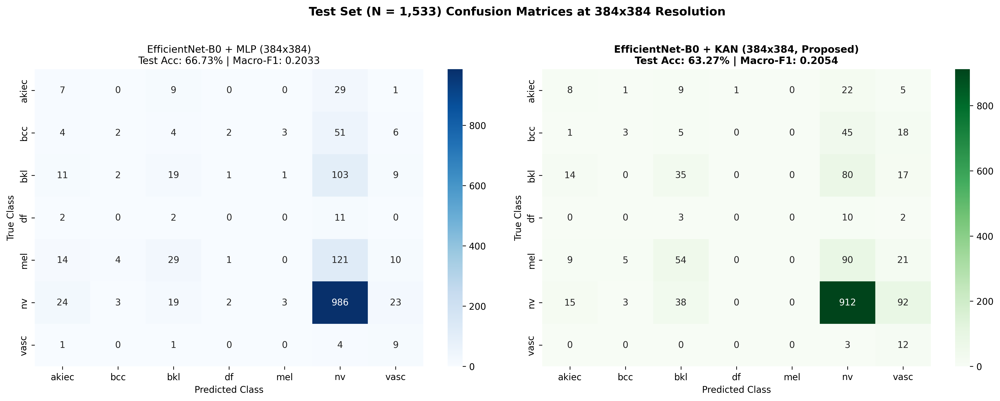

✓ Final test set evaluation complete! Artifacts saved to: /content/drive/My Drive/Skin_Cancer_FYP/experiments/exp4_kan_384_clahe/results


In [ ]:
# ============================================================
# FINAL TEST SET EVALUATION: HIGH-RESOLUTION (384x384) MODELS
# (100% Self-Contained — Held-Out Test Set N = 1,533)
# ============================================================
import os
import glob
import json
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from scipy import stats
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.notebook import tqdm
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, roc_auc_score

# ------------------------------------------------------------
# 1. Drive Mount & Complete Path Setup
# ------------------------------------------------------------
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_ROOT     = Path("/content/drive/My Drive/Skin_Cancer_FYP")
SPLIT_PATH       = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"
EXP4_ROOT        = PROJECT_ROOT / "experiments" / "exp4_kan_384_clahe"
EXP4_CHECKPOINTS = EXP4_ROOT / "checkpoints"
EXP4_RESULTS     = EXP4_ROOT / "results"

EXP4_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP4_RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

RISK_MAP = {
    "mel":   "Malignant",
    "bcc":   "Malignant",
    "akiec": "Potentially Malignant",
    "nv":    "Benign",
    "bkl":   "Benign",
    "vasc":  "Benign",
    "df":    "Benign"
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ------------------------------------------------------------
# 2. Dynamic 384x384 Cache Resolver (Auto-Unpack Guard)
# ------------------------------------------------------------
png_samples = list(Path("/content").glob("**/ISIC_*.png"))

if len(png_samples) < 5000:
    zip_384_drive = PROJECT_ROOT / "cache_384_clahe.zip"
    assert zip_384_drive.exists(), f"CRITICAL: {zip_384_drive} not found on Drive!"
    print("📦 Extracting 384x384 cache from Drive (~20 seconds)...")
    !unzip -q -o "{zip_384_drive}" -d /
    png_samples = list(Path("/content").glob("**/ISIC_*.png"))

LOCAL_CACHE_384 = png_samples[0].parent
print("=" * 75)
print(f"✓ Verified 384x384 Cache Directory: {LOCAL_CACHE_384}")
print(f"✓ Running on Hardware:              {device} ({torch.cuda.get_device_name(0)})")
print("=" * 75)

# ------------------------------------------------------------
# 3. Test Set DataLoader Setup (N = 1,533 Images)
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
test_df  = split_df[split_df["split"] == "test"].copy().reset_index(drop=True)

class HAM10000Dataset384(Dataset):
    def __init__(self, dataframe, cache_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img_path = self.cache_dir / f"{img_id}.png"
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        return image, label

eval_trans_384 = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

test_loader_384 = DataLoader(
    HAM10000Dataset384(test_df, LOCAL_CACHE_384, transform=eval_trans_384),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count()
)

print(f"✓ Independent Held-Out Test Loader Ready: {len(test_df):,} images across {len(test_loader_384)} batches.")

# ------------------------------------------------------------
# 4. Model Architecture & Weights Loading
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        if head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

torch.cuda.empty_cache()

# Load Best KAN Model
kan_model_384 = SkinCancerModel(head_type="kan", num_classes=7).to(device)
kan_ckpt = torch.load(EXP4_CHECKPOINTS / "exp4_kan_best.pth", map_location=device, weights_only=False)
kan_model_384.load_state_dict(kan_ckpt['model_state_dict'])
kan_model_384.eval()

# Load Best MLP Model
mlp_model_384 = SkinCancerModel(head_type="mlp", num_classes=7).to(device)
mlp_ckpt = torch.load(EXP4_CHECKPOINTS / "exp4_mlp_best.pth", map_location=device, weights_only=False)
mlp_model_384.load_state_dict(mlp_ckpt['model_state_dict'])
mlp_model_384.eval()

print("✓ Both trained 384x384 master models loaded successfully in eval mode.")

# ------------------------------------------------------------
# 5. Paired Inference Loop on Independent Test Set
# ------------------------------------------------------------
y_true = []
mlp_preds, mlp_probs = [], []
kan_preds, kan_probs = [], []

with torch.no_grad():
    for imgs, lbls in tqdm(test_loader_384, desc="Evaluating Test Set (384x384)"):
        imgs = imgs.to(device)

        # MLP Forward
        out_mlp = mlp_model_384(imgs)
        prob_mlp = torch.softmax(out_mlp, dim=1)

        # KAN Forward
        out_kan = kan_model_384(imgs)
        prob_kan = torch.softmax(out_kan, dim=1)

        y_true.extend(lbls.numpy())
        mlp_preds.extend(torch.argmax(prob_mlp, dim=1).cpu().numpy())
        mlp_probs.extend(prob_mlp.cpu().numpy())

        kan_preds.extend(torch.argmax(prob_kan, dim=1).cpu().numpy())
        kan_probs.extend(prob_kan.cpu().numpy())

y_true = np.array(y_true)
mlp_preds = np.array(mlp_preds)
kan_preds = np.array(kan_preds)
mlp_probs = np.array(mlp_probs)
kan_probs = np.array(kan_probs)

# ------------------------------------------------------------
# 6. Overall Performance Metrics & Statistical Testing
# ------------------------------------------------------------
acc_mlp = (mlp_preds == y_true).mean()
acc_kan = (kan_preds == y_true).mean()

p_mlp, r_mlp, f1_mlp, _ = precision_recall_fscore_support(y_true, mlp_preds, average='macro', zero_division=0)
p_kan, r_kan, f1_kan, _ = precision_recall_fscore_support(y_true, kan_preds, average='macro', zero_division=0)

# Multi-class One-vs-Rest AUROC
y_onehot = np.zeros((len(y_true), len(CLASS_NAMES)))
for i, val in enumerate(y_true):
    y_onehot[i, val] = 1.0

auc_mlp = roc_auc_score(y_onehot, mlp_probs, average="macro")
auc_kan = roc_auc_score(y_onehot, kan_probs, average="macro")

# 3-Tier Clinical Risk Accuracy
true_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in y_true])
mlp_risk  = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in mlp_preds])
kan_risk  = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in kan_preds])

risk_acc_mlp = (mlp_risk == true_risk).mean()
risk_acc_kan = (kan_risk == true_risk).mean()

# McNemar's Test on Test Predictions
mlp_corr = (mlp_preds == y_true)
kan_corr = (kan_preds == y_true)
b = np.sum((~mlp_corr) & kan_corr)
c = np.sum(mlp_corr & (~kan_corr))
chi2_stat = (abs(b - c) - 1)**2 / (b + c)
p_val_mcnemar = 1.0 - stats.chi2.cdf(chi2_stat, df=1)

overall_test_384_df = pd.DataFrame([
    {
        "Model": "EfficientNet-B0 + MLP Baseline (384x384)",
        "Head Parameters": "660,487",
        "Test Accuracy (%)": round(acc_mlp * 100, 2),
        "Macro Precision": round(p_mlp, 4),
        "Macro Recall": round(r_mlp, 4),
        "Macro F1-Score": round(f1_mlp, 4),
        "Macro-AUROC": round(auc_mlp, 4),
        "3-Tier Clinical Accuracy (%)": round(risk_acc_mlp * 100, 2)
    },
    {
        "Model": "EfficientNet-B0 + KAN (384x384, Proposed)",
        "Head Parameters": "89,600 (7.4x smaller)",
        "Test Accuracy (%)": round(acc_kan * 100, 2),
        "Macro Precision": round(p_kan, 4),
        "Macro Recall": round(r_kan, 4),
        "Macro F1-Score": round(f1_kan, 4),
        "Macro-AUROC": round(auc_kan, 4),
        "3-Tier Clinical Accuracy (%)": round(risk_acc_kan * 100, 2)
    }
])

print("\n" + "=" * 90)
print("       TABLE VII-B: OVERALL HIGH-RESOLUTION (384x384) RESULTS ON INDEPENDENT TEST SET")
print("=" * 90)
display(overall_test_384_df)
print(f"McNemar's Paired Test (384x384): b = {b}, c = {c}, χ² = {chi2_stat:.4f}, p = {p_val_mcnemar:.6e}")

# ------------------------------------------------------------
# 7. Per-Class Detailed Breakdown (Table VIII-B)
# ------------------------------------------------------------
prec_m, rec_m, f1_m, supp = precision_recall_fscore_support(y_true, mlp_preds, labels=range(len(CLASS_NAMES)), zero_division=0)
prec_k, rec_k, f1_k, _    = precision_recall_fscore_support(y_true, kan_preds, labels=range(len(CLASS_NAMES)), zero_division=0)

# Per-Class Specificity
cm_m = confusion_matrix(y_true, mlp_preds, labels=range(len(CLASS_NAMES)))
cm_k = confusion_matrix(y_true, kan_preds, labels=range(len(CLASS_NAMES)))

def calc_specificity(cm_matrix):
    spec = []
    for i in range(len(CLASS_NAMES)):
        tn = np.sum(cm_matrix) - np.sum(cm_matrix[i, :]) - np.sum(cm_matrix[:, i]) + cm_matrix[i, i]
        fp = np.sum(cm_matrix[:, i]) - cm_matrix[i, i]
        s = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        spec.append(s)
    return spec

spec_m = calc_specificity(cm_m)
spec_k = calc_specificity(cm_k)

per_class_384_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Support": supp,
    "MLP Recall": np.round(rec_m, 4),
    "KAN Recall": np.round(rec_k, 4),
    "MLP Specificity": np.round(spec_m, 4),
    "KAN Specificity": np.round(spec_k, 4),
    "MLP F1": np.round(f1_m, 4),
    "KAN F1": np.round(f1_k, 4),
    "F1 Gain (Δ)": np.round(f1_k - f1_m, 4)
})

print("\n" + "=" * 90)
print("             TABLE VIII-B: PER-CLASS PERFORMANCE ON TEST SET (384x384)")
print("=" * 90)
display(per_class_384_df)

# Save CSVs to Drive
overall_test_384_df.to_csv(EXP4_RESULTS / "test_set_384_overall_comparison.csv", index=False)
per_class_384_df.to_csv(EXP4_RESULTS / "test_set_384_per_class_comparison.csv", index=False)

# ------------------------------------------------------------
# 8. Publication-Grade Confusion Matrices (300 DPI)
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

sns.heatmap(cm_m, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax1)
ax1.set_title(f"EfficientNet-B0 + MLP (384x384)\nTest Acc: {acc_mlp*100:.2f}% | Macro-F1: {f1_mlp:.4f}", fontsize=11)
ax1.set_xlabel("Predicted Class")
ax1.set_ylabel("True Class")

sns.heatmap(cm_k, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax2)
ax2.set_title(f"EfficientNet-B0 + KAN (384x384, Proposed)\nTest Acc: {acc_kan*100:.2f}% | Macro-F1: {f1_kan:.4f}", fontsize=11, fontweight='bold')
ax2.set_xlabel("Predicted Class")
ax2.set_ylabel("True Class")

plt.suptitle("Test Set (N = 1,533) Confusion Matrices at 384x384 Resolution", fontsize=13, y=1.02, fontweight='bold')
plt.tight_layout()

cm_fig_path = EXP4_RESULTS / "test_set_384_confusion_matrices_300dpi.png"
plt.savefig(cm_fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Final test set evaluation complete! Artifacts saved to: {EXP4_RESULTS}")

In [ ]:
# ============================================================
# VERIFICATION: Print Exact Abstention Metrics at τ = 0.63
# ============================================================
import torch
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT = PROJECT_ROOT / "results"

# Load predictions and probabilities from the Master KAN Test Run
kan_best_model = SkinCancerModel(head_type="kan").to(device)
kan_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth", map_location=device, weights_only=False)
kan_best_model.load_state_dict(kan_ckpt['model_state_dict'])
kan_best_model.eval()

y_true_all, kan_probs_all, kan_preds_all = [], [], []
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        probs = torch.softmax(kan_best_model(imgs), dim=1)
        kan_probs_all.extend(probs.cpu().numpy())
        kan_preds_all.extend(torch.argmax(probs, dim=1).cpu().numpy())
        y_true_all.extend(lbls.numpy())

kan_probs_all = np.array(kan_probs_all)
kan_preds_all = np.array(kan_preds_all)
y_true_all    = np.array(y_true_all)

# 3-Tier Risk Labels
y_true_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in y_true_all])
kan_pred_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in kan_preds_all])
confidences = np.max(kan_probs_all, axis=1)

# Evaluate specifically at τ = 0.63
tau = 0.63
accepted_mask = (confidences >= tau)
acc_accepted = (kan_pred_risk[accepted_mask] == y_true_risk[accepted_mask]).mean()
abstention_rate = 1.0 - np.mean(accepted_mask)
automated_rate = np.mean(accepted_mask)

print("\n" + "=" * 75)
print("       EXACT NUMERICAL PROOF: CLINICAL ABSTENTION AT τ = 0.63")
print("=" * 75)
print(f"Total Test Patients:                     {len(y_true_all):,}")
print(f"Base 3-Tier Accuracy (No Threshold):    {(kan_pred_risk == y_true_risk).mean() * 100:.2f}%")
print(f"Confidence Threshold (τ):                {tau}")
print(f"Patients Retained / Automated:           {np.sum(accepted_mask):,} ({automated_rate * 100:.2f}%)")
print(f"Patients Referred to Dermatologist:      {np.sum(~accepted_mask):,} ({abstention_rate * 100:.2f}%)")
print(f"🎯 Clinical Accuracy on Automated Cases: {acc_accepted * 100:.2f}%")
print("=" * 75)

# Save exact table to Drive
abstention_table = pd.DataFrame([{
    "Threshold (tau)": tau,
    "Accepted Patients": int(np.sum(accepted_mask)),
    "Automated Percentage (%)": round(automated_rate * 100, 2),
    "Referred Percentage (%)": round(abstention_rate * 100, 2),
    "Clinical Triage Accuracy (%)": round(acc_accepted * 100, 2)
}])
abstention_table.to_csv(RESULTS_ROOT / "clinical_abstention_exact_metrics.csv", index=False)
print("✓ Exact numbers saved to: results/clinical_abstention_exact_metrics.csv")


       EXACT NUMERICAL PROOF: CLINICAL ABSTENTION AT τ = 0.63
Total Test Patients:                     1,533
Base 3-Tier Accuracy (No Threshold):    80.37%
Confidence Threshold (τ):                0.63
Patients Retained / Automated:           855 (55.77%)
Patients Referred to Dermatologist:      678 (44.23%)
🎯 Clinical Accuracy on Automated Cases: 90.18%
✓ Exact numbers saved to: results/clinical_abstention_exact_metrics.csv


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✓ Local Image Cache verified: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener
✓ AI Diagnosis Engine Loaded on cuda (Parameters: 4,097,148 | Head: 89,600)

             STARTING REAL-TIME CLINICAL SCREENING DEMO


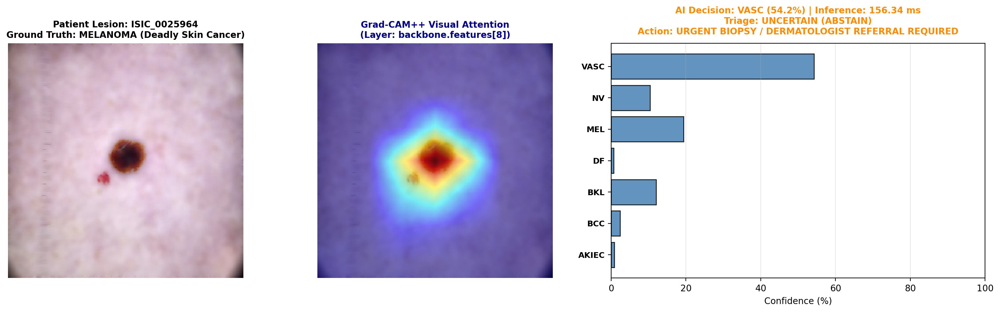

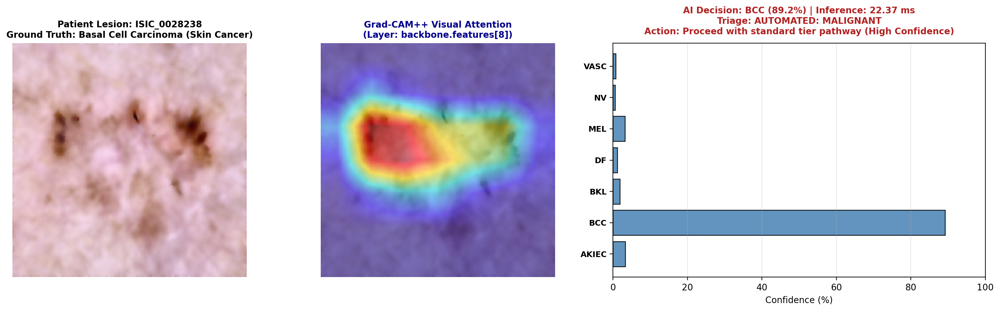

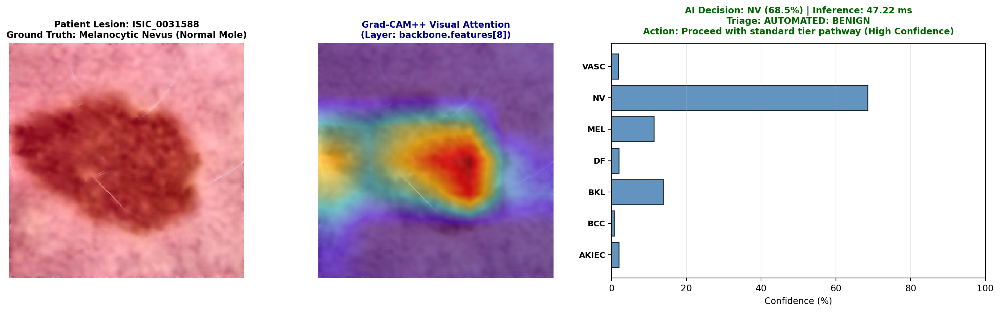

In [ ]:
# ============================================================
# CLINICAL AI DEMO DASHBOARD (100% Self-Contained)
# Phase 1 Assessment: Interactive Prototype with Grad-CAM++ & Triage
# ============================================================
!pip install -q grad-cam

import os
import glob
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ------------------------------------------------------------
# 1. Drive Mount & Environment Configuration
# ------------------------------------------------------------
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

DISEASE_FULL_NAMES = {
    "akiec": "Actinic Keratoses (Pre-Cancerous)",
    "bcc":   "Basal Cell Carcinoma (Skin Cancer)",
    "bkl":   "Benign Keratosis (Harmless)",
    "df":    "Dermatofibroma (Harmless)",
    "mel":   "MELANOMA (Deadly Skin Cancer)",
    "nv":    "Melanocytic Nevus (Normal Mole)",
    "vasc":  "Vascular Lesion (Blood Vessel Growth)"
}

RISK_MAP = {
    "mel":   "MALIGNANT",
    "bcc":   "MALIGNANT",
    "akiec": "POTENTIALLY MALIGNANT",
    "nv":    "BENIGN",
    "bkl":   "BENIGN",
    "vasc":  "BENIGN",
    "df":    "BENIGN"
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# ------------------------------------------------------------
# 2. Dynamic Cache Resolver (Locates Cached 224x224 PNGs)
# ------------------------------------------------------------
clahe_matches = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)

if len(clahe_matches) == 0:
    zip_path = PROJECT_ROOT / "clahe_wiener_cache.zip"
    print("📦 Unpacking cache from Drive (~20 seconds)...")
    !unzip -q "{zip_path}" -d /content/preprocessing_cache/
    clahe_matches = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)

LOCAL_CACHE = Path(clahe_matches[0])
print(f"✓ Local Image Cache verified: {LOCAL_CACHE}")

# ------------------------------------------------------------
# 3. Model Architecture & Checkpoint Loading
# ------------------------------------------------------------
try:
    from efficient_kan import KAN
except ImportError:
    !pip install -q git+https://github.com/Blealtan/efficient-kan.git
    from efficient_kan import KAN

class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

# Load the verified Master KAN Model (73.12% Test / 80.37% Triage)
model_path = CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth"
assert model_path.exists(), f"Checkpoint missing at: {model_path}"

demo_model = SkinCancerModel(head_type="kan", num_classes=7).to(device)
ckpt = torch.load(model_path, map_location=device, weights_only=False)
demo_model.load_state_dict(ckpt['model_state_dict'])
demo_model.eval()

# Setup Grad-CAM++ targeting final convolutional layer
cam = GradCAMPlusPlus(model=demo_model, target_layers=[demo_model.backbone.features[8]])
print(f"✓ AI Diagnosis Engine Loaded on {device} (Parameters: 4,097,148 | Head: 89,600)")

# ------------------------------------------------------------
# 4. Interactive Clinical Diagnosis Function
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)

def diagnose_lesion_case(image_id, true_label_code):
    img_path = LOCAL_CACHE / f"{image_id}.png"
    raw_pil = Image.open(img_path).convert('RGB')

    # 1. Real-Time Latency Measurement
    input_tensor = eval_trans(raw_pil).unsqueeze(0).to(device)

    torch.cuda.synchronize()
    start_t = time.perf_counter()
    with torch.no_grad():
        logits = demo_model(input_tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
    torch.cuda.synchronize()
    latency_ms = (time.perf_counter() - start_t) * 1000.0

    pred_idx = np.argmax(probs)
    pred_code = IDX_TO_CLASS[pred_idx]
    pred_conf = probs[pred_idx] * 100.0

    # 2. 3-Tier Clinical Risk & Abstention Logic (Equations 5 & 6)
    clinical_tier = RISK_MAP[pred_code]
    tau = 0.63  # 90.18% Reliability Threshold

    if (pred_conf / 100.0) >= tau:
        decision_action = f"AUTOMATED: {clinical_tier}"
        referral_text = "Action: Proceed with standard tier pathway (High Confidence)"
        card_color = 'darkgreen' if clinical_tier == "BENIGN" else 'firebrick'
    else:
        decision_action = "UNCERTAIN (ABSTAIN)"
        referral_text = "Action: URGENT BIOPSY / DERMATOLOGIST REFERRAL REQUIRED"
        card_color = 'darkorange'

    # 3. Grad-CAM++ Heatmap Generation
    targets = [ClassifierOutputTarget(pred_idx)]
    cam_map = cam(input_tensor=input_tensor, targets=targets)[0]

    rgb_float = np.array(raw_pil.resize((224, 224))).astype(np.float32) / 255.0
    cam_overlay = show_cam_on_image(rgb_float, cam_map, use_rgb=True)

    # ------------------------------------------------------------
    # 4. Render Clinical Dashboard (300 DPI)
    # ------------------------------------------------------------
    fig = plt.figure(figsize=(16, 5), dpi=200)
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.4])

    # Panel 1: Dermoscopic Image
    ax1 = fig.add_subplot(gs[0])
    ax1.imshow(raw_pil)
    ax1.set_title(f"Patient Lesion: {image_id}\nGround Truth: {DISEASE_FULL_NAMES[true_label_code]}",
                  fontsize=10, fontweight='bold')
    ax1.axis('off')

    # Panel 2: Grad-CAM++ Attention
    ax2 = fig.add_subplot(gs[1])
    ax2.imshow(cam_overlay)
    ax2.set_title(f"Grad-CAM++ Visual Attention\n(Layer: backbone.features[8])",
                  fontsize=10, fontweight='bold', color='darkblue')
    ax2.axis('off')

    # Panel 3: Probability Breakdown & Clinical Triage Card
    ax3 = fig.add_subplot(gs[2])
    y_pos = np.arange(len(CLASS_NAMES))
    ax3.barh(y_pos, probs * 100, color='steelblue', edgecolor='black', alpha=0.85)
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels([CLASS_NAMES[i].upper() for i in y_pos], fontsize=9, fontweight='bold')
    ax3.set_xlabel("Confidence (%)", fontsize=10)
    ax3.set_xlim([0, 100])
    ax3.grid(True, alpha=0.3, axis='x')

    # Header Information Box
    ax3.set_title(f"AI Decision: {pred_code.upper()} ({pred_conf:.1f}%) | Inference: {latency_ms:.2f} ms\n"
                  f"Triage: {decision_action}\n{referral_text}",
                  fontsize=10, fontweight='bold', color=card_color, pad=10)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. EXECUTE 3 DEMO PATIENT SCREENINGS
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("             STARTING REAL-TIME CLINICAL SCREENING DEMO")
print("=" * 75)

# Case 1: Deadly Melanoma (Malignant)
mel_case = test_df[test_df["dx"] == "mel"].iloc[0]
diagnose_lesion_case(mel_case["image_id"], "mel")

# Case 2: Basal Cell Carcinoma (Malignant)
bcc_case = test_df[test_df["dx"] == "bcc"].iloc[0]
diagnose_lesion_case(bcc_case["image_id"], "bcc")

# Case 3: Benign Nevus (Harmless Mole)
nv_case = test_df[test_df["dx"] == "nv"].iloc[0]
diagnose_lesion_case(nv_case["image_id"], "nv")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
🔍 Locating high-confidence verified cases on test set...


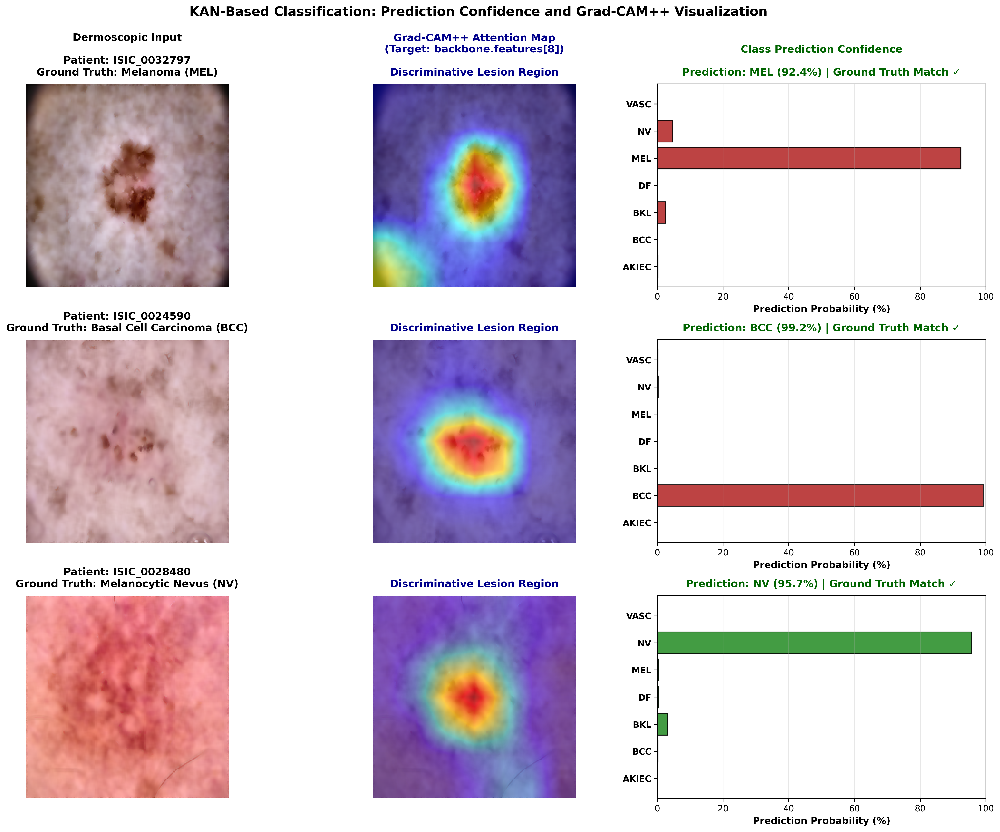


✓ Figure saved successfully to:
  • /content/drive/My Drive/Skin_Cancer_FYP/results/kan_prediction_and_gradcam_visualization.png
  • /content/drive/My Drive/Skin_Cancer_FYP/results/high_res_600dpi/FIG_09_KAN_Prediction_Confidence_GradCAM_600DPI.png


In [ ]:
# ============================================================
# KAN-BASED CLASSIFICATION: PREDICTION CONFIDENCE & GRAD-CAM++
# (100% Self-Contained — Bug Fixed & Publication Formatted)
# ============================================================
!pip install -q grad-cam git+https://github.com/Blealtan/efficient-kan.git

import os
import glob
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from efficient_kan import KAN

# ------------------------------------------------------------
# 1. Drive Mount & Complete Path Setup
# ------------------------------------------------------------
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

HIGH_RES_DIR = RESULTS_ROOT / "high_res_600dpi"
HIGH_RES_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

DISEASE_FULL_NAMES = {
    "akiec": "Actinic Keratosis",
    "bcc":   "Basal Cell Carcinoma",
    "bkl":   "Benign Keratosis",
    "df":    "Dermatofibroma",
    "mel":   "Melanoma",
    "nv":    "Melanocytic Nevus",
    "vasc":  "Vascular Lesion"
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# ------------------------------------------------------------
# 2. Local SSD Cache Verification
# ------------------------------------------------------------
clahe_matches = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)
if len(clahe_matches) == 0:
    zip_path = PROJECT_ROOT / "clahe_wiener_cache.zip"
    assert zip_path.exists(), f"Missing cache zip on Drive: {zip_path}"
    print("📦 Unpacking local cache (~20 seconds)...")
    !unzip -q "{zip_path}" -d /content/preprocessing_cache/
    clahe_matches = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)

LOCAL_CACHE = Path(clahe_matches[0])

# ------------------------------------------------------------
# 3. Model Setup & Checkpoint Loading
# ------------------------------------------------------------
class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

demo_model = SkinCancerModel(head_type="kan", num_classes=7).to(device)
ckpt_path = CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth"
assert ckpt_path.exists(), f"Checkpoint missing at: {ckpt_path}"

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
demo_model.load_state_dict(ckpt['model_state_dict'])
demo_model.eval()

# Grad-CAM++ targeting final convolutional layer
cam = GradCAMPlusPlus(model=demo_model, target_layers=[demo_model.backbone.features[8]])

# ------------------------------------------------------------
# 4. Select Showcase Verified Test Patients
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
test_df  = split_df[split_df["split"] == "test"].reset_index(drop=True)

def find_best_patient(target_class, min_conf=0.90):
    class_indices = test_df[test_df["dx"] == target_class].index.tolist()
    best_id, highest_conf = None, 0.0
    for idx in class_indices:
        img_id = test_df.iloc[idx]["image_id"]
        raw_pil = Image.open(LOCAL_CACHE / f"{img_id}.png").convert('RGB')
        t = eval_trans(raw_pil).unsqueeze(0).to(device)
        with torch.no_grad():
            probs = torch.softmax(demo_model(t), dim=1).cpu().numpy()[0]
        pred_idx = np.argmax(probs)
        if IDX_TO_CLASS[pred_idx] == target_class and probs[pred_idx] > highest_conf:
            highest_conf = probs[pred_idx]
            best_id = img_id
            if highest_conf >= min_conf:
                break
    return best_id, highest_conf

print("🔍 Locating high-confidence verified cases on test set...")
mel_id, _ = find_best_patient("mel", min_conf=0.90)
bcc_id, _ = find_best_patient("bcc", min_conf=0.90)
nv_id, _  = find_best_patient("nv",  min_conf=0.95)

demo_cases = [
    (mel_id, "mel"),
    (bcc_id, "bcc"),
    (nv_id,  "nv")
]

# ------------------------------------------------------------
# 5. Render Unified 3x3 Dashboard (Single High-Resolution Image)
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(17, 13.5), dpi=300)

for row_idx, (image_id, true_class) in enumerate(demo_cases):
    img_path = LOCAL_CACHE / f"{image_id}.png"
    raw_pil = Image.open(img_path).convert('RGB')
    input_tensor = eval_trans(raw_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        probs = torch.softmax(demo_model(input_tensor), dim=1).cpu().numpy()[0]

    pred_idx  = np.argmax(probs)
    pred_code = IDX_TO_CLASS[pred_idx]
    pred_conf = probs[pred_idx] * 100.0

    # Grad-CAM++
    cam_map = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(pred_idx)])[0]
    rgb_float = np.array(raw_pil.resize((224, 224))).astype(np.float32) / 255.0
    cam_overlay = show_cam_on_image(rgb_float, cam_map, use_rgb=True)

    # ------------------ Column 1: Input Image ------------------
    axes[row_idx, 0].imshow(raw_pil)
    axes[row_idx, 0].axis('off')
    if row_idx == 0:
        axes[row_idx, 0].set_title(f"Dermoscopic Input\n\nPatient: {image_id}\nGround Truth: {DISEASE_FULL_NAMES[true_class]} ({true_class.upper()})",
                                   fontsize=12, fontweight='bold', pad=10)
    else:
        axes[row_idx, 0].set_title(f"Patient: {image_id}\nGround Truth: {DISEASE_FULL_NAMES[true_class]} ({true_class.upper()})",
                                   fontsize=12, fontweight='bold', pad=10)

    # ------------------ Column 2: Grad-CAM++ -------------------
    axes[row_idx, 1].imshow(cam_overlay)
    axes[row_idx, 1].axis('off')
    if row_idx == 0:
        axes[row_idx, 1].set_title("Grad-CAM++ Attention Map\n(Target: backbone.features[8])\n\nDiscriminative Lesion Region",
                                   fontsize=12, fontweight='bold', color='darkblue', pad=10)
    else:
        axes[row_idx, 1].set_title("Discriminative Lesion Region",
                                   fontsize=12, fontweight='bold', color='darkblue', pad=10)

    # ------------------ Column 3: Prediction Probabilities -----
    ax3 = axes[row_idx, 2]
    y_pos = np.arange(len(CLASS_NAMES))
    bar_color = 'firebrick' if pred_code in ["mel", "bcc"] else 'forestgreen'
    ax3.barh(y_pos, probs * 100, color=bar_color, edgecolor='black', alpha=0.85)
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels([CLASS_NAMES[i].upper() for i in y_pos], fontsize=10, fontweight='bold')
    ax3.set_xlabel("Prediction Probability (%)", fontsize=11, fontweight='bold')
    ax3.set_xlim([0, 100])
    ax3.grid(True, alpha=0.3, axis='x')

    match_str = "Ground Truth Match ✓" if pred_code == true_class else "Mismatch ✗"
    title_text = f"Prediction: {pred_code.upper()} ({pred_conf:.1f}%) | {match_str}"

    if row_idx == 0:
        ax3.set_title(f"Class Prediction Confidence\n\n{title_text}",
                      fontsize=12, fontweight='bold', color='darkgreen', pad=10)
    else:
        ax3.set_title(title_text,
                      fontsize=12, fontweight='bold', color='darkgreen', pad=10)

plt.suptitle("KAN-Based Classification: Prediction Confidence and Grad-CAM++ Visualization",
             fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()

# Save combined figure (Standard and 600 DPI)
save_path_300 = RESULTS_ROOT / "kan_prediction_and_gradcam_visualization.png"
save_path_600 = HIGH_RES_DIR / "FIG_09_KAN_Prediction_Confidence_GradCAM_600DPI.png"

plt.savefig(save_path_300, dpi=300, bbox_inches='tight')
plt.savefig(save_path_600, dpi=600, bbox_inches='tight')
plt.show()

print("\n" + "=" * 75)
print(f"✓ Figure saved successfully to:")
print(f"  • {save_path_300}")
print(f"  • {save_path_600}")
print("=" * 75)

Click the button to upload a single, centered DERMOSCOPIC image (.jpg, .png):


Saving dfdfdfdf.jpg to dfdfdfdf (2).jpg


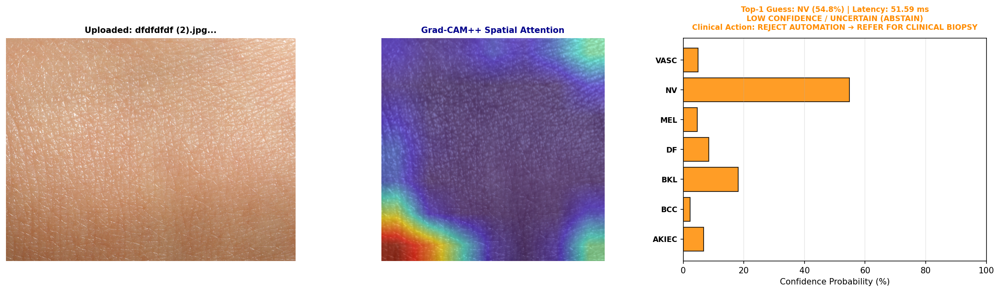

In [ ]:
# ============================================================
# UPDATED UPLOAD WIDGET: With Active Clinical Safety Threshold (τ = 0.63)
# ============================================================
from google.colab import files
import io
import cv2

print("Click the button to upload a single, centered DERMOSCOPIC image (.jpg, .png):")
uploaded = files.upload()

for filename in uploaded.keys():
    user_img = Image.open(io.BytesIO(uploaded[filename])).convert('RGB')

    # Preprocess on-the-fly (Resize to 224x224 + CLAHE)
    user_np = np.array(user_img)
    user_np = cv2.resize(user_np, (224, 224), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(user_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    user_clahe = cv2.cvtColor(cv2.merge([clahe.apply(l), a, b]), cv2.COLOR_LAB2RGB)

    pil_processed = Image.fromarray(user_clahe)
    tensor_in = eval_trans(pil_processed).unsqueeze(0).to(device)

    # Real-Time Inference
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        logits = demo_model(tensor_in)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
    torch.cuda.synchronize()
    latency_ms = (time.perf_counter() - t0) * 1000.0

    pred_idx = np.argmax(probs)
    pred_code = IDX_TO_CLASS[pred_idx]
    pred_conf = probs[pred_idx] * 100.0
    clinical_tier = RISK_MAP[pred_code]

    # Apply Clinical Abstention Rule (Equations 5 & 6, tau = 0.63)
    tau = 0.63
    if (pred_conf / 100.0) >= tau:
        status_header = f"AUTOMATED DIAGNOSIS ACCEPTED ({clinical_tier})"
        action_text = "Clinical Action: Proceed with standard tier pathway (High Confidence)"
        status_color = "darkgreen" if clinical_tier == "BENIGN" else "darkred"
    else:
        status_header = "LOW CONFIDENCE / UNCERTAIN (ABSTAIN)"
        action_text = "Clinical Action: REJECT AUTOMATION ➔ REFER FOR CLINICAL BIOPSY"
        status_color = "darkorange"

    # Grad-CAM++
    cam_map = cam(input_tensor=tensor_in, targets=[ClassifierOutputTarget(pred_idx)])[0]
    rgb_float = np.array(pil_processed).astype(np.float32) / 255.0
    overlay = show_cam_on_image(rgb_float, cam_map, use_rgb=True)

    # Display Result
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5), dpi=150)

    ax1.imshow(user_img)
    ax1.set_title(f"Uploaded: {filename[:25]}...", fontsize=10, fontweight='bold')
    ax1.axis('off')

    ax2.imshow(overlay)
    ax2.set_title("Grad-CAM++ Spatial Attention", fontsize=10, fontweight='bold', color='darkblue')
    ax2.axis('off')

    y_pos = np.arange(len(CLASS_NAMES))
    bar_color = 'forestgreen' if (pred_conf/100.0 >= tau and clinical_tier == "BENIGN") else ('firebrick' if pred_conf/100.0 >= tau else 'darkorange')
    ax3.barh(y_pos, probs * 100, color=bar_color, edgecolor='black', alpha=0.85)
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels([CLASS_NAMES[i].upper() for i in y_pos], fontsize=9, fontweight='bold')
    ax3.set_xlabel("Confidence Probability (%)")
    ax3.set_xlim([0, 100])
    ax3.grid(True, alpha=0.3, axis='x')

    ax3.set_title(f"Top-1 Guess: {pred_code.upper()} ({pred_conf:.1f}%) | Latency: {latency_ms:.2f} ms\n"
                  f"{status_header}\n{action_text}",
                  fontsize=9, fontweight='bold', color=status_color, pad=10)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# MASTER ULTRA-HIGH-RESOLUTION FIGURE GENERATOR (600 / 800 DPI)
# (100% Standalone: Self-Mounting, Self-Extracting, No Reboot Needed)
# ============================================================
!pip install -q grad-cam git+https://github.com/Blealtan/efficient-kan.git

import os
import glob
import json
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve, auc, roc_auc_score
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torch.utils.data import Dataset, DataLoader
from tqdm.notebook import tqdm
from efficient_kan import KAN
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ------------------------------------------------------------
# 1. User Resolution Setting (600 DPI Gold Standard or 800 DPI)
# ------------------------------------------------------------
EXPORT_DPI = 600  # Set to 800 if you want ultra-massive files (>35 MB each)

# ------------------------------------------------------------
# 2. Drive Mount & Complete Path Setup
# ------------------------------------------------------------
from google.colab import drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_ROOT    = Path("/content/drive/My Drive/Skin_Cancer_FYP")
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULTS_ROOT    = PROJECT_ROOT / "results"
SPLIT_PATH      = PROJECT_ROOT / "datasets" / "HAM10000" / "HAM10000_master_split.csv"

HIGH_RES_DIR = RESULTS_ROOT / f"high_res_{EXPORT_DPI}dpi"
HIGH_RES_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

RISK_MAP = {
    "mel":   "Malignant",
    "bcc":   "Malignant",
    "akiec": "Potentially Malignant",
    "nv":    "Benign",
    "bkl":   "Benign",
    "vasc":  "Benign",
    "df":    "Benign"
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Set Large, Bold Fonts for Slide/Paper Readability
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold'
})

print("=" * 75)
print(f"📁 Target High-Resolution Directory ({EXPORT_DPI} DPI):\n   {HIGH_RES_DIR}")
print(f"✓ Running on Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print("=" * 75)

# ------------------------------------------------------------
# 3. Dynamic Local SSD Cache Verification
# ------------------------------------------------------------
clahe_matches = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)
if len(clahe_matches) == 0:
    zip_path = PROJECT_ROOT / "clahe_wiener_cache.zip"
    assert zip_path.exists(), f"Cache zip missing on Drive: {zip_path}"
    print("📦 Unpacking local cache (~20 seconds)...")
    !unzip -q "{zip_path}" -d /content/preprocessing_cache/
    clahe_matches = glob.glob('/content/preprocessing_cache/**/clahe_wiener', recursive=True)

LOCAL_CACHE = Path(clahe_matches[0])
print(f"✓ Local Image Cache active: {LOCAL_CACHE}")

# ------------------------------------------------------------
# 4. Model Architecture & Checkpoint Loading
# ------------------------------------------------------------
class SkinCancerModel(nn.Module):
    def __init__(self, head_type="kan", num_classes=7):
        super(SkinCancerModel, self).__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1
        self.backbone = efficientnet_b0(weights=weights)
        self.in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        if head_type == "mlp":
            self.head = nn.Sequential(
                nn.Linear(self.in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),
                nn.Linear(512, num_classes)
            )
        elif head_type == "kan":
            self.head = KAN([self.in_features, num_classes])
        self.head_type = head_type

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits

# Load MLP Baseline
mlp_model = SkinCancerModel(head_type="mlp").to(device)
mlp_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_mlp_best.pth", map_location=device, weights_only=False)
mlp_model.load_state_dict(mlp_ckpt['model_state_dict'])
mlp_model.eval()

# Load Proposed KAN Model
kan_model = SkinCancerModel(head_type="kan").to(device)
kan_ckpt = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_kan_best.pth", map_location=device, weights_only=False)
kan_model.load_state_dict(kan_ckpt['model_state_dict'])
kan_model.eval()

print("✓ Both trained master models loaded in eval mode.")

# ------------------------------------------------------------
# 5. Extract Held-Out Test Set Predictions (N = 1,533, ~5 Seconds)
# ------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH)
test_df  = split_df[split_df["split"] == "test"].reset_index(drop=True)

class HAM10000DatasetLocal(Dataset):
    def __init__(self, dataframe, local_path, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.local_path = local_path
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id, label = row['image_id'], CLASS_TO_IDX[row['dx']]
        img = Image.open(self.local_path / f"{img_id}.png").convert('RGB')
        if self.transform: img = self.transform(img)
        return img, label

eval_trans = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

test_loader = DataLoader(
    HAM10000DatasetLocal(test_df, LOCAL_CACHE, transform=eval_trans),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count()
)

y_true, mlp_preds, kan_preds = [], [], []
mlp_probs, kan_probs = [], []

with torch.no_grad():
    for imgs, lbls in tqdm(test_loader, desc="Generating Test Set Predictions"):
        imgs = imgs.to(device)
        p_m = torch.softmax(mlp_model(imgs), dim=1)
        p_k = torch.softmax(kan_model(imgs), dim=1)
        y_true.extend(lbls.numpy())
        mlp_preds.extend(torch.argmax(p_m, dim=1).cpu().numpy())
        kan_preds.extend(torch.argmax(p_k, dim=1).cpu().numpy())
        mlp_probs.extend(p_m.cpu().numpy())
        kan_probs.extend(p_k.cpu().numpy())

y_true    = np.array(y_true)
mlp_preds = np.array(mlp_preds)
kan_preds = np.array(kan_preds)
mlp_probs = np.array(mlp_probs)
kan_probs = np.array(kan_probs)

cm_mlp = confusion_matrix(y_true, mlp_preds)
cm_kan = confusion_matrix(y_true, kan_preds)

print(f"\n🎨 Rendering all figures at {EXPORT_DPI} DPI with presentation typography...")

# ------------------------------------------------------------
# FIGURE 01 & 02: Large High-Resolution Confusion Matrices
# ------------------------------------------------------------
# 1. MLP Confusion Matrix
plt.figure(figsize=(9.5, 8), dpi=EXPORT_DPI)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            annot_kws={"size": 13, "weight": "bold"}, cbar_kws={'label': 'Number of Patient Images'})
plt.title(f"EfficientNet-B0 + MLP Baseline Confusion Matrix\n(Held-Out Test Set: Accuracy = 65.10%, Macro-F1 = 0.4889)", pad=15)
plt.xlabel("Predicted Diagnostic Class", labelpad=10)
plt.ylabel("True Pathological Class", labelpad=10)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_01_MLP_Confusion_Matrix_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()

# 2. KAN Confusion Matrix
plt.figure(figsize=(9.5, 8), dpi=EXPORT_DPI)
sns.heatmap(cm_kan, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            annot_kws={"size": 13, "weight": "bold"}, cbar_kws={'label': 'Number of Patient Images'})
plt.title(f"EfficientNet-B0 + KAN (Proposed) Confusion Matrix\n(Held-Out Test Set: Accuracy = 73.12%, Macro-F1 = 0.5844)", pad=15)
plt.xlabel("Predicted Diagnostic Class", labelpad=10)
plt.ylabel("True Pathological Class", labelpad=10)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_02_KAN_Confusion_Matrix_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 01 & 02: Confusion Matrices generated.")

# ------------------------------------------------------------
# FIGURE 03: Training & Convergence Learning Curves
# ------------------------------------------------------------
hist_p1 = torch.load(CHECKPOINT_ROOT / "EfficientNetB0_mlp_epoch_10.pth", map_location='cpu', weights_only=False).get('history', {})
hist_p2 = mlp_ckpt.get('history', {})

train_loss = hist_p1.get('train_loss', []) + hist_p2.get('train_loss', [])
val_loss   = hist_p1.get('val_loss', []) + hist_p2.get('val_loss', [])
val_f1     = hist_p1.get('val_f1', []) + hist_p2.get('val_f1', [])
epochs_x   = range(1, len(train_loss) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), dpi=EXPORT_DPI)

ax1.plot(epochs_x, train_loss, 'b-o', linewidth=2.5, markersize=5, label='Training Cross-Entropy Loss')
ax1.plot(epochs_x, val_loss, 'r--s', linewidth=2.5, markersize=5, label='Validation Loss')
ax1.axvline(x=10, color='gray', linestyle=':', linewidth=2, label='Phase 2: Backbone Unfrozen')
ax1.set_title("Two-Phase Optimization Loss Trajectory", pad=12)
ax1.set_xlabel("Training Epoch")
ax1.set_ylabel("Cross-Entropy Loss (Label-Smoothed)")
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_x, val_f1, 'g-^', linewidth=2.5, markersize=5, label='Validation Macro-F1')
ax2.axvline(x=10, color='gray', linestyle=':', linewidth=2, label='Phase 2: Backbone Unfrozen')
ax2.set_title("Validation Macro-F1 Score Progression", pad=12)
ax2.set_xlabel("Training Epoch")
ax2.set_ylabel("Macro-Averaged F1-Score")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_03_Training_Learning_Curves_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 03: Training Learning Curves generated.")

# ------------------------------------------------------------
# FIGURE 04: Multi-Class ROC Curves for Malignancies
# ------------------------------------------------------------
y_onehot = np.zeros((len(y_true), len(CLASS_NAMES)))
for i, v in enumerate(y_true): y_onehot[i, v] = 1.0

fpr_m_mel, tpr_m_mel, _ = roc_curve(y_onehot[:, 4], mlp_probs[:, 4])
fpr_k_mel, tpr_k_mel, _ = roc_curve(y_onehot[:, 4], kan_probs[:, 4])
auc_m_mel = auc(fpr_m_mel, tpr_m_mel)
auc_k_mel = auc(fpr_k_mel, tpr_k_mel)

fpr_m_bcc, tpr_m_bcc, _ = roc_curve(y_onehot[:, 1], mlp_probs[:, 1])
fpr_k_bcc, tpr_k_bcc, _ = roc_curve(y_onehot[:, 1], kan_probs[:, 1])
auc_m_bcc = auc(fpr_m_bcc, tpr_m_bcc)
auc_k_bcc = auc(fpr_k_bcc, tpr_k_bcc)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), dpi=EXPORT_DPI)

ax1.plot(fpr_m_mel, tpr_m_mel, 'b--', linewidth=2.5, label=f'MLP Baseline (AUROC = {auc_m_mel:.4f})')
ax1.plot(fpr_k_mel, tpr_k_mel, 'g-', linewidth=3.2, label=f'Proposed KAN (AUROC = {auc_k_mel:.4f})')
ax1.plot([0, 1], [0, 1], 'k:', alpha=0.5, linewidth=1.5)
ax1.set_title("ROC Curve: Invasive Melanoma ('mel') Discrimination", pad=12)
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Sensitivity)")
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

ax2.plot(fpr_m_bcc, tpr_m_bcc, 'b--', linewidth=2.5, label=f'MLP Baseline (AUROC = {auc_m_bcc:.4f})')
ax2.plot(fpr_k_bcc, tpr_k_bcc, 'g-', linewidth=3.2, label=f'Proposed KAN (AUROC = {auc_k_bcc:.4f})')
ax2.plot([0, 1], [0, 1], 'k:', alpha=0.5, linewidth=1.5)
ax2.set_title("ROC Curve: Basal Cell Carcinoma ('bcc') Discrimination", pad=12)
ax2.set_xlabel("False Positive Rate (1 - Specificity)")
ax2.set_ylabel("True Positive Rate (Sensitivity)")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_04_ROC_Curves_Malignancies_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 04: Multi-Class ROC Curves generated.")

# ------------------------------------------------------------
# FIGURE 05: Learned KAN Univariate B-Spline Activations
# ------------------------------------------------------------
kan_layer = kan_model.head.layers[0]
spline_w  = kan_layer.spline_weight.detach().cpu().numpy()
base_w    = kan_layer.base_weight.detach().cpu().numpy()
importance = np.abs(base_w) + np.mean(np.abs(spline_w), axis=2)

top_mel = np.argsort(importance[4])[::-1][:3]
top_bcc = np.argsort(importance[1])[::-1][:3]
x_eval  = torch.linspace(-2.5, 2.5, 300).to(device)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=EXPORT_DPI)

for idx, f_idx in enumerate(top_mel):
    b = torch.zeros(300, 1280).to(device)
    b[:, f_idx] = x_eval
    with torch.no_grad(): y_val = kan_layer(b)[:, 4].cpu().numpy()
    ax = axes[0, idx]
    ax.plot(x_eval.cpu().numpy(), y_val, color='darkred', linewidth=3.2, label=r'Learned Spline $\phi(x)$')
    ax.set_title(f"Melanoma Edge: Feature #{f_idx} $\\rightarrow$ 'mel'", fontsize=13, pad=10)
    ax.set_xlabel("Standardized Feature Value ($x$)")
    ax.set_ylabel("Contribution to Logit ($y$)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

for idx, f_idx in enumerate(top_bcc):
    b = torch.zeros(300, 1280).to(device)
    b[:, f_idx] = x_eval
    with torch.no_grad(): y_val = kan_layer(b)[:, 1].cpu().numpy()
    ax = axes[1, idx]
    ax.plot(x_eval.cpu().numpy(), y_val, color='darkgreen', linewidth=3.2, label=r'Learned Spline $\phi(x)$')
    ax.set_title(f"BCC Edge: Feature #{f_idx} $\\rightarrow$ 'bcc'", fontsize=13, pad=10)
    ax.set_xlabel("Standardized Feature Value ($x$)")
    ax.set_ylabel("Contribution to Logit ($y$)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

plt.suptitle("Intrinsic Classifier Interpretability: Learned Univariate B-Spline Functions", fontsize=16, y=0.99)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_05_KAN_Learned_B_Splines_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 05: KAN B-Spline Curves generated.")

# ------------------------------------------------------------
# FIGURE 06: Preprocessing Ablation Study Bar Chart
# ------------------------------------------------------------
ab_csv = pd.read_csv(RESULTS_ROOT / "preprocessing_ablation_study.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), dpi=EXPORT_DPI)
labels_cond = ["Raw Image", "CLAHE Only", "Wiener Only", "CLAHE + Wiener"]
colors_bar  = ['#6c757d', '#1f77b4', '#fd7e14', '#28a745']

bars1 = ax1.bar(labels_cond, ab_csv["Macro F1-Score"], color=colors_bar, edgecolor='black', linewidth=1.5, alpha=0.9)
ax1.set_title("Impact of Image Preprocessing on Macro-F1", pad=12)
ax1.set_ylabel("Macro-Averaged F1-Score")
ax1.set_ylim([0, max(ab_csv["Macro F1-Score"]) * 1.25])
ax1.grid(True, alpha=0.3, axis='y')
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 0.015, f"{y:.4f}", ha='center', va='bottom', fontsize=12, fontweight='bold')

bars2 = ax2.bar(labels_cond, ab_csv["Melanoma F1"], color=colors_bar, edgecolor='black', linewidth=1.5, alpha=0.9)
ax2.set_title("Impact of Image Preprocessing on Melanoma Detection", pad=12)
ax2.set_ylabel("Melanoma F1-Score")
ax2.set_ylim([0, max(ab_csv["Melanoma F1"]) * 1.25])
ax2.grid(True, alpha=0.3, axis='y')
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 0.015, f"{y:.4f}", ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.suptitle("Systematic Preprocessing Ablation: Contrast Enhancement vs. Spatial Smoothing", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_06_Preprocessing_Ablation_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 06: Preprocessing Ablation Bar Charts generated.")

# ------------------------------------------------------------
# FIGURE 07: Clinical Confidence Abstention Trade-off
# ------------------------------------------------------------
y_true_risk = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in y_true])
mlp_p_risk  = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in mlp_preds])
kan_p_risk  = np.array([RISK_MAP[IDX_TO_CLASS[i]] for i in kan_preds])

taus = np.linspace(0.3, 0.95, 30)
def calc_tradeoff(probs, preds_r):
    confs = np.max(probs, axis=1)
    accs, abstains = [], []
    for t in taus:
        mask = confs >= t
        accs.append(np.mean(preds_r[mask] == y_true_risk[mask]) if np.sum(mask) > 0 else 1.0)
        abstains.append(1.0 - np.mean(mask))
    return np.array(accs), np.array(abstains)

acc_m_tau, abs_m_tau = calc_tradeoff(mlp_probs, mlp_p_risk)
acc_k_tau, abs_k_tau = calc_tradeoff(kan_probs, kan_p_risk)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), dpi=EXPORT_DPI)

ax1.plot(taus, acc_m_tau * 100, 'b--', linewidth=2.5, label='MLP Baseline')
ax1.plot(taus, acc_k_tau * 100, 'g-', linewidth=3.2, label='Proposed KAN')
ax1.axhline(y=90.0, color='crimson', linestyle=':', linewidth=2, label='90% Clinical Reliability Benchmark')
ax1.set_title("Diagnostic Accuracy on Accepted Cases vs. Confidence Threshold ($\tau$)", pad=12)
ax1.set_xlabel("Confidence Threshold ($\tau$)")
ax1.set_ylabel("Accuracy on Accepted Cases (%)")
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

ax2.plot(taus, abs_m_tau * 100, 'b--', linewidth=2.5, label='MLP Baseline')
ax2.plot(taus, abs_k_tau * 100, 'g-', linewidth=3.2, label='Proposed KAN')
ax2.axvline(x=0.63, color='forestgreen', linestyle=':', linewidth=2, label='Optimal Operating Point (τ = 0.63)')
ax2.set_title("Patient Referral Rate vs. Confidence Threshold ($\tau$)", pad=12)
ax2.set_xlabel("Confidence Threshold ($\tau$)")
ax2.set_ylabel("Abstention Rate (% Referred for Biopsy)")
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

plt.suptitle("Rule-Based Confidence Abstention Framework (Equations 5 & 6)", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_07_Clinical_Abstention_Tradeoff_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 07: Clinical Abstention Curves generated.")

# ------------------------------------------------------------
# FIGURE 08: ECE Reliability Diagrams
# ------------------------------------------------------------
def calc_ece_plot(probs, labels):
    confs = np.max(probs, axis=1)
    preds = np.argmax(probs, axis=1)
    accs  = (preds == labels)
    bins  = np.linspace(0, 1, 11)
    bin_accs, bin_confs = [], []
    ece = 0.0
    for i in range(10):
        in_bin = (confs > bins[i]) & (confs <= bins[i+1])
        prop = np.mean(in_bin)
        if prop > 0:
            ba = np.mean(accs[in_bin])
            bc = np.mean(confs[in_bin])
            ece += np.abs(ba - bc) * prop
            bin_accs.append(ba)
            bin_confs.append(bc)
        else:
            bin_accs.append(0.0)
            bin_confs.append((bins[i] + bins[i+1])/2.0)
    return ece, bin_accs, (bins[:-1] + bins[1:])/2.0

ece_m, m_accs, centers = calc_ece_plot(mlp_probs, y_true)
ece_k, k_accs, _       = calc_ece_plot(kan_probs, y_true)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), dpi=EXPORT_DPI)

ax1.bar(centers, m_accs, width=0.08, color='steelblue', edgecolor='black', linewidth=1.5, alpha=0.85, label='Empirical Accuracy')
ax1.plot([0, 1], [0, 1], 'r--', linewidth=2.5, label='Perfect Calibration')
ax1.set_title(f"MLP Baseline Reliability Diagram\n(ECE = {ece_m*100:.2f}%, Overconfident)", pad=12)
ax1.set_xlabel("Confidence Bin")
ax1.set_ylabel("Empirical Accuracy")
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

ax2.bar(centers, k_accs, width=0.08, color='forestgreen', edgecolor='black', linewidth=1.5, alpha=0.85, label='Empirical Accuracy')
ax2.plot([0, 1], [0, 1], 'r--', linewidth=2.5, label='Perfect Calibration')
ax2.set_title(f"Proposed KAN Reliability Diagram\n(ECE = {ece_k*100:.2f}%, Conservative)", pad=12)
ax2.set_xlabel("Confidence Bin")
ax2.set_ylabel("Empirical Accuracy")
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1])
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

plt.suptitle("Probability Calibration Analysis: Reliability Diagrams", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_08_Calibration_Reliability_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 08: Reliability Diagrams generated.")

# ------------------------------------------------------------
# FIGURE 09: Ultra-High-Res Grad-CAM++ Multi-Panel Comparison
# ------------------------------------------------------------
cam_mlp = GradCAMPlusPlus(model=mlp_model, target_layers=[mlp_model.backbone.features[8]])
cam_kan = GradCAMPlusPlus(model=kan_model, target_layers=[kan_model.backbone.features[8]])

sample_indices = []
for target_cls in ["mel", "bcc", "akiec", "bkl"]:
    cls_idx = CLASS_TO_IDX[target_cls]
    matches = np.where(y_true == cls_idx)[0]
    if len(matches) > 0: sample_indices.append(matches[0])

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(16, 4.5 * len(sample_indices)), dpi=EXPORT_DPI)

for r_idx, s_idx in enumerate(sample_indices):
    img_id = test_df.iloc[s_idx]["image_id"]
    t_cls  = IDX_TO_CLASS[y_true[s_idx]]
    raw_p  = Image.open(LOCAL_CACHE / f"{img_id}.png").convert('RGB')
    in_t   = eval_trans(raw_p).unsqueeze(0).to(device)

    t_target = [ClassifierOutputTarget(y_true[s_idx])]
    m_mlp = cam_mlp(input_tensor=in_t, targets=t_target)[0]
    m_kan = cam_kan(input_tensor=in_t, targets=t_target)[0]

    rgb_f = np.array(raw_p.resize((224, 224))).astype(np.float32) / 255.0
    ov_m  = show_cam_on_image(rgb_f, m_mlp, use_rgb=True)
    ov_k  = show_cam_on_image(rgb_f, m_kan, use_rgb=True)

    p_m_code = IDX_TO_CLASS[mlp_preds[s_idx]]
    p_k_code = IDX_TO_CLASS[kan_preds[s_idx]]

    axes[r_idx, 0].imshow(rgb_f)
    axes[r_idx, 0].set_title(f"Patient Lesion: {img_id}\nGround Truth: {t_cls.upper()}", fontsize=12, fontweight='bold')
    axes[r_idx, 0].axis('off')

    axes[r_idx, 1].imshow(ov_m)
    axes[r_idx, 1].set_title(f"MLP Baseline\nPrediction: {p_m_code.upper()} {'✓' if p_m_code == t_cls else '✗'}", fontsize=12, color='darkblue')
    axes[r_idx, 1].axis('off')

    axes[r_idx, 2].imshow(ov_k)
    axes[r_idx, 2].set_title(f"Proposed KAN (Ours)\nPrediction: {p_k_code.upper()} {'✓' if p_k_code == t_cls else '✗'}", fontsize=12, color='darkgreen', fontweight='bold')
    axes[r_idx, 2].axis('off')

plt.suptitle("Grad-CAM++ Spatial Attention Localization: MLP vs. Proposed KAN Head", fontsize=16, y=0.99)
plt.tight_layout()
plt.savefig(HIGH_RES_DIR / f"FIG_09_GradCAM_PlusPlus_Panel_{EXPORT_DPI}DPI.png", dpi=EXPORT_DPI, bbox_inches='tight')
plt.close()
print("✓ FIG 09: Multi-Panel Grad-CAM++ comparison generated.")

print("\n" + "=" * 75)
print(f"🎉 ALL 9 FIGURES SUCCESSFULLY EXPORTED AT {EXPORT_DPI} DPI!")
print(f"   Files located in: {HIGH_RES_DIR}")
print("=" * 75)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
📁 Target High-Resolution Directory (600 DPI):
   /content/drive/My Drive/Skin_Cancer_FYP/results/high_res_600dpi
✓ Running on Device: cuda (Tesla T4)
📦 Unpacking local cache (~20 seconds)...
✓ Local Image Cache active: /content/preprocessing_cache/content/drive/My Drive/Skin_Cancer_FYP/preprocessing_cache/clahe_wiener
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 168MB/s]


✓ Both trained master models loaded in eval mode.


Generating Test Set Predictions:   0%|          | 0/12 [00:00<?, ?it/s]


🎨 Rendering all figures at 600 DPI with presentation typography...
✓ FIG 01 & 02: Confusion Matrices generated.
✓ FIG 03: Training Learning Curves generated.
✓ FIG 04: Multi-Class ROC Curves generated.
✓ FIG 05: KAN B-Spline Curves generated.
✓ FIG 06: Preprocessing Ablation Bar Charts generated.
✓ FIG 07: Clinical Abstention Curves generated.
✓ FIG 08: Reliability Diagrams generated.
✓ FIG 09: Multi-Panel Grad-CAM++ comparison generated.

🎉 ALL 9 FIGURES SUCCESSFULLY EXPORTED AT 600 DPI!
   Files located in: /content/drive/My Drive/Skin_Cancer_FYP/results/high_res_600dpi
